# Health Insurance Fraud Detection (EDA of (Bene,IP and OP) dataset)

Import required Libraries

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
%matplotlib inline
import scipy as scipy
import math
import warnings
warnings.filterwarnings('ignore')

**Train Data - EDA**

In [2]:
bene_train_df = pd.read_csv("Train_Beneficiarydata-1542865627584.csv")
ip_train_df = pd.read_csv("Train_Inpatientdata-1542865627584.csv")
op_train_df = pd.read_csv("Train_Outpatientdata-1542865627584.csv")

In [3]:
bene_train_df.shape

(138556, 25)

In [4]:
bene_train_df.columns

Index(['BeneID', 'DOB', 'DOD', 'Gender', 'Race', 'RenalDiseaseIndicator',
       'State', 'County', 'NoOfMonths_PartACov', 'NoOfMonths_PartBCov',
       'ChronicCond_Alzheimer', 'ChronicCond_Heartfailure',
       'ChronicCond_KidneyDisease', 'ChronicCond_Cancer',
       'ChronicCond_ObstrPulmonary', 'ChronicCond_Depression',
       'ChronicCond_Diabetes', 'ChronicCond_IschemicHeart',
       'ChronicCond_Osteoporasis', 'ChronicCond_rheumatoidarthritis',
       'ChronicCond_stroke', 'IPAnnualReimbursementAmt',
       'IPAnnualDeductibleAmt', 'OPAnnualReimbursementAmt',
       'OPAnnualDeductibleAmt'],
      dtype='object')

In [5]:
bene_train_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 138556 entries, 0 to 138555
Data columns (total 25 columns):
 #   Column                           Non-Null Count   Dtype 
---  ------                           --------------   ----- 
 0   BeneID                           138556 non-null  object
 1   DOB                              138556 non-null  object
 2   DOD                              1421 non-null    object
 3   Gender                           138556 non-null  int64 
 4   Race                             138556 non-null  int64 
 5   RenalDiseaseIndicator            138556 non-null  object
 6   State                            138556 non-null  int64 
 7   County                           138556 non-null  int64 
 8   NoOfMonths_PartACov              138556 non-null  int64 
 9   NoOfMonths_PartBCov              138556 non-null  int64 
 10  ChronicCond_Alzheimer            138556 non-null  int64 
 11  ChronicCond_Heartfailure         138556 non-null  int64 
 12  ChronicCond_Kidn

In [6]:
bene_train_df.head()

,BeneID,DOB,DOD,Gender,Race,RenalDiseaseIndicator,State,County,NoOfMonths_PartACov,NoOfMonths_PartBCov,...,ChronicCond_Depression,ChronicCond_Diabetes,ChronicCond_IschemicHeart,ChronicCond_Osteoporasis,ChronicCond_rheumatoidarthritis,ChronicCond_stroke,IPAnnualReimbursementAmt,IPAnnualDeductibleAmt,OPAnnualReimbursementAmt,OPAnnualDeductibleAmt
0,BENE11001,1943-01-01,NaN,1,1,0,39,230,12,12,...,1,1,1,2,1,1,36000,3204,60,70
1,BENE11002,1936-09-01,NaN,2,1,0,39,280,12,12,...,2,2,2,2,2,2,0,0,30,50
2,BENE11003,1936-08-01,NaN,1,1,0,52,590,12,12,...,2,2,1,2,2,2,0,0,90,40
3,BENE11004,1922-07-01,NaN,1,1,0,39,270,12,12,...,2,1,1,1,1,2,0,0,1810,760
4,BENE11005,1935-09-01,NaN,1,1,0,24,680,12,12,...,2,1,2,2,2,2,0,0,1790,1200


In [7]:
bene_train_df.describe()

,Gender,Race,State,County,NoOfMonths_PartACov,NoOfMonths_PartBCov,ChronicCond_Alzheimer,ChronicCond_Heartfailure,ChronicCond_KidneyDisease,ChronicCond_Cancer,...,ChronicCond_Depression,ChronicCond_Diabetes,ChronicCond_IschemicHeart,ChronicCond_Osteoporasis,ChronicCond_rheumatoidarthritis,ChronicCond_stroke,IPAnnualReimbursementAmt,IPAnnualDeductibleAmt,OPAnnualReimbursementAmt,OPAnnualDeductibleAmt
count,138556.000000,138556.000000,138556.000000,138556.000000,138556.000000,138556.000000,138556.000000,138556.000000,138556.000000,138556.000000,...,138556.000000,138556.000000,138556.000000,138556.000000,138556.000000,138556.000000,138556.000000,138556.000000,138556.000000,138556.000000
mean,1.570932,1.254511,25.666734,374.424745,11.907727,11.910145,1.667817,1.506322,1.687643,1.880041,...,1.644476,1.398142,1.324143,1.725317,1.743180,1.920942,3660.346502,399.847296,1298.219348,377.718258
std,0.494945,0.717007,15.223443,266.277581,1.032332,0.936893,0.470998,0.499962,0.463456,0.324914,...,0.478674,0.489517,0.468056,0.446356,0.436881,0.269831,9568.621827,956.175202,2493.901134,645.530187
min,1.000000,1.000000,1.000000,0.000000,0.000000,0.000000,1.000000,1.000000,1.000000,1.000000,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,-8000.000000,0.000000,-70.000000,0.000000
25%,1.000000,1.000000,11.000000,141.000000,12.000000,12.000000,1.000000,1.000000,1.000000,2.000000,...,1.000000,1.000000,1.000000,1.000000,1.000000,2.000000,0.000000,0.000000,170.000000,40.000000
50%,2.000000,1.000000,25.000000,340.000000,12.000000,12.000000,2.000000,2.000000,2.000000,2.000000,...,2.000000,1.000000,1.000000,2.000000,2.000000,2.000000,0.000000,0.000000,570.000000,170.000000
75%,2.000000,1.000000,39.000000,570.000000,12.000000,12.000000,2.000000,2.000000,2.000000,2.000000,...,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2280.000000,1068.000000,1500.000000,460.000000
max,2.000000,5.000000,54.000000,999.000000,12.000000,12.000000,2.000000,2.000000,2.000000,2.000000,...,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,161470.000000,38272.000000,102960.000000,13840.000000


**Q1. How many unique beneficiaries we have in our dataset?**

In [8]:
bene_train_df.BeneID.nunique()

138556

**Q2. How many records we have at the GENDER level?**

In [9]:
bene_train_df.Gender.value_counts()

2    79106
1    59450
Name: Gender, dtype: int64

In [10]:
bene_train_df['Gender'] = bene_train_df['Gender'].apply(lambda val: 0 if val == 2 else 1)

In [11]:
pd.set_option('display.max_columns',30)
label_font_dict = {'family':'sans-serif','size':13.5,'color':'brown','style':'italic'}
title_font_dict = {'family':'sans-serif','size':16.5,'color':'Blue','style':'italic'}

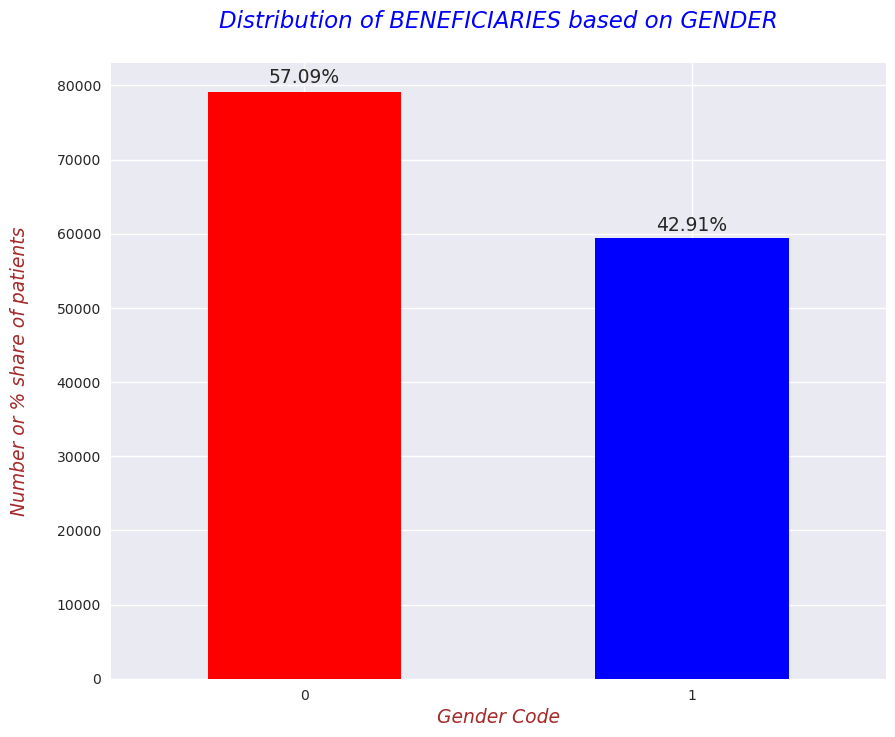

In [12]:
# Here, I'm displaying the distribution of BENEFICIARIES on the basis of GENDER 
with plt.style.context('seaborn'):
    plt.figure(figsize=(10,8))
    fig = bene_train_df['Gender'].value_counts().plot(kind='bar', color=['red','blue'])
    for p in fig.patches:
        width = p.get_width()
        height = p.get_height()
        x, y = p.get_xy()
        fig.annotate(f'{str(round((height*100)/bene_train_df.shape[0],2))+"%"}', (x + width/2, y + height*1.015),  fontsize=13.5, ha = 'center')

    plt.xlabel("Gender Code", fontdict=label_font_dict)
    plt.xticks(rotation=0)
    plt.ylabel("Number or % share of patients\n", fontdict=label_font_dict)
    plt.title("Distribution of BENEFICIARIES based on GENDER\n", fontdict=title_font_dict)
plt.show()

**Q3. Lets calculate the AGE of every BENEFICIARY?**

In [13]:
bene_train_df['DOB'] = pd.to_datetime(bene_train_df['DOB'], format="%Y-%m-%d")

In [14]:
bene_train_df['Patient_Age_Year'] = bene_train_df['DOB'].dt.year
bene_train_df['Patient_Age_Month'] = bene_train_df['DOB'].dt.month

**Adding new feature :::::::::::::::::::::::: "YEAR of birth of beneficiaries"**

In [15]:
bene_age_year_df = pd.DataFrame(bene_train_df['Patient_Age_Year'].value_counts()).reset_index(drop=False)
bene_age_year_df.columns= ['year','num_of_beneficiaries']
bene_age_year_df = bene_age_year_df.sort_values(by='year')
bene_age_year_df

,year,num_of_beneficiaries
35,1909,769
45,1910,717
47,1911,713
42,1912,725
37,1913,754
...,...,...
73,1979,169
69,1980,199
68,1981,204
71,1982,193


In [16]:
bene_train_df.head()

,BeneID,DOB,DOD,Gender,Race,RenalDiseaseIndicator,State,County,NoOfMonths_PartACov,NoOfMonths_PartBCov,ChronicCond_Alzheimer,ChronicCond_Heartfailure,ChronicCond_KidneyDisease,ChronicCond_Cancer,ChronicCond_ObstrPulmonary,ChronicCond_Depression,ChronicCond_Diabetes,ChronicCond_IschemicHeart,ChronicCond_Osteoporasis,ChronicCond_rheumatoidarthritis,ChronicCond_stroke,IPAnnualReimbursementAmt,IPAnnualDeductibleAmt,OPAnnualReimbursementAmt,OPAnnualDeductibleAmt,Patient_Age_Year,Patient_Age_Month
0,BENE11001,1943-01-01,NaN,1,1,0,39,230,12,12,1,2,1,2,2,1,1,1,2,1,1,36000,3204,60,70,1943,1
1,BENE11002,1936-09-01,NaN,0,1,0,39,280,12,12,2,2,2,2,2,2,2,2,2,2,2,0,0,30,50,1936,9
2,BENE11003,1936-08-01,NaN,1,1,0,52,590,12,12,1,2,2,2,2,2,2,1,2,2,2,0,0,90,40,1936,8
3,BENE11004,1922-07-01,NaN,1,1,0,39,270,12,12,1,1,2,2,2,2,1,1,1,1,2,0,0,1810,760,1922,7
4,BENE11005,1935-09-01,NaN,1,1,0,24,680,12,12,2,2,2,2,1,2,1,2,2,2,2,0,0,1790,1200,1935,9


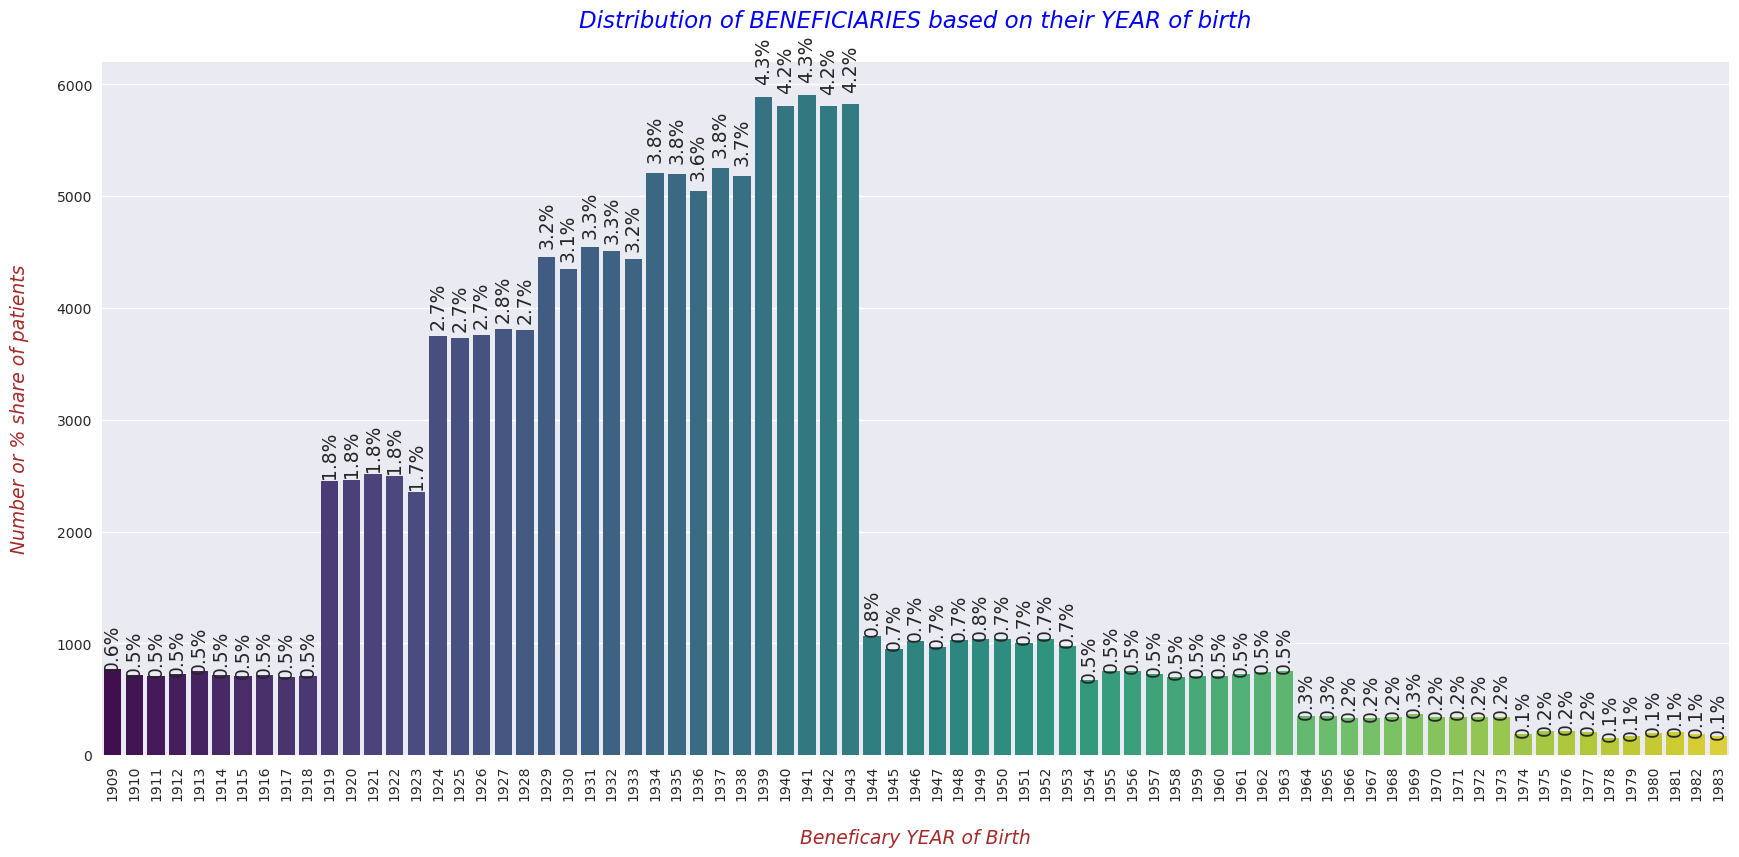

In [17]:
with plt.style.context('seaborn'):
  plt.figure(figsize=(21,9))
  fig = sns.barplot(data=bene_age_year_df, x='year', y='num_of_beneficiaries', palette='viridis')
  for p in fig.patches:
    width = p.get_width()
    height = p.get_height()
    x, y = p.get_xy()
    fig.annotate(f'{str(round((height*100)/bene_train_df.shape[0],1))+"%"}', (x + width/2, y + height*1.025), ha='center', fontsize=13.5, rotation=90)
  plt.xlabel("\nBeneficary YEAR of Birth", fontdict=label_font_dict)
  plt.xticks(rotation=90)
  plt.ylabel("Number or % share of patients\n", fontdict=label_font_dict)
  plt.title("Distribution of BENEFICIARIES based on their YEAR of birth\n", fontdict=title_font_dict)
plt.show()

OBERVATION

From the above plot, we can decude that the majority of the beneficiaries are from the YEAR - 1919 to 1943.
More specifically, overall the percentage of number of beneficiaries with YEAR of birth from 1939 to 1943 is the highest. Whereas, it is lowest from 1978 to 1983.

REASONING

The reason for adding the "YEAR of Birth of Beneficiaries" as a new feature in the dataset with the intent to find whether personal details has been forged by the beneficiary or its direct/indirect association with Fraud claims.

**Adding new feature :::::::::::::::::::::::: "MONTH of birth of beneficiaries"**

In [18]:
bene_age_month_df = pd.DataFrame(bene_train_df['Patient_Age_Month'].value_counts()).reset_index(drop=False)
bene_age_month_df.columns= ['month','num_of_beneficiaries']
bene_age_month_df = bene_age_month_df.sort_values(by='month')

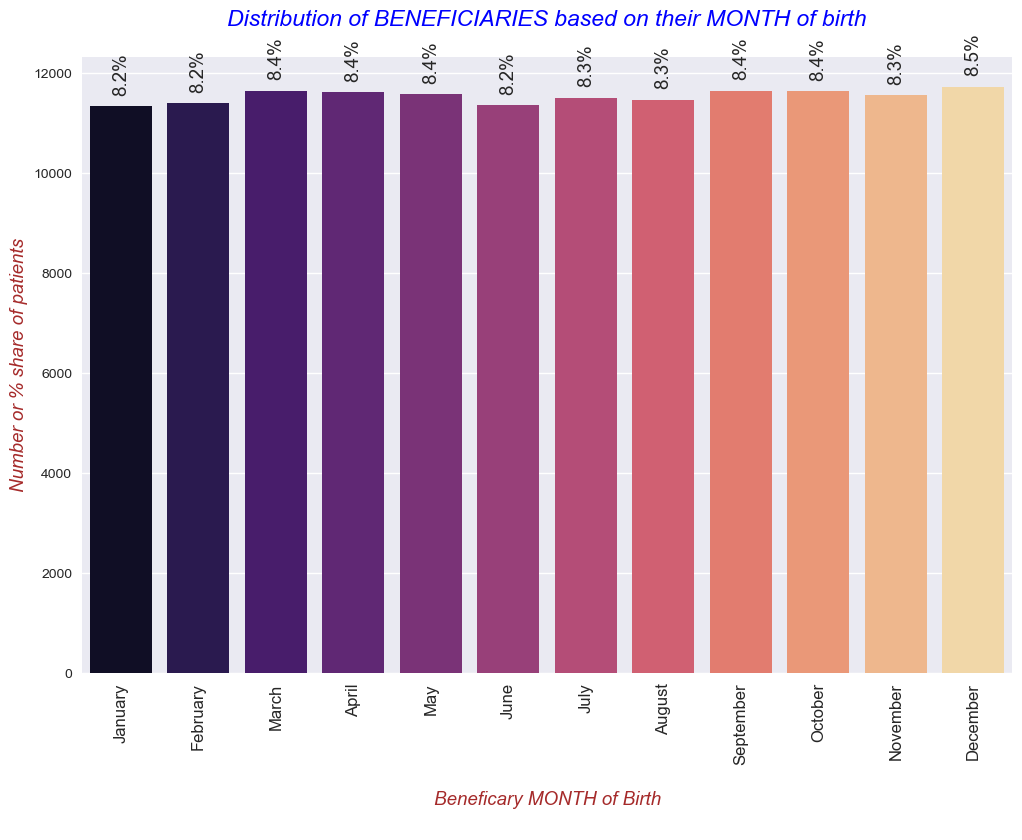

In [19]:
import calendar
months = list(calendar.month_name)[1:]
    
with plt.style.context('seaborn'):
  plt.figure(figsize=(12,8))
  fig = sns.barplot(data=bene_age_month_df, x='month', y='num_of_beneficiaries', palette='magma')
  for p in fig.patches:
    width = p.get_width()
    height = p.get_height()
    x, y = p.get_xy()
    fig.annotate(f'{str(round((height*100)/bene_train_df.shape[0],1))+"%"}', (x + width/2, y + height*1.025), ha='center', fontsize=13.5, rotation=90)
  plt.xlabel("\nBeneficary MONTH of Birth\n", fontdict=label_font_dict)
  plt.xticks(labels= months,ticks = range(0,12), rotation=90, fontsize=12)
  plt.ylabel("Number or % share of patients", fontdict=label_font_dict)
  plt.title("Distribution of BENEFICIARIES based on their MONTH of birth\n", fontdict=title_font_dict)
  plt.show()

OBERVATION

From the above plot, we can decude that there is no such difference b/w the patients based on their MONTH of birth.
Initial, look suggests me that this feature might not be more of a use.
REASONING

The reason for adding the "MONTH of Birth of Beneficiaries" as a new feature in the dataset with the intent to find whether personal details has been forged by the beneficiary or its direct/indirect association with Fraud claims.

In [20]:
bene_train_df.head()

,BeneID,DOB,DOD,Gender,Race,RenalDiseaseIndicator,State,County,NoOfMonths_PartACov,NoOfMonths_PartBCov,ChronicCond_Alzheimer,ChronicCond_Heartfailure,ChronicCond_KidneyDisease,ChronicCond_Cancer,ChronicCond_ObstrPulmonary,ChronicCond_Depression,ChronicCond_Diabetes,ChronicCond_IschemicHeart,ChronicCond_Osteoporasis,ChronicCond_rheumatoidarthritis,ChronicCond_stroke,IPAnnualReimbursementAmt,IPAnnualDeductibleAmt,OPAnnualReimbursementAmt,OPAnnualDeductibleAmt,Patient_Age_Year,Patient_Age_Month
0,BENE11001,1943-01-01,NaN,1,1,0,39,230,12,12,1,2,1,2,2,1,1,1,2,1,1,36000,3204,60,70,1943,1
1,BENE11002,1936-09-01,NaN,0,1,0,39,280,12,12,2,2,2,2,2,2,2,2,2,2,2,0,0,30,50,1936,9
2,BENE11003,1936-08-01,NaN,1,1,0,52,590,12,12,1,2,2,2,2,2,2,1,2,2,2,0,0,90,40,1936,8
3,BENE11004,1922-07-01,NaN,1,1,0,39,270,12,12,1,1,2,2,2,2,1,1,1,1,2,0,0,1810,760,1922,7
4,BENE11005,1935-09-01,NaN,1,1,0,24,680,12,12,2,2,2,2,1,2,1,2,2,2,2,0,0,1790,1200,1935,9


* **`Adding new indicator`** <::::::::::::::::::::::::> **"`Beneficiary Dead or Alive?`"**
  * This represent whether a patient is alive or not?
    * Here, the point to understand is that there can be ONE to MANY relationship b/w a BENEFICIARY and CLAIM filed, thus I'm making an assumption here is that beneficiaries with DOD as NA are alive, however this cannot be  always true once we join it with CLAIMS data.
      * For example, A patient gets successfully operated for Kidney Failure on Sep 2012 and filed CLAIM-I. So, this claimed gets approved with DOD as NA. 
        * Same patient gets operated after 4 months for Cardiac Failure but couldn't survived and filed CLAIM-II. Thus, for CLAIM-I this person shoud have DEAD_or_ALIVE indicator as FALSE whereas for CLAIM-II it should be TRUE.


* **`REASONING`**
  * My intention behind adding this feature is to see whether FRAUD claims are higher for DEAD patients or not? 
    * The reason here is that generally when an organized fraud happens then healthcare providers falsely diagnose, misdiagnose, or overdiagnose a disease, which can lead to harmful courses of medication or treatments or procedures being prescribed or performed. All of this together can lead to patient death.

In [21]:
# 0 means ALIVE and 1 means DEAD
bene_train_df['Dead_or_Alive'] = bene_train_df['DOD'].apply(lambda val: 0 if val != val else 1)

In [22]:
bene_train_df['Dead_or_Alive'].value_counts()

0    137135
1      1421
Name: Dead_or_Alive, dtype: int64

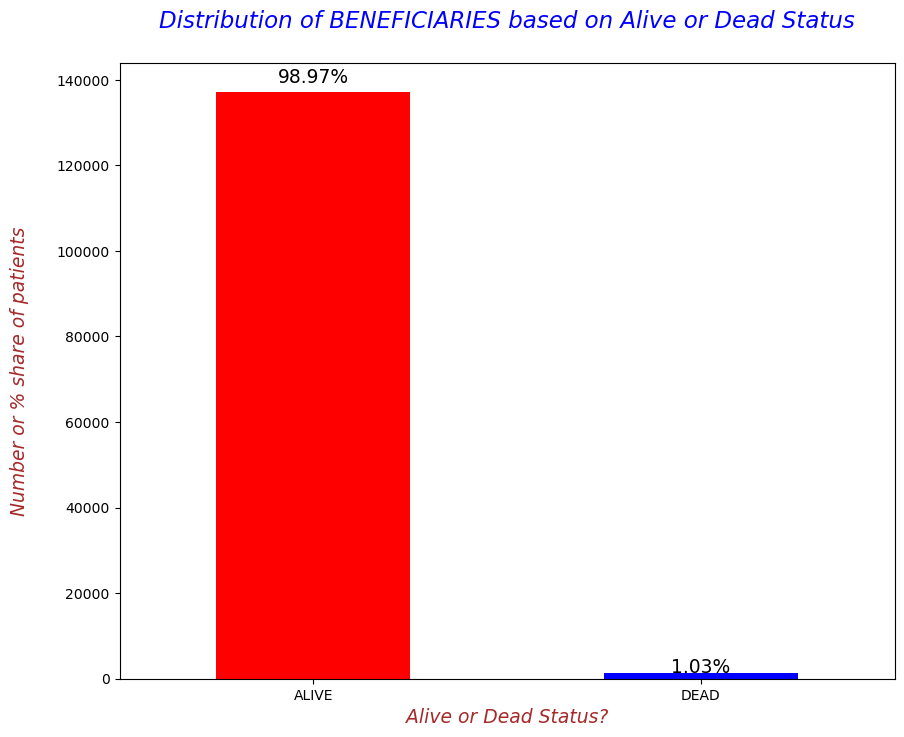

In [23]:
plt.figure(figsize=(10,8))
fig = bene_train_df['Dead_or_Alive'].value_counts().plot(kind='bar', color=['red','blue'])
for p in fig.patches:
    width = p.get_width()
    height = p.get_height()
    x, y = p.get_xy()
    fig.annotate(f'{str(round((height*100)/bene_train_df.shape[0],2))+"%"}', (x + width/2, y + height*1.015), ha='center', fontsize=13.5)
plt.xlabel("Alive or Dead Status?", fontdict=label_font_dict)
plt.xticks(labels=["ALIVE","DEAD"], ticks=[0,1],rotation = 0)
plt.ylabel("Number or % share of patients\n", fontdict=label_font_dict)
plt.title("Distribution of BENEFICIARIES based on Alive or Dead Status\n", fontdict=title_font_dict)
plt.show()

- **`OBSERVATION`**
  - The above graph tells us that almost 99% of the beneficiaries are ALIVE and very small percentage of patients are DEAD. It would be good to see how much this feature has impact on the actual label.

In [24]:
bene_train_df['DOD'] = pd.to_datetime(bene_train_df['DOD'])

In [25]:
# Greatest Date of Death in the TRAIN set for beneficiaries
max_bene_DOD = max(bene_train_df['DOD'].unique()[1:])
max_bene_DOD

numpy.datetime64('2009-12-01T00:00:00.000000000')

In [26]:
# For all NAN DODs filling the greatest Date of Death
bene_train_df['DOD'].fillna(value=max_bene_DOD, inplace=True)

In [27]:
bene_train_df['DOD']

0        2009-12-01
1        2009-12-01
2        2009-12-01
3        2009-12-01
4        2009-12-01
            ...    
138551   2009-12-01
138552   2009-12-01
138553   2009-12-01
138554   2009-12-01
138555   2009-12-01
Name: DOD, Length: 138556, dtype: datetime64[ns]

* **`Adding new feature`** <::::::::::::::::::::::::> **"`Beneficiary AGE`"**
  * This represent the AGE of the beneficiary.


* **`REASONING`**
  * My intention behind adding this feature is to better analyse the CLAIM and Patient related data.

In [28]:
bene_train_df['AGE'] = np.round(((bene_train_df['DOD'] - bene_train_df['DOB']).dt.days)/365.0,1)


In [29]:
bene_train_df.drop(labels=['DOD'],axis=1,inplace=True)

In [30]:
bene_train_df.head()

,BeneID,DOB,Gender,Race,RenalDiseaseIndicator,State,County,NoOfMonths_PartACov,NoOfMonths_PartBCov,ChronicCond_Alzheimer,ChronicCond_Heartfailure,ChronicCond_KidneyDisease,ChronicCond_Cancer,ChronicCond_ObstrPulmonary,ChronicCond_Depression,ChronicCond_Diabetes,ChronicCond_IschemicHeart,ChronicCond_Osteoporasis,ChronicCond_rheumatoidarthritis,ChronicCond_stroke,IPAnnualReimbursementAmt,IPAnnualDeductibleAmt,OPAnnualReimbursementAmt,OPAnnualDeductibleAmt,Patient_Age_Year,Patient_Age_Month,Dead_or_Alive,AGE
0,BENE11001,1943-01-01,1,1,0,39,230,12,12,1,2,1,2,2,1,1,1,2,1,1,36000,3204,60,70,1943,1,0,67.0
1,BENE11002,1936-09-01,0,1,0,39,280,12,12,2,2,2,2,2,2,2,2,2,2,2,0,0,30,50,1936,9,0,73.3
2,BENE11003,1936-08-01,1,1,0,52,590,12,12,1,2,2,2,2,2,2,1,2,2,2,0,0,90,40,1936,8,0,73.4
3,BENE11004,1922-07-01,1,1,0,39,270,12,12,1,1,2,2,2,2,1,1,1,1,2,0,0,1810,760,1922,7,0,87.5
4,BENE11005,1935-09-01,1,1,0,24,680,12,12,2,2,2,2,1,2,1,2,2,2,2,0,0,1790,1200,1935,9,0,74.3


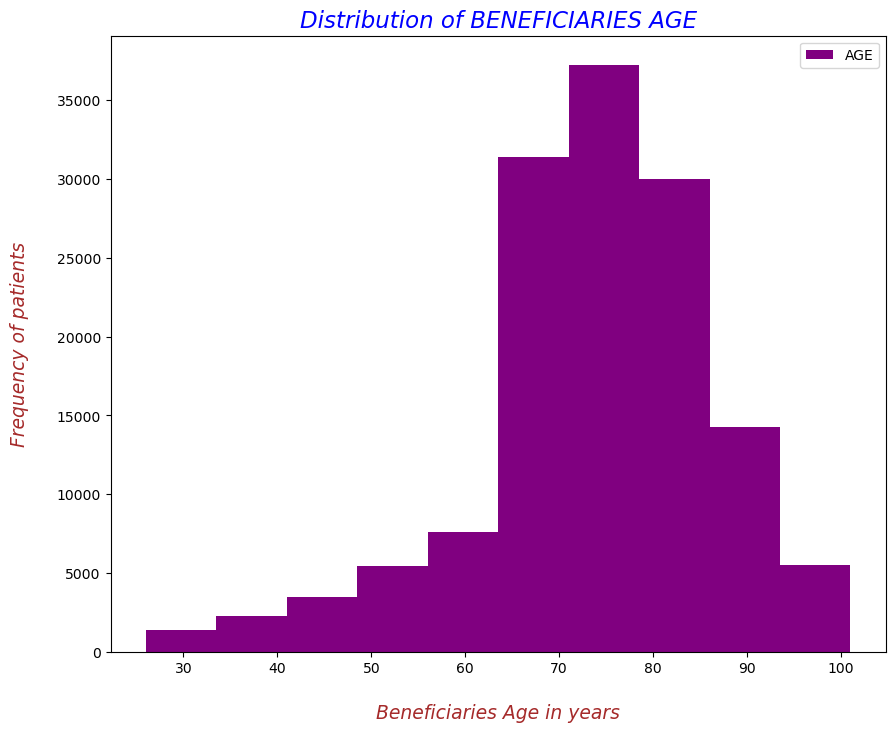

In [31]:
plt.figure(figsize=(10,8))
bene_train_df['AGE'].plot(kind='hist', color='purple')
plt.xlabel("\nBeneficiaries Age in years", fontdict=label_font_dict)
plt.ylabel("Frequency of patients\n", fontdict=label_font_dict)
plt.title("Distribution of BENEFICIARIES AGE", fontdict=title_font_dict)
plt.legend()
plt.show()

- **`OBSERVATION`**
  - The above graph tells us that the majority of the beneficiaries are b/w 65 to 85 years.

In [32]:
bene_train_df['AGE'].describe()

count    138556.000000
mean         73.632756
std          12.736605
min          26.000000
25%          68.000000
50%          74.300000
75%          82.000000
max         101.000000
Name: AGE, dtype: float64

* **`Adding new categorical column`** <::::::::::::::::::::::::> **"`Beneficiary AGE brackets`"**
  * This will represent whether a patient falls in a specific AGE bracket?
    * [1-40] --> Group 1 --> Young
    * (40-60] --> Group 2 --> Mid Aged
    * (60-80] --> Group 3 --> Old 
    * (80 or more] --> Group 4 --> Very Old


* **`REASONING`**
  * My intention behind adding this feature is to see whether FRAUD claims are higher for specific AGE Groups?
    * The reasoning here is that there may be a potential pattern that providers files higher number of FRAUD claims for either a younger age group or very old age group.

In [33]:
def bene_age_brackets(val):
  if val >=1 and val <=40:
    return 'Young'
  elif val > 40 and val <=60:
    return 'Mid'
  elif val > 60 and val <= 80:
    return 'Old'
  else:
    return 'Very Old'

In [34]:
bene_train_df['AGE_groups'] = bene_train_df['AGE'].apply(lambda age: bene_age_brackets(age))

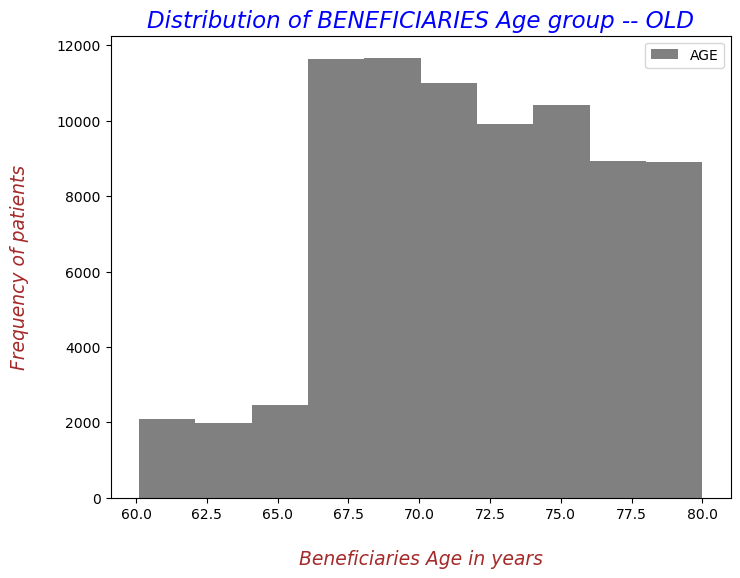

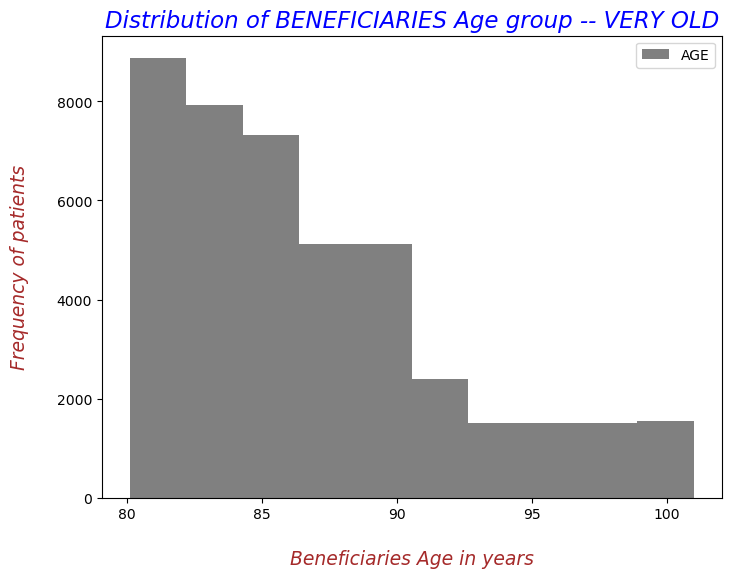

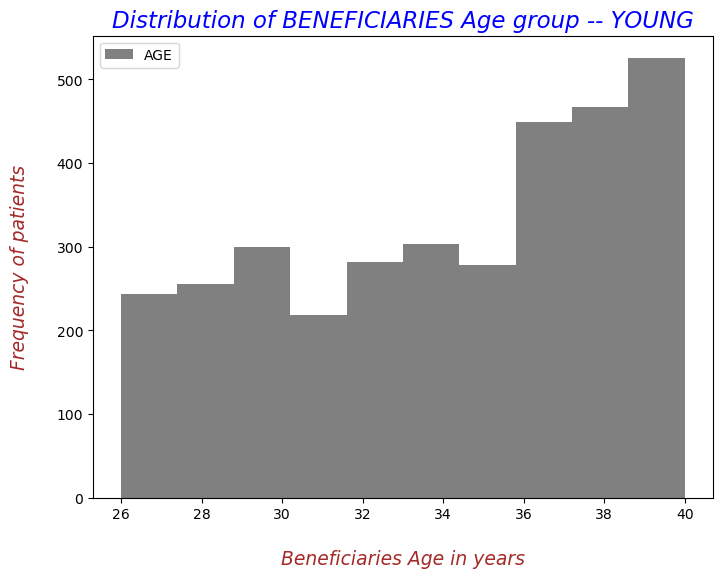

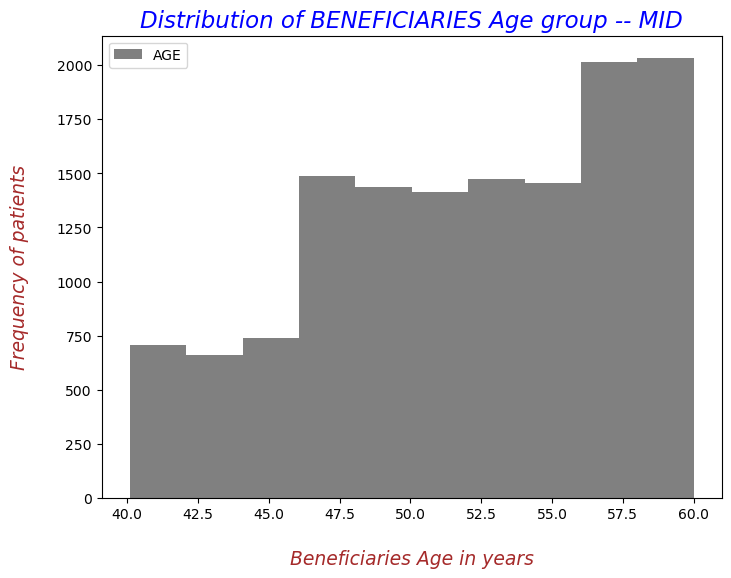

In [35]:
age_grps = list(bene_train_df['AGE_groups'].unique())
for grp in age_grps:
 
    plt.figure(figsize=(8,6))
    bene_train_df[bene_train_df['AGE_groups'] == grp]['AGE'].plot(kind='hist', color='grey')
    plt.xlabel("\nBeneficiaries Age in years", fontdict=label_font_dict)
    plt.ylabel("Frequency of patients\n", fontdict=label_font_dict)
    plt.title("Distribution of BENEFICIARIES Age group -- {}".format(str(grp).upper()), fontdict=title_font_dict)
    plt.legend()
    plt.show()

- **`OBSERVATION`**
  - The above graphs tells us about the spread of beneficiaries across the Age Groups.
    - For YOUNG group we can say that the spread is quite even across the ages of beneficiaries.

### **Q4. Lets see the ratio of GENDER across various HUMAN RACE?**

*  **The world population can be divided into 4 major races:**
  * white/Caucasian 
  * Mongoloid/Asian
  * Negroid/Black
  * Australoid. 



In [36]:
bene_train_df['Race'].unique()

array([1, 2, 3, 5], dtype=int64)

In [37]:
bene_train_df['Race'].replace(5,4,inplace = True)

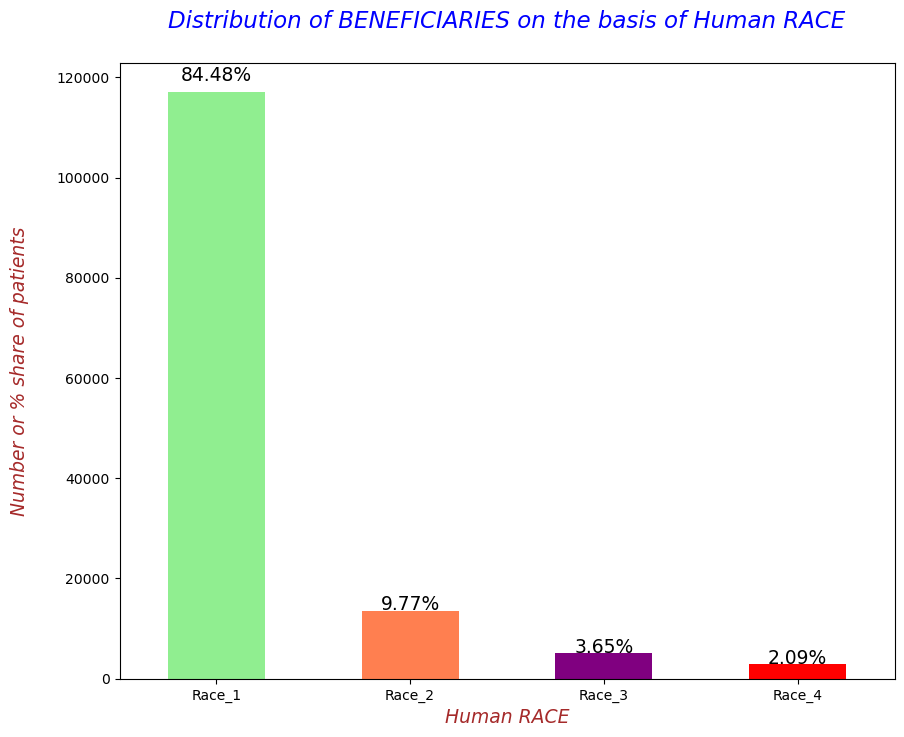

In [38]:
plt.figure(figsize=(10,8))
fig = bene_train_df['Race'].value_counts().plot(kind='bar', color=['lightgreen','coral','purple','red'])

for p in fig.patches:
    width = p.get_width()
    height = p.get_height()
    x, y = p.get_xy()
    fig.annotate(f'{str(round((height*100)/bene_train_df.shape[0],2))+"%"}', (x + width/2, y + height*1.02), ha='center', fontsize=13.5)

plt.xlabel("Human RACE", fontdict=label_font_dict)
plt.xticks(labels=["Race_1","Race_2","Race_3","Race_4"], ticks=[0,1,2,3], rotation=0)
plt.ylabel("Number or % share of patients\n", fontdict=label_font_dict)
plt.title("Distribution of BENEFICIARIES on the basis of Human RACE\n", fontdict=title_font_dict)
plt.show()

- **`OBSERVATION`**
  - The above graph tells us that there is a serious imbalance in the records for Human Race categories.

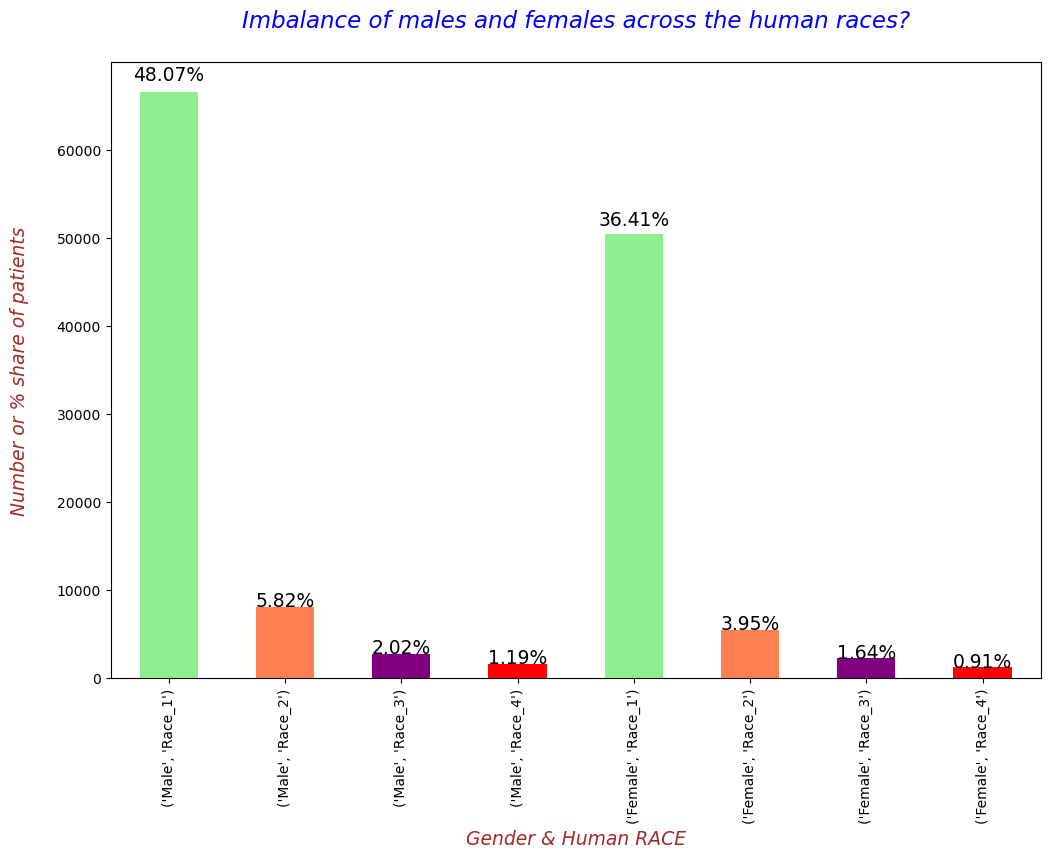

In [39]:
plt.figure(figsize=(12,8))
fig = bene_train_df.groupby(['Gender','Race'])['AGE'].count().plot(kind='bar', color=['lightgreen','coral','purple','red','lightgreen','coral','purple','red'])
for p in fig.patches:
    width = p.get_width()
    height = p.get_height()
    x, y = p.get_xy()
    fig.annotate(f'{str(round((height*100)/bene_train_df.shape[0],2))+"%"}', (x + width/2, y + height*1.02), ha='center', fontsize=13.5)

plt.xlabel("Gender & Human RACE", fontdict=label_font_dict)
plt.xticks(labels=[("Male","Race_1"), ("Male","Race_2"), ("Male","Race_3"), ("Male","Race_4"),("Female","Race_1"), ("Female","Race_2"), ("Female","Race_3"), ("Female","Race_4")],
         ticks=[0,1,2,3,4,5,6,7], rotation=90)
plt.ylabel("Number or % share of patients\n", fontdict=label_font_dict)
plt.title("Imbalance of males and females across the human races?\n", fontdict=title_font_dict)
plt.show()

- **`OBSERVATION`**
  - The above graph shows us whether we have an imbalance of males or females across the human races. 
    - And, it looks like within a specific human race there is no such gender imbalance.

### **Q5. Lets see the number of beneficiaries with Chronic Renal Disease.**

*  There are two main types of kidney disease - short-term (acute kidney injury) and lifelong (chronic).

*  The two main types of kidney disease are short-term (acute kidney injury) and lifelong (chronic kidney disease).
  *  Chronic kidney disease, also known as chronic renal disease or CKD, is a condition characterized by a gradual loss of kidney function over time.

* **What are the main causes of chronic kidney disease?**
  * Diabetes and high blood pressure, or hypertension, are responsible for two-thirds of chronic kidney disease cases.



In [40]:
bene_train_df['RenalDiseaseIndicator'] = bene_train_df['RenalDiseaseIndicator'].map({'0':'No','Y':'Yes'})

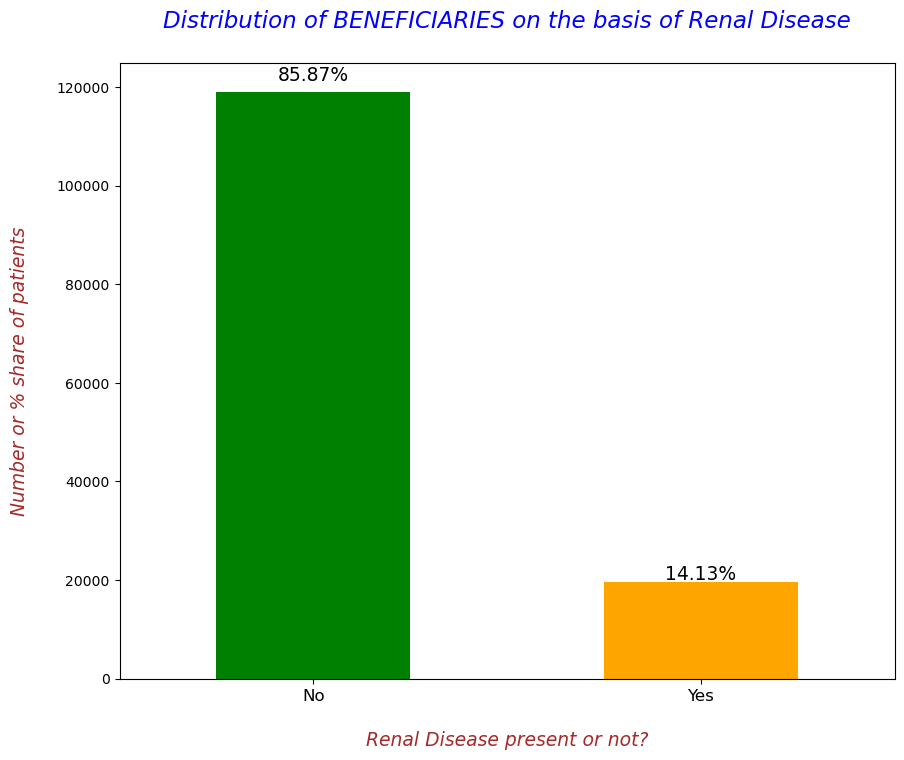

     RenalDiseaseIndicator
No                  118978
Yes                  19578 



In [41]:
plt.figure(figsize=(10,8))
fig = bene_train_df['RenalDiseaseIndicator'].value_counts().plot(kind='bar', color=['green','orange'])
for p in fig.patches:
    width = p.get_width()
    height = p.get_height()
    x, y = p.get_xy()
    fig.annotate(f'{str(round((height*100)/bene_train_df.shape[0],2))+"%"}', (x + width/2, y + height*1.02), ha='center', fontsize=13.5, rotation=0)
plt.xlabel("\nRenal Disease present or not?", fontdict=label_font_dict)
plt.xticks( ticks=[0,1], rotation=0, size=12)
plt.ylabel("Number or % share of patients\n", fontdict=label_font_dict)
plt.title("Distribution of BENEFICIARIES on the basis of Renal Disease\n", fontdict=title_font_dict)
plt.show()

# 0 means NO and 1 means YES
print(pd.DataFrame(bene_train_df['RenalDiseaseIndicator'].value_counts()),"\n")

- **`OBSERVATION`**
  - Above graph tells us that around 14% of beneficiaries has or had Kidney Failure(Renal Disease).

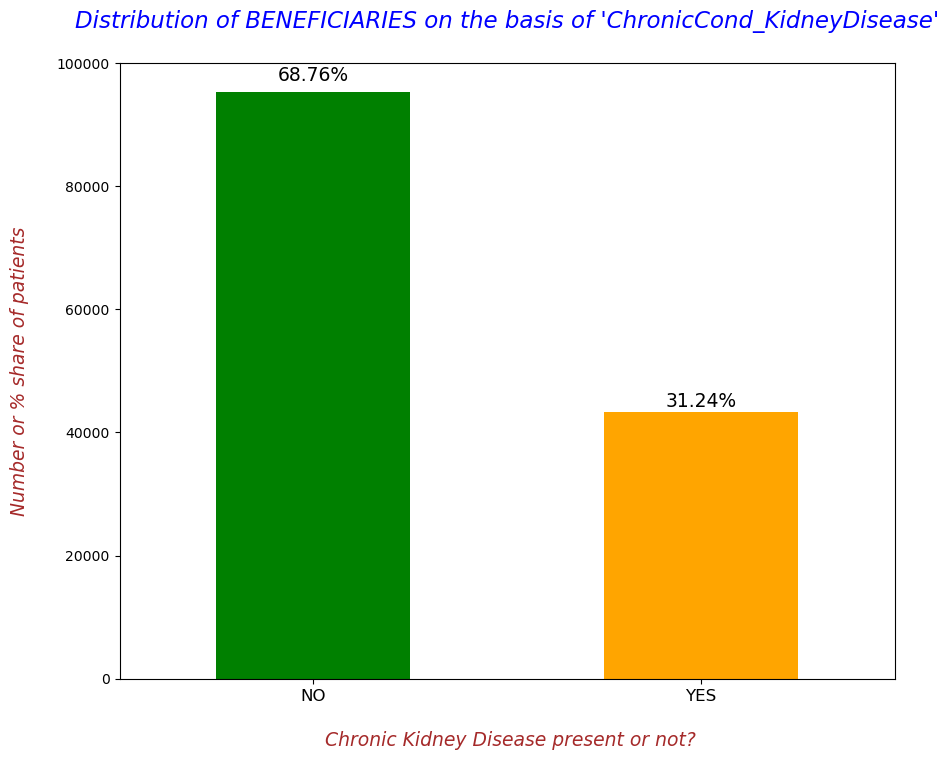

   ChronicCond_KidneyDisease
2                      95277
1                      43279 



In [42]:
plt.figure(figsize=(10,8))
fig = bene_train_df['ChronicCond_KidneyDisease'].value_counts().plot(kind='bar', color=['green','orange'])
for p in fig.patches:
    width = p.get_width()
    height = p.get_height()
    x, y = p.get_xy()
    fig.annotate(f'{str(round((height*100)/bene_train_df.shape[0],2))+"%"}', (x + width/2, y + height*1.02), ha='center', fontsize=13.5, rotation=0)
plt.xlabel("\n Chronic Kidney Disease present or not?", fontdict=label_font_dict)
plt.xticks(labels=["NO","YES"], ticks=[0,1], rotation=0, size=12)
plt.ylabel("Number or % share of patients\n", fontdict=label_font_dict)
plt.title("Distribution of BENEFICIARIES on the basis of 'ChronicCond_KidneyDisease'\n", fontdict=title_font_dict)
plt.show()

# I believe 2 means NO and 1 means YES
print(pd.DataFrame(bene_train_df['ChronicCond_KidneyDisease'].value_counts()),'\n')

- **`OBSERVATION`**
  - Above graph tells us that around 31% of Beneficiaries had Chronic Kidney Disease.

* In the beneficiary dataset, we have 2 columns:
  * RenalDisease
  * ChronicCond_KidneyDisease
Both of these columns appears to be representing the beneficiary history about the kidney disease.

It looks they have RenalDisease indicator to represent whether the beneficiary has or had Kidney Failure.
And, ChronicCond_KidneyDisease represents the long term Kidney Disease may be like not functioning to the fullest.

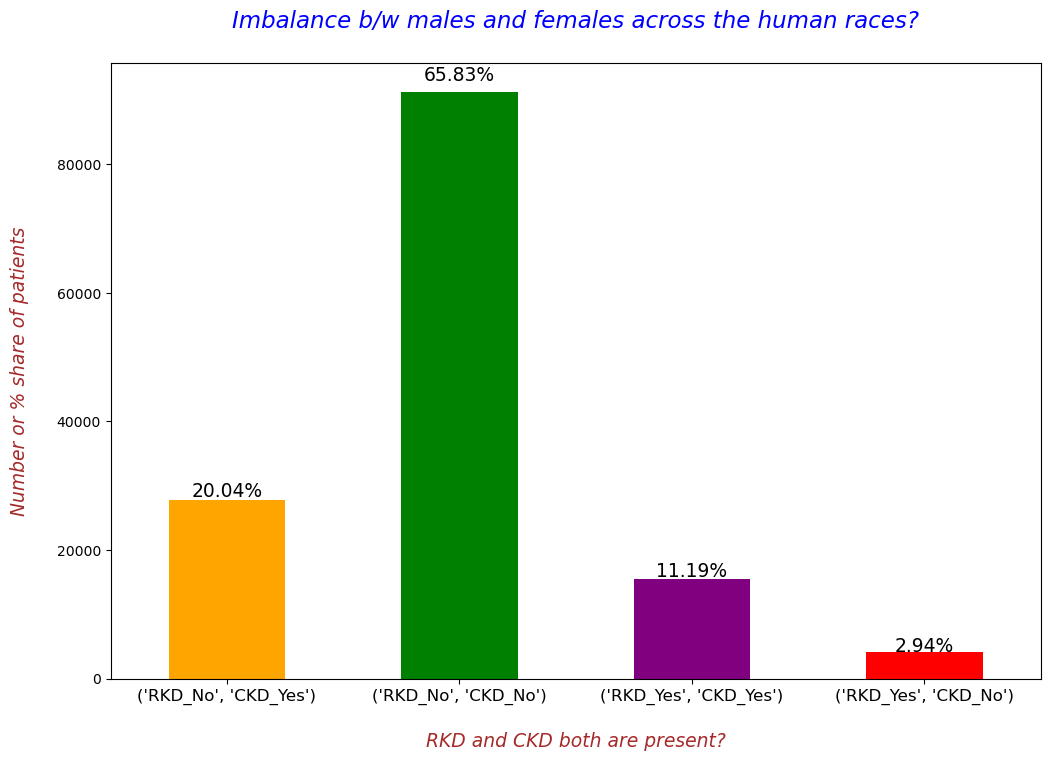

                                                 Gender
RenalDiseaseIndicator ChronicCond_KidneyDisease        
No                    1                           27768
                      2                           91210
Yes                   1                           15511
                      2                            4067 



In [43]:
plt.figure(figsize=(12,8))
fig = bene_train_df.groupby(['RenalDiseaseIndicator','ChronicCond_KidneyDisease'])['Gender'].count().plot(kind='bar', color=['orange','green','purple','red'])
for p in fig.patches:
    width = p.get_width()
    height = p.get_height()
    x, y = p.get_xy()
    fig.annotate(f'{str(round((height*100)/bene_train_df.shape[0],2))+"%"}', (x + width/2, y + height*1.02), ha='center', fontsize=13.5)

plt.xlabel("\nRKD and CKD both are present?", fontdict=label_font_dict)
plt.xticks(labels=[("RKD_No","CKD_Yes"), ("RKD_No","CKD_No"), ("RKD_Yes","CKD_Yes"), ("RKD_Yes","CKD_No")], ticks=[0,1,2,3], rotation=0, size=12)
plt.ylabel("Number or % share of patients\n", fontdict=label_font_dict)
plt.title("Imbalance b/w males and females across the human races?\n", fontdict=title_font_dict)
plt.show()

# RKD --> Renal Disease Indicator
# CKD --> Chronic Condition Kidney Disease
print(pd.DataFrame(bene_train_df.groupby(['RenalDiseaseIndicator','ChronicCond_KidneyDisease'])['Gender'].count()),"\n")

- **`OBSERVATION`**
  - In the above, we came to know that 2.94% of beneficiaries had no previously CKD but suffered from RKD. It would be good to check how many out these end-up as FRAUD claims.

### **Q6. Lets see the number of beneficiaries on the basis of State Codes.**

In [44]:
bene_train_df['State'].unique()

array([39, 52, 24, 23, 45, 15, 44, 41,  1, 14,  7, 13, 34, 31,  5, 49, 46,
        6, 38, 10, 26,  3, 20, 33, 18, 27, 51, 29, 42, 36, 11, 12, 30, 19,
        4, 25, 17, 16, 32,  2, 21, 50, 22, 54, 28, 43, 35, 37, 47,  8,  9,
       53], dtype=int64)

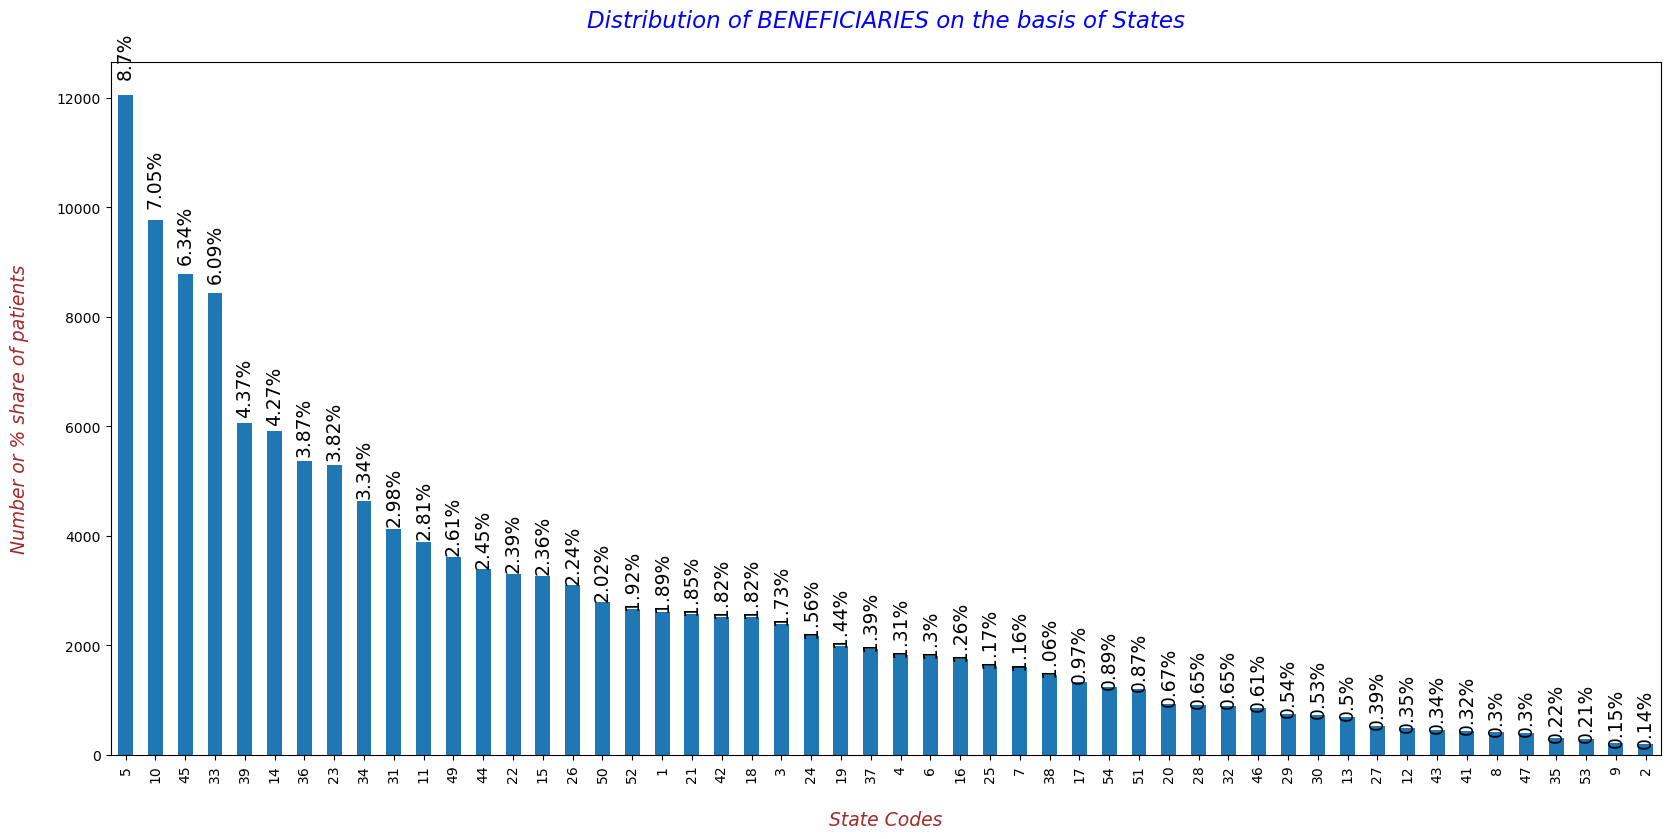

In [45]:
plt.figure(figsize=(20,9))
fig = bene_train_df['State'].value_counts().plot(kind='bar')
for p in fig.patches:
    width = p.get_width()
    height = p.get_height()
    x, y = p.get_xy()
    fig.annotate(f'{str(round((height*100)/bene_train_df.shape[0],2))+"%"}', (x + width/2, y + height*1.03), ha='center', fontsize=13.5, rotation=90)

plt.xlabel("\nState Codes", fontdict=label_font_dict)
plt.ylabel("Number or % share of patients\n", fontdict=label_font_dict)
plt.title("Distribution of BENEFICIARIES on the basis of States\n", fontdict=title_font_dict)
plt.show()

- **`OBSERVATION`**
  - The above graph shows us that for some States the number of beneficiaries are more as compared to the others. And, the maximum number of beneficiaries are from State-5.

### **Q7. Lets see the number of beneficiaries on the basis of Country Codes.**

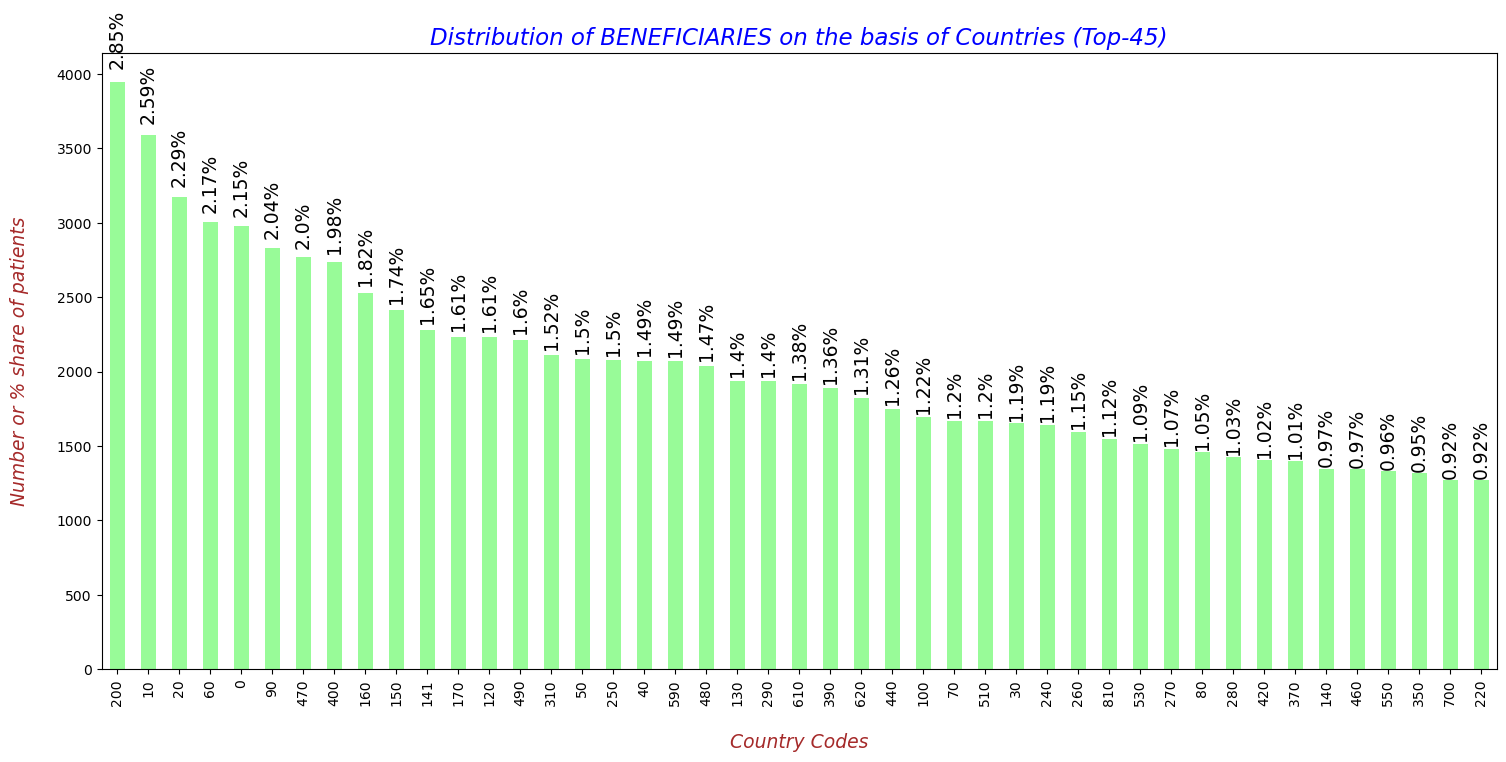

In [46]:
plt.figure(figsize=(18,8))
fig = bene_train_df['County'].value_counts()[0:45].plot(kind='bar', color='palegreen')
for p in fig.patches:
    width = p.get_width()
    height = p.get_height()
    x, y = p.get_xy()
    fig.annotate(f'{str(round((height*100)/bene_train_df.shape[0],2))+"%"}', (x + width/2, y + height*1.03), ha='center', fontsize=13.5, rotation=90)

plt.xlabel("\nCountry Codes", fontdict=label_font_dict)
plt.ylabel("Number or % share of patients\n", fontdict=label_font_dict)
plt.title("Distribution of BENEFICIARIES on the basis of Countries (Top-45)", fontdict=title_font_dict)
plt.show()

In [47]:
# Countries with only handful of beneficiaries
bene_train_df['County'].value_counts()[::-1][0:45]

521    1
753    1
834    1
117    1
742    1
804    1
944    1
744    1
796    1
14     2
84     2
875    2
691    2
912    2
904    2
712    2
873    3
672    3
876    3
1      3
785    3
412    3
844    3
632    3
161    3
955    3
862    3
793    3
662    4
887    4
612    4
893    4
34     4
583    4
755    4
931    4
903    4
878    5
292    5
542    5
271    5
797    5
784    5
562    5
431    5
Name: County, dtype: int64

- **`OBSERVATION`**
  - The above graph shows us that distribution of beneficiaries based upon the country codes. Some having very high number of beneficiaries and others have very less.

- **`NOTE`**
  - One thing still needs to be evaluated that whether some specific state or country code has higher number of frauds?

### **Q8.1 Lets see the number of beneficiaries on the basis of 'NoOfMonths_PartACov'.**

In [48]:
bene_train_df['NoOfMonths_PartACov'].unique()

array([12,  0,  3,  7, 10, 11,  8,  4,  1,  6,  2,  9,  5], dtype=int64)

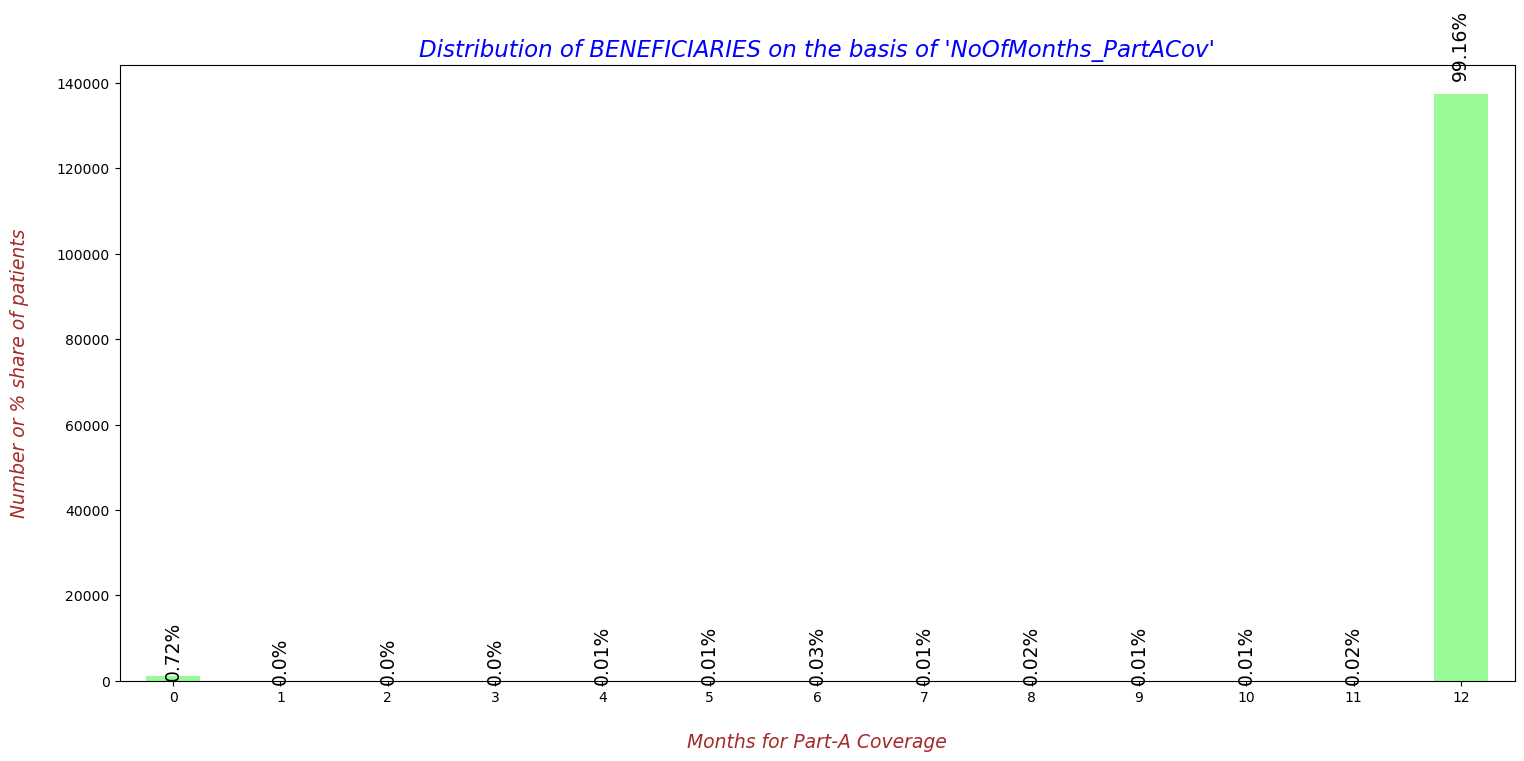

In [49]:
plt.figure(figsize=(18,8))
fig = bene_train_df['NoOfMonths_PartACov'].value_counts().sort_index().plot(kind='bar', color='palegreen')
for p in fig.patches:
    width = p.get_width()
    height = p.get_height()
    x, y = p.get_xy()
    fig.annotate(f'{str(round((height*100)/bene_train_df.shape[0],2))+"%"}', (x + width/2, y + height*1.03), ha='center', fontsize=13.5, rotation=90)

plt.xlabel("\nMonths for Part-A Coverage", fontdict=label_font_dict)
plt.xticks(rotation = 0)
plt.ylabel("Number or % share of patients\n", fontdict=label_font_dict)
plt.title("Distribution of BENEFICIARIES on the basis of 'NoOfMonths_PartACov'", fontdict=title_font_dict)
plt.show()

- **`OBSERVATION`**
  - The above graph shows us that more than 99% of beneficiaries have 12 months Part-A Coverage. My initial look to above plot tells me that this feature won't have much impact on the tgt labels.

### **Q8.2 Lets see the number of beneficiaries on the basis of 'NoOfMonths_PartBCov'.**

In [50]:
bene_train_df['NoOfMonths_PartBCov'].unique()

array([12,  0,  1,  9, 11,  3, 10,  8,  2,  6,  4,  5,  7], dtype=int64)

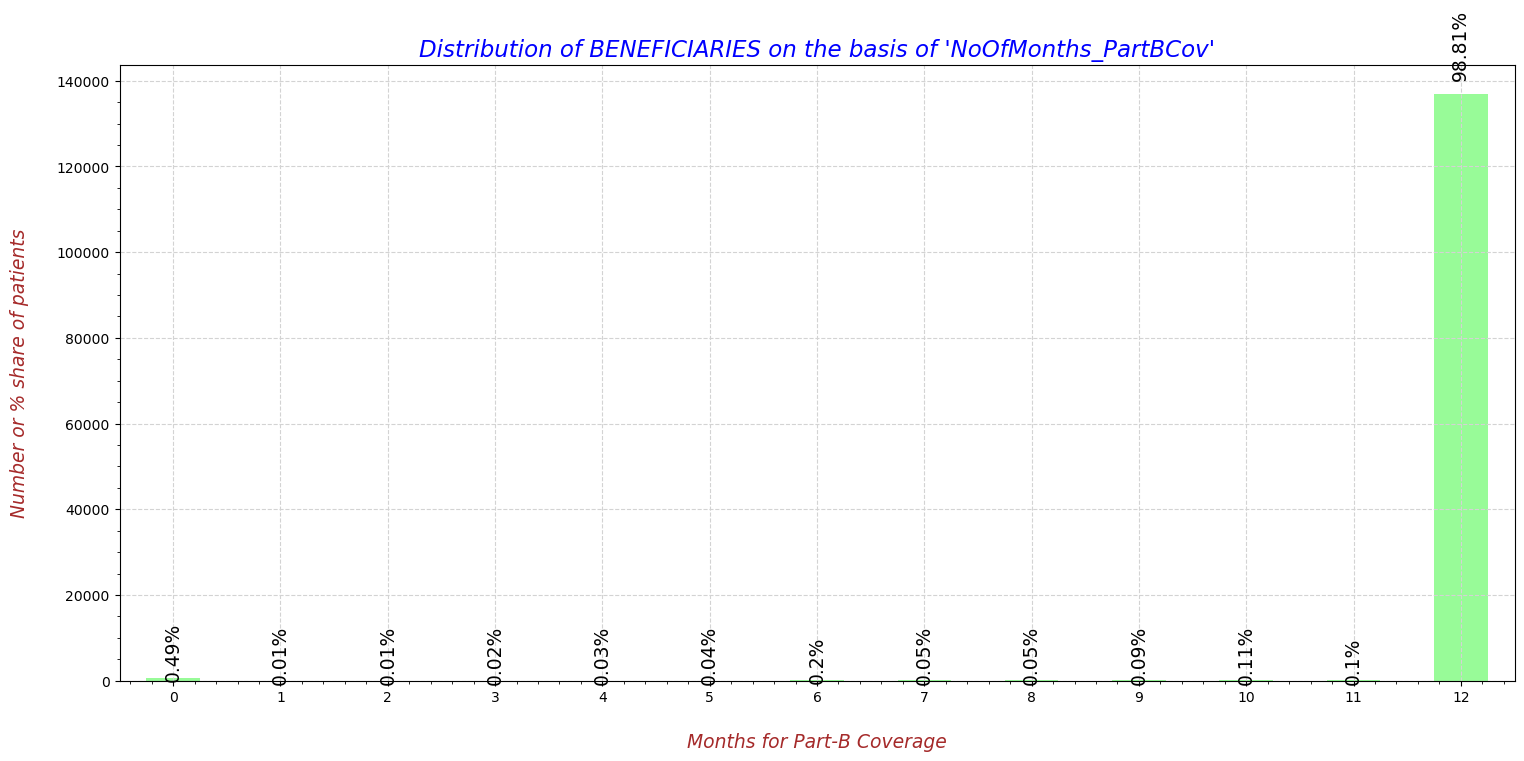

In [51]:
plt.figure(figsize=(18,8))
fig = bene_train_df['NoOfMonths_PartBCov'].value_counts().sort_index().plot(kind='bar', color='palegreen')
for p in fig.patches:
    width = p.get_width()
    height = p.get_height()
    x, y = p.get_xy()
    fig.annotate(f'{str(round((height*100)/bene_train_df.shape[0],2))+"%"}', (x + width/2, y + height*1.03), ha='center', fontsize=13.5, rotation=90)
plt.xlabel("\nMonths for Part-B Coverage", fontdict=label_font_dict)
plt.xticks(rotation = 0)
plt.ylabel("Number or % share of patients\n", fontdict=label_font_dict)
plt.grid(which='major', linestyle="--", color='lightgrey')
plt.minorticks_on()
plt.title("Distribution of BENEFICIARIES on the basis of 'NoOfMonths_PartBCov'", fontdict=title_font_dict)
plt.show()

- **`OBSERVATION`**
  - The above graph shows us that around 99% of beneficiaries have 12 months Part-B Coverage. My initial look to above plot tells me that this feature won't have much impact on the tgt labels.

### **Q9 Lets see the number of beneficiaries on the basis of 'ChronicCond_Alzheimer'. And, the Annual IP & OP expenditures for such patients.**

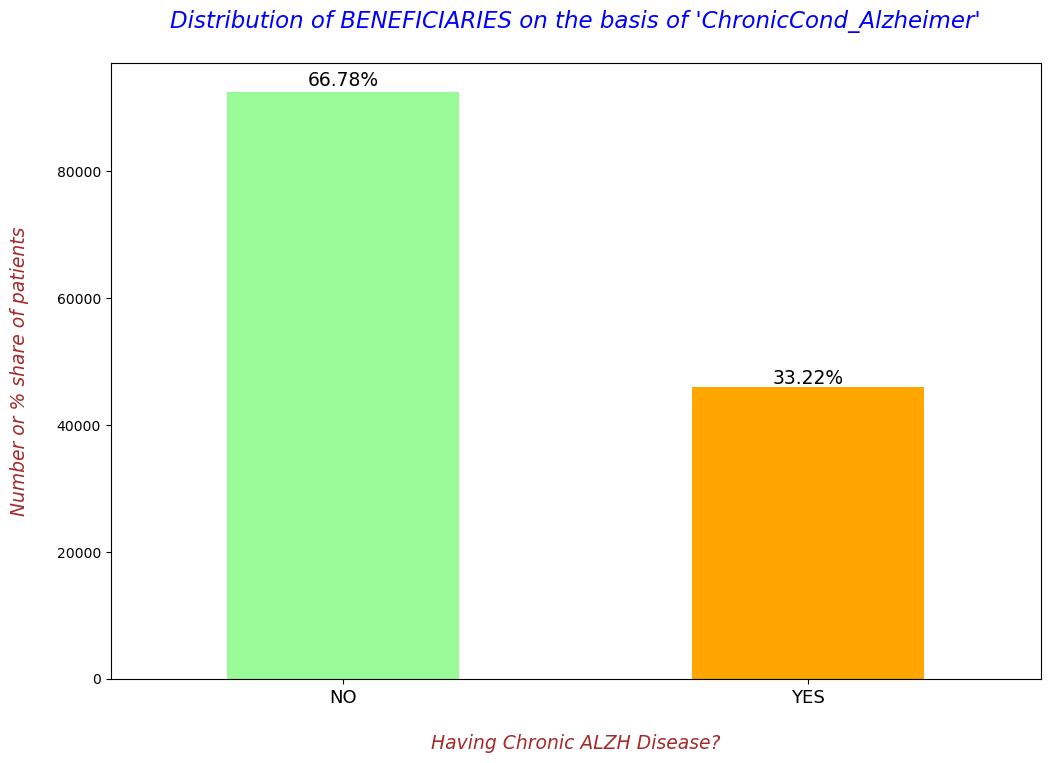

   ChronicCond_Alzheimer
2                  92530
1                  46026 



In [52]:
plt.figure(figsize=(12,8))
fig = bene_train_df['ChronicCond_Alzheimer'].value_counts().plot(kind='bar', color=['palegreen','orange'])
for p in fig.patches:
    width = p.get_width()
    height = p.get_height()
    x, y = p.get_xy()
    fig.annotate(f'{str(round((height*100)/bene_train_df.shape[0],2))+"%"}', (x + width/2, y + height*1.01), ha='center', fontsize=13.5, rotation=0)
plt.xlabel("\nHaving Chronic ALZH Disease?", fontdict=label_font_dict)
plt.xticks(ticks=[0,1], labels=['NO', 'YES'], fontsize=13, rotation=0)
plt.ylabel("Number or % share of patients\n", fontdict=label_font_dict)
plt.title("Distribution of BENEFICIARIES on the basis of 'ChronicCond_Alzheimer'\n", fontdict=title_font_dict)
plt.show()

# 1 means +ve with Chronic ALZH Disease
# 2 means -ve with Chronic ALZH Disease
print(pd.DataFrame(bene_train_df['ChronicCond_Alzheimer'].value_counts()),"\n")

- **`OBSERVATION`**
 - The above graph shows us that the beneficiaries with Chronic ALZH Disease are almost half as compared to the non-ALZH beneficiaries.

                       IPAnnualReimbursementAmt
ChronicCond_Alzheimer                          
1                                     247213280
2                                     259949690 



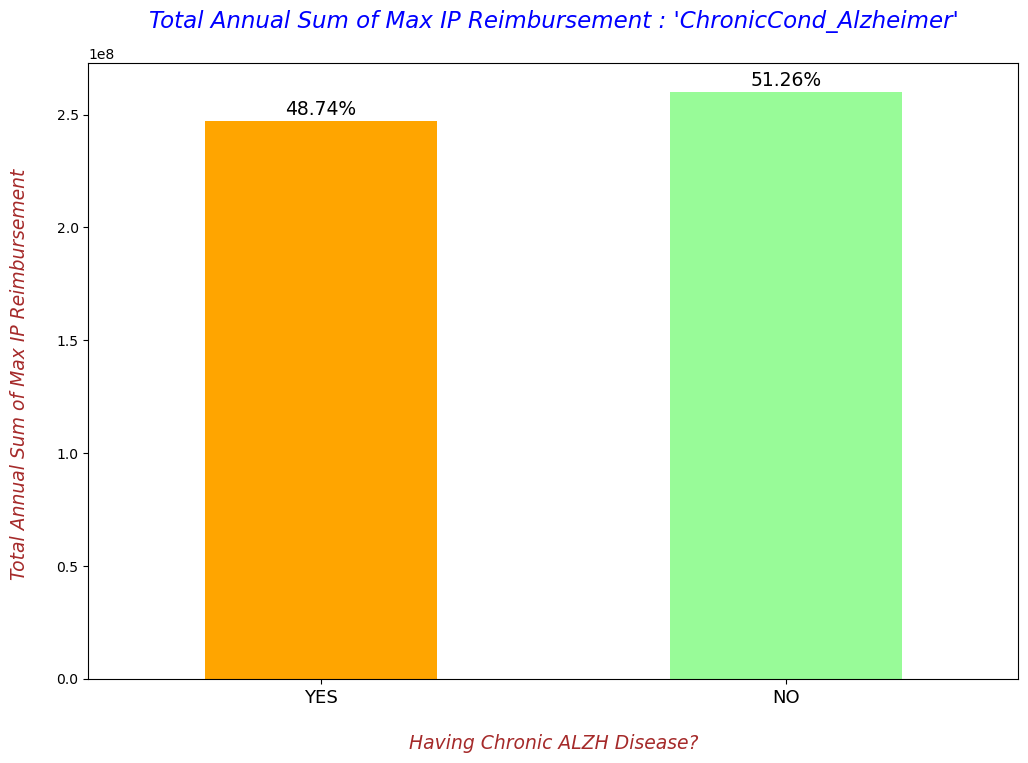

In [53]:
plt.figure(figsize=(12,8))
fig = bene_train_df.groupby(['ChronicCond_Alzheimer'])['IPAnnualReimbursementAmt'].sum().plot(kind='bar', color=['orange','palegreen'])
for p in fig.patches:
    width = p.get_width()
    height = p.get_height()
    x, y = p.get_xy()
    fig.annotate(f'{str(round((height*100)/(bene_train_df["IPAnnualReimbursementAmt"].sum()),2))+"%"}', (x + width/2, y + height*1.01), ha='center', fontsize=13.5, rotation=0)
plt.xlabel("\nHaving Chronic ALZH Disease?", fontdict=label_font_dict)
plt.xticks(ticks=[0,1], labels=['YES', 'NO'], fontsize=13, rotation=0)
plt.ylabel("Total Annual Sum of Max IP Reimbursement \n", fontdict=label_font_dict)
plt.title("Total Annual Sum of Max IP Reimbursement : 'ChronicCond_Alzheimer'\n", fontdict=title_font_dict)

# 1 means +ve with Chronic ALZH Disease
# 2 means -ve with Chronic ALZH Disease
print(pd.DataFrame(bene_train_df.groupby(['ChronicCond_Alzheimer'])['IPAnnualReimbursementAmt'].sum()),"\n")

- **`OBSERVATION`**
  - The above graph shows us that despite the non-ALZH beneficiaries are double in number as compared to their counterparts, however, the Annual Sum of MAX IP Reimbursement is almost same for both the groups.
    - This means if a beneficiary with or without chronic ALZH Disease get admitted then the annual reimbursement paid is approx same.
      - The difference is of 13 Million or 2.52%.

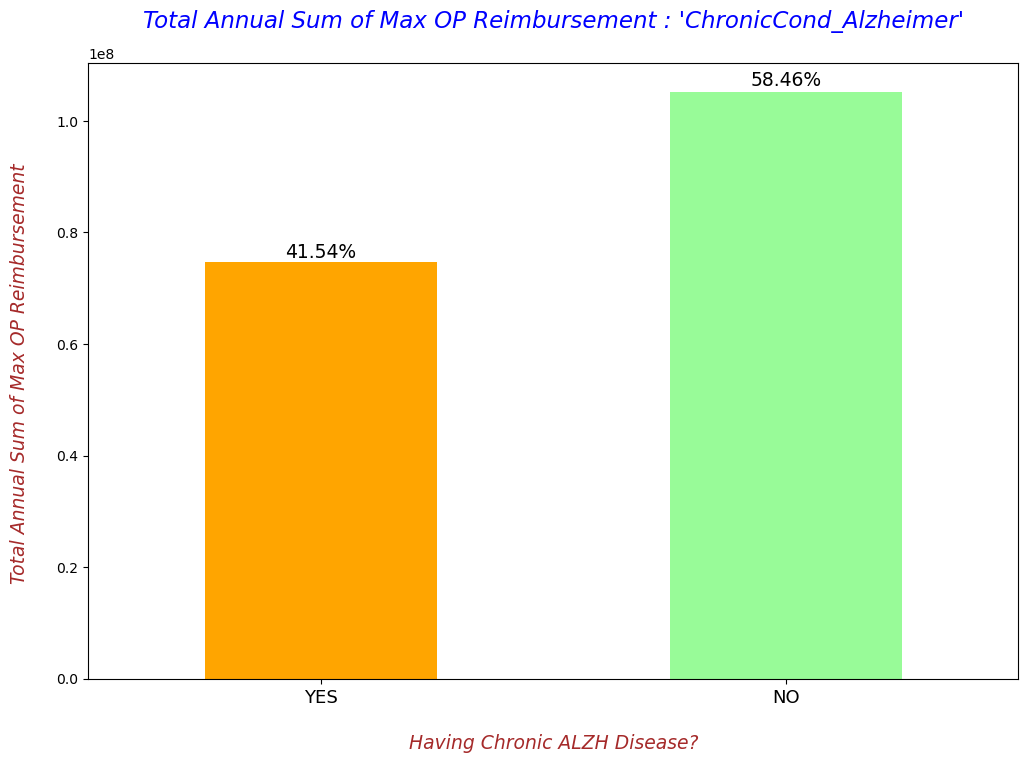

                       OPAnnualReimbursementAmt
ChronicCond_Alzheimer                          
1                                      74721530
2                                     105154550 



In [54]:
plt.figure(figsize=(12,8))
fig = bene_train_df.groupby(['ChronicCond_Alzheimer'])['OPAnnualReimbursementAmt'].sum().plot(kind='bar', color=['orange','palegreen'])
for p in fig.patches:
    width = p.get_width()
    height = p.get_height()
    x, y = p.get_xy()
    fig.annotate(f'{str(round((height*100)/(bene_train_df["OPAnnualReimbursementAmt"].sum()),2))+"%"}', (x + width/2, y + height*1.01), ha='center', fontsize=13.5, rotation=0)
plt.xlabel("\nHaving Chronic ALZH Disease?", fontdict=label_font_dict)
plt.xticks(ticks=[0,1], labels=['YES', 'NO'], fontsize=13, rotation=0)
plt.ylabel("Total Annual Sum of Max OP Reimbursement \n", fontdict=label_font_dict)
plt.title("Total Annual Sum of Max OP Reimbursement : 'ChronicCond_Alzheimer'\n", fontdict=title_font_dict)
plt.show()
# 1 means +ve with Chronic ALZH Disease
# 2 means -ve with Chronic ALZH Disease
print(pd.DataFrame(bene_train_df.groupby(['ChronicCond_Alzheimer'])['OPAnnualReimbursementAmt'].sum()),"\n")

- **`OBSERVATION`**
  - The above graph shows us that the Annual Sum of OP Reimbursement for non-chronic ALZH Disease beneficiaries is more than 31 Million or 16.92% than the other group.

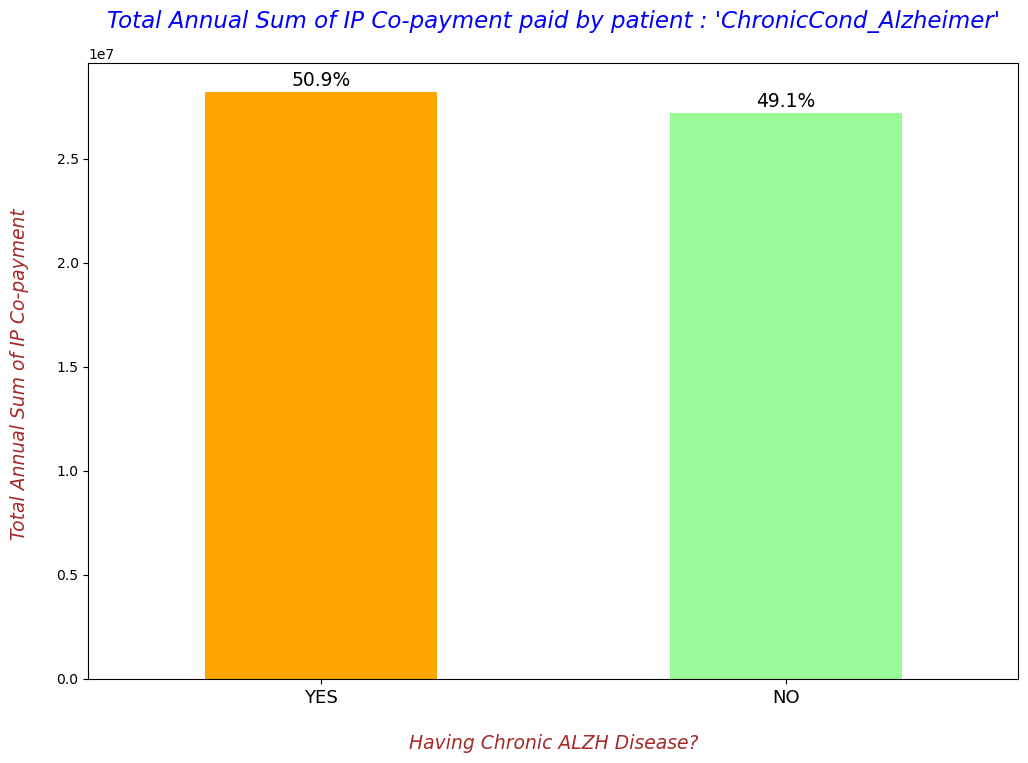

                       IPAnnualDeductibleAmt
ChronicCond_Alzheimer                       
1                                   28200854
2                                   27200388 



In [55]:
plt.figure(figsize=(12,8))
fig = bene_train_df.groupby(['ChronicCond_Alzheimer'])['IPAnnualDeductibleAmt'].sum().plot(kind='bar', color=['orange','palegreen'])
for p in fig.patches:
    width = p.get_width()
    height = p.get_height()
    x, y = p.get_xy()
    fig.annotate(f'{str(round((height*100)/(bene_train_df["IPAnnualDeductibleAmt"].sum()),2))+"%"}', (x + width/2, y + height*1.01), ha='center', fontsize=13.5, rotation=0)

plt.xlabel("\nHaving Chronic ALZH Disease?", fontdict=label_font_dict)
plt.xticks(ticks=[0,1], labels=['YES', 'NO'], fontsize=13, rotation=0)
plt.ylabel("Total Annual Sum of IP Co-payment \n", fontdict=label_font_dict)
plt.title("Total Annual Sum of IP Co-payment paid by patient : 'ChronicCond_Alzheimer'\n", fontdict=title_font_dict)
plt.show()

# 1 means +ve with Chronic ALZH Disease
# 2 means -ve with Chronic ALZH Disease
print(pd.DataFrame(bene_train_df.groupby(['ChronicCond_Alzheimer'])['IPAnnualDeductibleAmt'].sum()),"\n")

- **`OBSERVATION`**
  - The above graph shows us that the Annual Sum of IP Co-payment paid by the patient of non-chronic & chronic ALZH Disease is almost same. The difference is only of 10 Million or 1.8%.
    - So, we can say that the re-imbursement & co-payment amounts are same for chronic and non-chronic patients if they gets admitted.

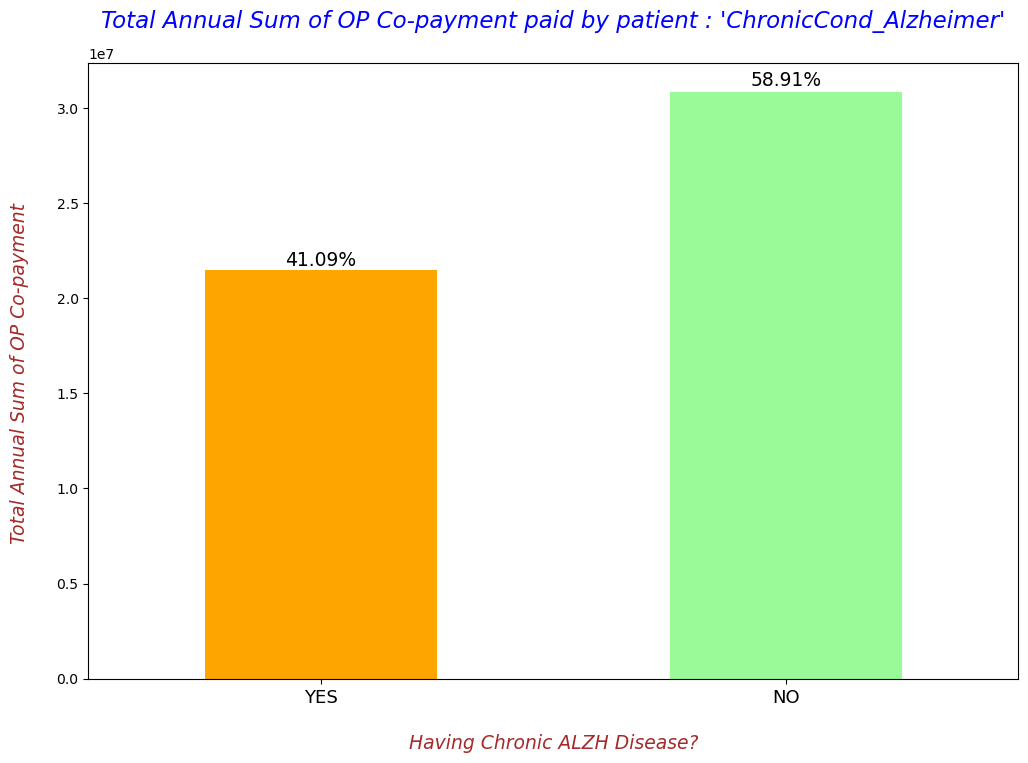

                       OPAnnualDeductibleAmt
ChronicCond_Alzheimer                       
1                                   21502981
2                                   30832150 



In [56]:
plt.figure(figsize=(12,8))
fig = bene_train_df.groupby(['ChronicCond_Alzheimer'])['OPAnnualDeductibleAmt'].sum().plot(kind='bar', color=['orange','palegreen'])
for p in fig.patches:
    width = p.get_width()
    height = p.get_height()
    x, y = p.get_xy()
    fig.annotate(f'{str(round((height*100)/(bene_train_df["OPAnnualDeductibleAmt"].sum()),2))+"%"}', (x + width/2, y + height*1.01), ha='center', fontsize=13.5, rotation=0)

plt.xlabel("\nHaving Chronic ALZH Disease?", fontdict=label_font_dict)
plt.xticks(ticks=[0,1], labels=['YES', 'NO'], fontsize=13, rotation=0)
plt.ylabel("Total Annual Sum of OP Co-payment \n", fontdict=label_font_dict)
plt.title("Total Annual Sum of OP Co-payment paid by patient : 'ChronicCond_Alzheimer'\n", fontdict=title_font_dict)
plt.show()

# 1 means +ve with Chronic ALZH Disease
# 2 means -ve with Chronic ALZH Disease
print(pd.DataFrame(bene_train_df.groupby(['ChronicCond_Alzheimer'])['OPAnnualDeductibleAmt'].sum()),"\n")

- **`OBSERVATION`**
  - The above graph shows us that the Annual Sum of OP Co-payment paid by the patient of non-chronic is more as compared to chronic ALZH Disease. The difference is of 93.3 Million or 17.82%.
    - So, we can say that the co-payment paid by non-admitted patients is higher than the ones who gets admitted.

In [57]:
# Number of beneficiaries with chronic or no-chronic conditions
pd.DataFrame(bene_train_df.groupby(['ChronicCond_Alzheimer'])['BeneID'].count())

,BeneID
ChronicCond_Alzheimer,
1,46026
2,92530


In [58]:
CC_ALZH_IP_R = pd.DataFrame(bene_train_df.groupby(['ChronicCond_Alzheimer'])['IPAnnualReimbursementAmt'].sum() / bene_train_df.groupby(['ChronicCond_Alzheimer'])['BeneID'].count())
CC_ALZH_IP_R.columns = ['AVG IP Reimbursement Amt']
CC_ALZH_IP_R

,AVG IP Reimbursement Amt
ChronicCond_Alzheimer,
1,5371.165863
2,2809.355777


In [59]:
CC_ALZH_OP_R = pd.DataFrame(bene_train_df.groupby(['ChronicCond_Alzheimer'])['OPAnnualReimbursementAmt'].sum() / bene_train_df.groupby(['ChronicCond_Alzheimer'])['BeneID'].count())
CC_ALZH_OP_R.columns = ['AVG OP Reimbursement Amt']
CC_ALZH_OP_R

,AVG OP Reimbursement Amt
ChronicCond_Alzheimer,
1,1623.463477
2,1136.437372


In [60]:
CC_ALZH_IP_D = pd.DataFrame(bene_train_df.groupby(['ChronicCond_Alzheimer'])['IPAnnualDeductibleAmt'].sum() / bene_train_df.groupby(['ChronicCond_Alzheimer'])['BeneID'].count())
CC_ALZH_IP_D.columns = ['AVG IP Co-payment Amt']
CC_ALZH_IP_D

,AVG IP Co-payment Amt
ChronicCond_Alzheimer,
1,612.715726
2,293.962909


In [61]:
CC_ALZH_OP_D = pd.DataFrame(bene_train_df.groupby(['ChronicCond_Alzheimer'])['OPAnnualDeductibleAmt'].sum() / bene_train_df.groupby(['ChronicCond_Alzheimer'])['BeneID'].count())
CC_ALZH_OP_D.columns = ['AVG OP Co-payment Amt']
CC_ALZH_OP_D

,AVG OP Co-payment Amt
ChronicCond_Alzheimer,
1,467.192044
2,333.212472


In [62]:
CC_ALZH_all_amts = pd.concat([CC_ALZH_IP_R, CC_ALZH_OP_R, CC_ALZH_IP_D, CC_ALZH_OP_D], axis=1)
CC_ALZH_all_amts

,AVG IP Reimbursement Amt,AVG OP Reimbursement Amt,AVG IP Co-payment Amt,AVG OP Co-payment Amt
ChronicCond_Alzheimer,,,,
1,5371.165863,1623.463477,612.715726,467.192044
2,2809.355777,1136.437372,293.962909,333.212472


<Figure size 1200x800 with 0 Axes>

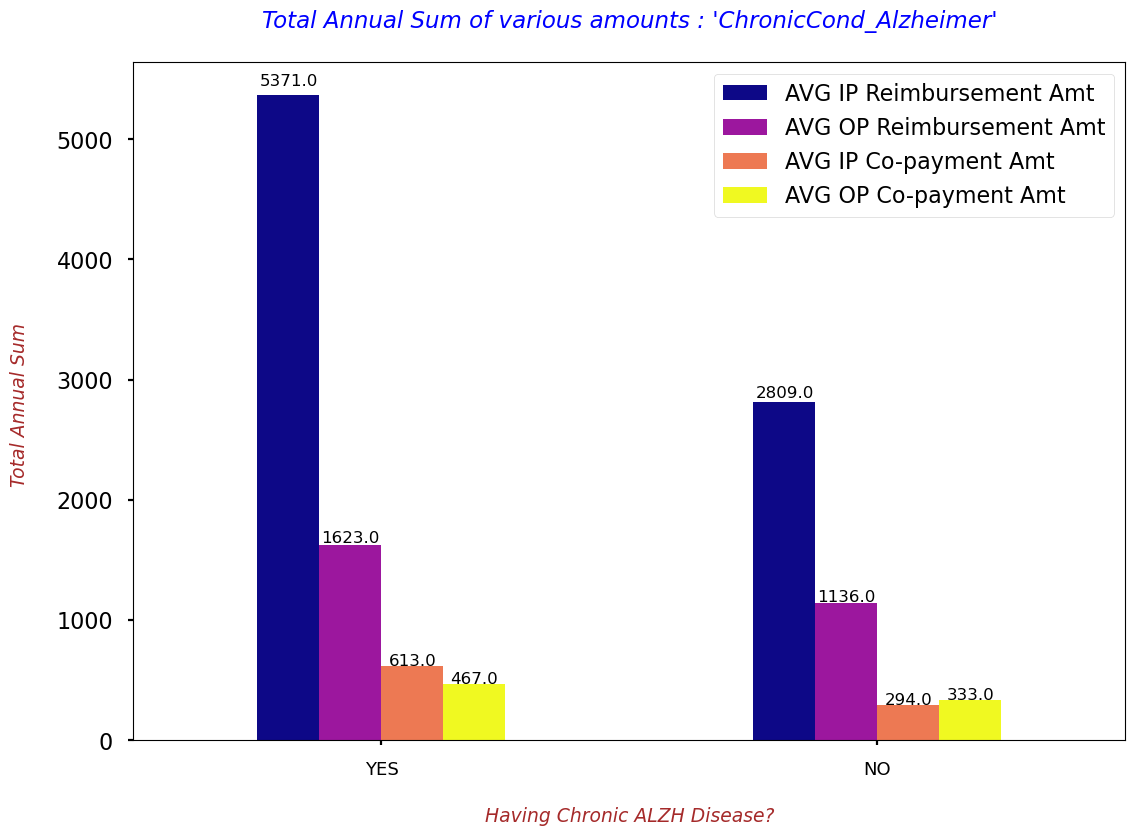

,AVG IP Reimbursement Amt,AVG OP Reimbursement Amt,AVG IP Co-payment Amt,AVG OP Co-payment Amt
ChronicCond_Alzheimer,,,,
1,5371.165863,1623.463477,612.715726,467.192044
2,2809.355777,1136.437372,293.962909,333.212472


In [63]:
plt.figure(figsize=(12,8))
with plt.style.context('seaborn-poster'):
    fig = CC_ALZH_all_amts.plot(kind='bar', colormap='plasma')

    for p in fig.patches:
        width = p.get_width()
        height = p.get_height()
        x, y = p.get_xy()
        fig.annotate(f'{round(height,0)}', (x + width/2, y + height*1.015), ha='center', fontsize=12, rotation=0)

plt.xlabel("\nHaving Chronic ALZH Disease?", fontdict=label_font_dict)
plt.xticks(ticks=[0,1], labels=['YES', 'NO'], fontsize=13, rotation=0)
plt.ylabel("Total Annual Sum \n", fontdict=label_font_dict)
plt.title("Total Annual Sum of various amounts : 'ChronicCond_Alzheimer'\n", fontdict=title_font_dict)
plt.show()

# 1 means +ve with Chronic ALZH Disease
# 2 means -ve with Chronic ALZH Disease
display(CC_ALZH_all_amts)

- **`OBSERVATION`**
  - The above graph is telling us below points:
    - Payer pays huge chunk of expenses specially when a beneficiary gets admitted with or without chronic ALZH disease. To be more precise, in case of +ve it is more than 50%.
    - For other comparisons the difference is not very high.

### **Q10. Lets see the number of beneficiaries on the basis of 'ChronicCond_Heartfailure'. And, the Annual IP & OP expenditures for such patients.**

   ChronicCond_Heartfailure
2                     70154
1                     68402 



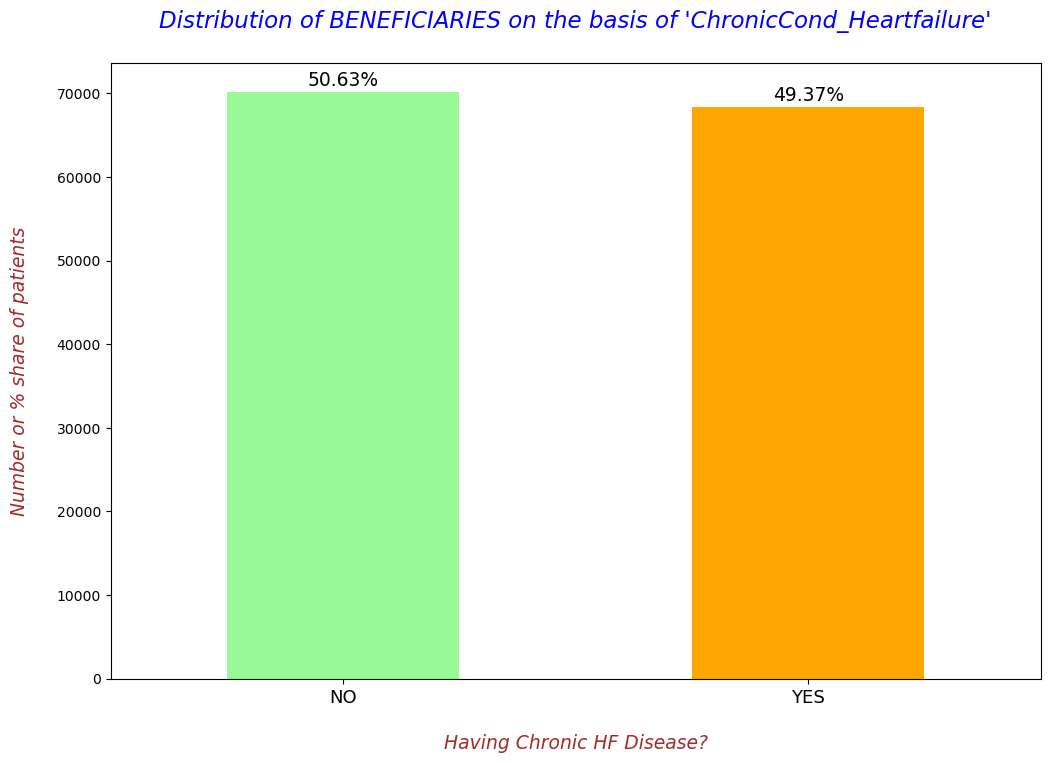

In [64]:
plt.figure(figsize=(12,8))
fig = bene_train_df['ChronicCond_Heartfailure'].value_counts().plot(kind='bar', color=['palegreen','orange'])
for p in fig.patches:
    width = p.get_width()
    height = p.get_height()
    x, y = p.get_xy()
    fig.annotate(f'{str(round((height*100)/bene_train_df.shape[0],2))+"%"}', (x + width/2, y + height*1.01), ha='center', fontsize=13.5, rotation=0)
  
plt.xlabel("\nHaving Chronic HF Disease?", fontdict=label_font_dict)
plt.xticks(ticks=[0,1], labels=['NO', 'YES'], fontsize=13, rotation=0)
plt.ylabel("Number or % share of patients\n", fontdict=label_font_dict)
plt.title("Distribution of BENEFICIARIES on the basis of 'ChronicCond_Heartfailure'\n", fontdict=title_font_dict)

# 1 means +ve with Chronic HF Disease
# 2 means -ve with Chronic HF Disease
print(pd.DataFrame(bene_train_df['ChronicCond_Heartfailure'].value_counts()),"\n")

- **`OBSERVATION`**
  - The above graph shows us that the beneficiaries with Chronic HF Disease are almost equal to the non-ALZH beneficiaries.

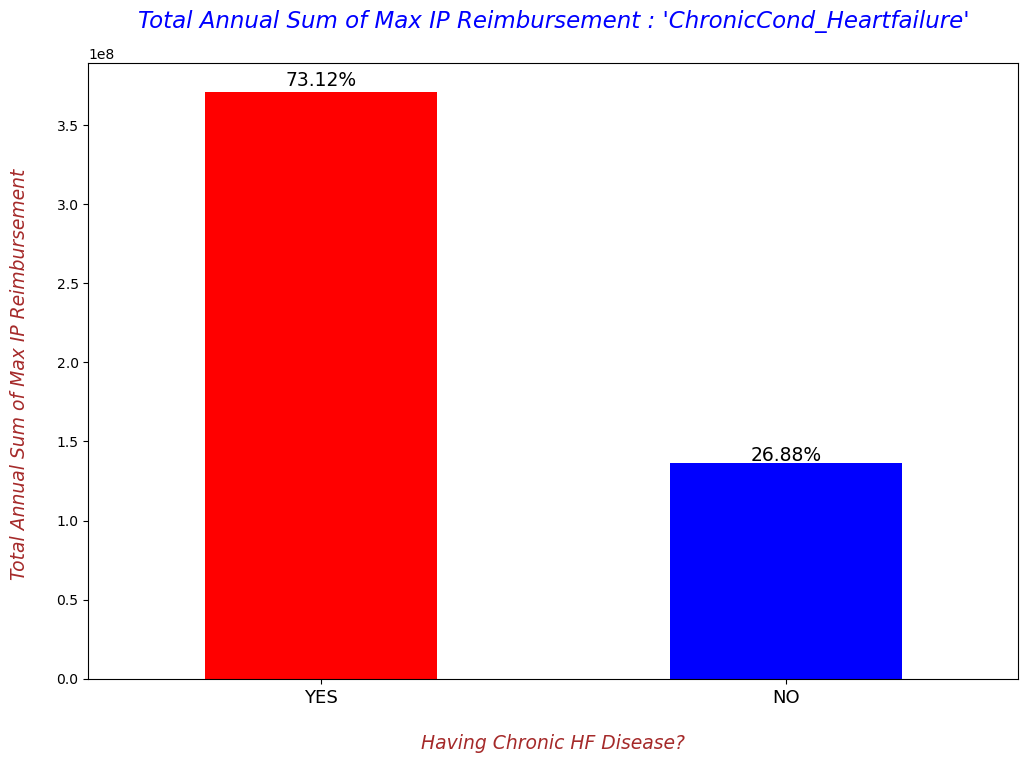

                          IPAnnualReimbursementAmt
ChronicCond_Heartfailure                          
1                                        370856140
2                                        136306830 



In [65]:
plt.figure(figsize=(12,8))
fig = bene_train_df.groupby(['ChronicCond_Heartfailure'])['IPAnnualReimbursementAmt'].sum().plot(kind='bar', color=['red','blue'])
for p in fig.patches:
    width = p.get_width()
    height = p.get_height()
    x, y = p.get_xy()
    fig.annotate(f'{str(round((height*100)/(bene_train_df["IPAnnualReimbursementAmt"].sum()),2))+"%"}', (x + width/2, y + height*1.01), ha='center', fontsize=13.5, rotation=0)

plt.xlabel("\nHaving Chronic HF Disease?", fontdict=label_font_dict)
plt.xticks(ticks=[0,1], labels=['YES', 'NO'], fontsize=13, rotation=0)
plt.ylabel("Total Annual Sum of Max IP Reimbursement \n", fontdict=label_font_dict)
plt.title("Total Annual Sum of Max IP Reimbursement : 'ChronicCond_Heartfailure'\n", fontdict=title_font_dict)
plt.show()

# 1 means +ve with Chronic HF Disease
# 2 means -ve with Chronic HF Disease
print(pd.DataFrame(bene_train_df.groupby(['ChronicCond_Heartfailure'])['IPAnnualReimbursementAmt'].sum()),"\n")

- **`OBSERVATION`**
  - The above graph shows us that the Payer pays very high amount annually for patients with Chronic Heart Failure Disease.
      - The difference is of around 234 Million or 47%. This is very high and it can be a potential sign of FRAUD claims.

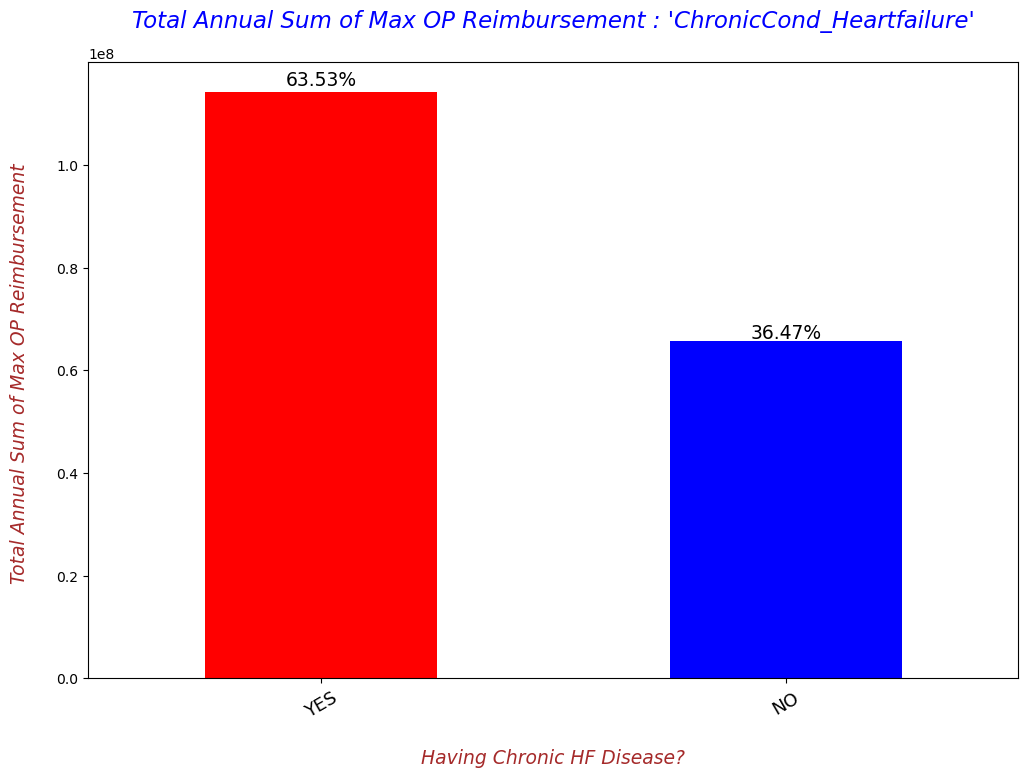

                          OPAnnualReimbursementAmt
ChronicCond_Heartfailure                          
1                                        114280500
2                                         65595580 



In [66]:
plt.figure(figsize=(12,8))
fig = bene_train_df.groupby(['ChronicCond_Heartfailure'])['OPAnnualReimbursementAmt'].sum().plot(kind='bar', color=['red','blue'])
for p in fig.patches:
    width = p.get_width()
    height = p.get_height()
    x, y = p.get_xy()
    fig.annotate(f'{str(round((height*100)/(bene_train_df["OPAnnualReimbursementAmt"].sum()),2))+"%"}', (x + width/2, y + height*1.01), ha='center', fontsize=13.5, rotation=0)

plt.xlabel("\nHaving Chronic HF Disease?", fontdict=label_font_dict)
plt.xticks(ticks=[0,1], labels=['YES', 'NO'], fontsize=13, rotation=30)
plt.ylabel("Total Annual Sum of Max OP Reimbursement \n", fontdict=label_font_dict)
plt.title("Total Annual Sum of Max OP Reimbursement : 'ChronicCond_Heartfailure'\n", fontdict=title_font_dict)
plt.show()

# 1 means +ve with Chronic HF Disease
# 2 means -ve with Chronic HF Disease
print(pd.DataFrame(bene_train_df.groupby(['ChronicCond_Heartfailure'])['OPAnnualReimbursementAmt'].sum()),"\n")

- **`OBSERVATION`**
  - The above graph shows us that the Annual Sum paid by the payers for non-admitted patients is 49 Million more than the other group. This again can be a potential sign of fraud claims.

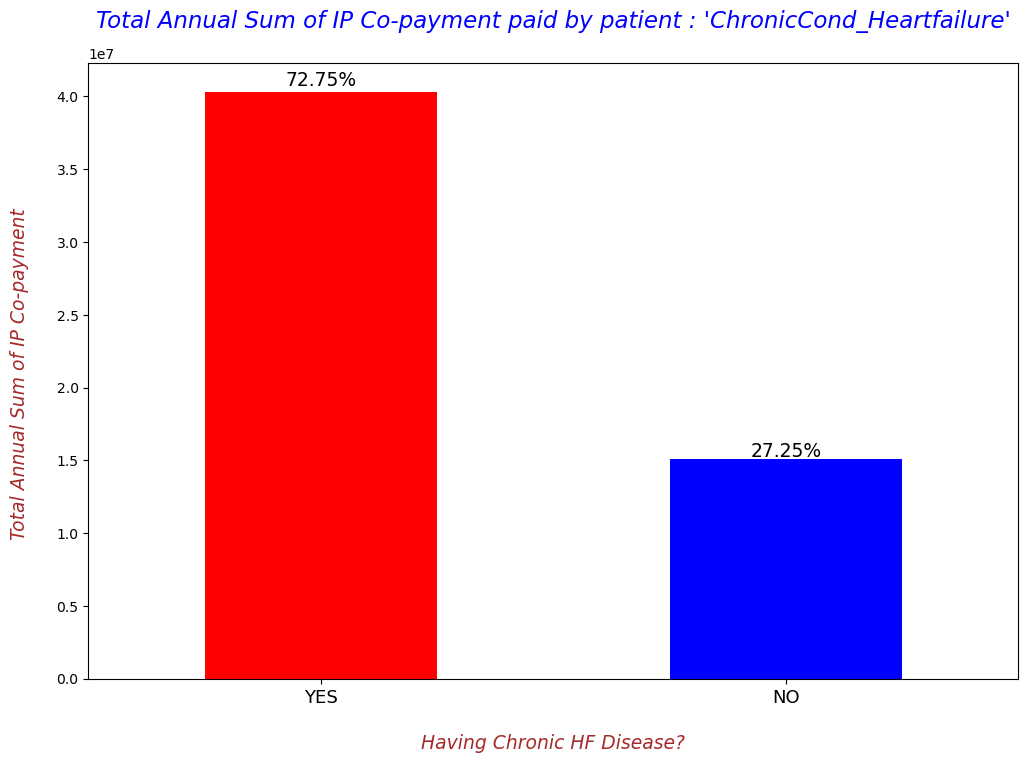

                          IPAnnualDeductibleAmt
ChronicCond_Heartfailure                       
1                                      40303650
2                                      15097592 



In [67]:
plt.figure(figsize=(12,8))
fig = bene_train_df.groupby(['ChronicCond_Heartfailure'])['IPAnnualDeductibleAmt'].sum().plot(kind='bar', color=['red','blue'])
for p in fig.patches:
    width = p.get_width()
    height = p.get_height()
    x, y = p.get_xy()
    fig.annotate(f'{str(round((height*100)/(bene_train_df["IPAnnualDeductibleAmt"].sum()),2))+"%"}', (x + width/2, y + height*1.01), ha='center', fontsize=13.5, rotation=0)

plt.xlabel("\nHaving Chronic HF Disease?", fontdict=label_font_dict)
plt.xticks(ticks=[0,1], labels=['YES', 'NO'], fontsize=13, rotation=0)
plt.ylabel("Total Annual Sum of IP Co-payment \n", fontdict=label_font_dict)
plt.title("Total Annual Sum of IP Co-payment paid by patient : 'ChronicCond_Heartfailure'\n", fontdict=title_font_dict)
plt.show()
# 1 means +ve with Chronic HF Disease
# 2 means -ve with Chronic HF Disease
print(pd.DataFrame(bene_train_df.groupby(['ChronicCond_Heartfailure'])['IPAnnualDeductibleAmt'].sum()),"\n")

- **`OBSERVATION`**
  - The above graph shows us that the Annual Sum of IP Co-payment paid by the patient of non-chronic & chronic HF Disease has a difference of 25 Million.
    - But, the point to note here that the co-payment proportion is very less in front of the part paid by the Payer. This again can be potential sign of FRAUD.

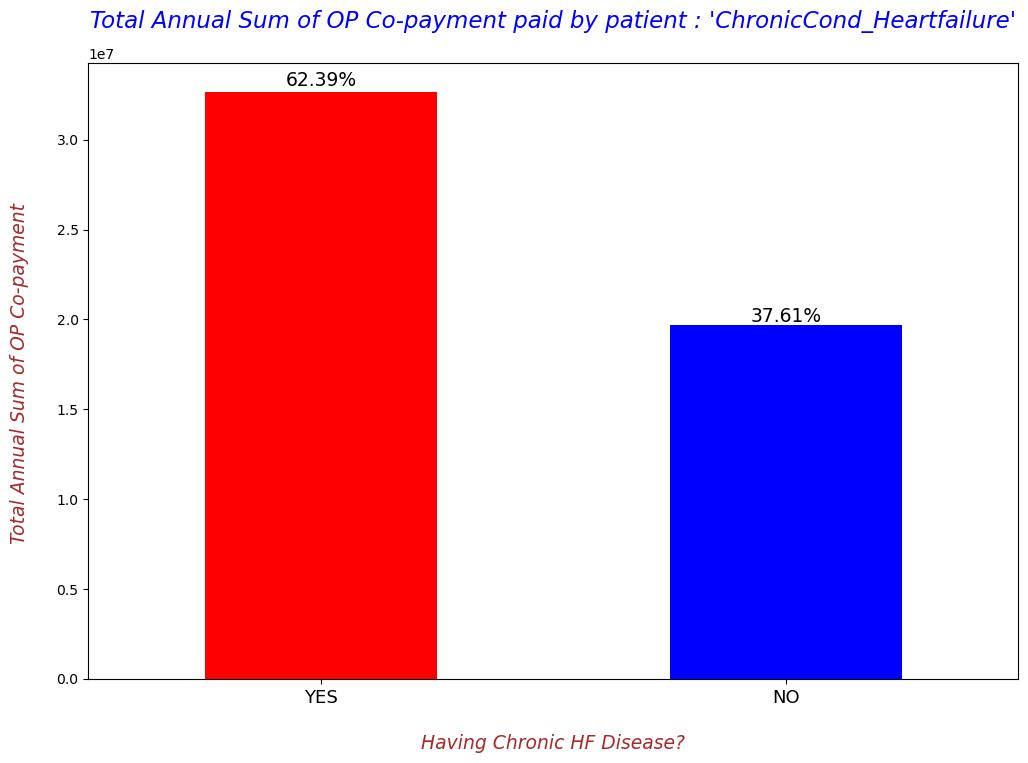

                          OPAnnualDeductibleAmt
ChronicCond_Heartfailure                       
1                                      32649838
2                                      19685293 



In [68]:
plt.figure(figsize=(12,8))
fig = bene_train_df.groupby(['ChronicCond_Heartfailure'])['OPAnnualDeductibleAmt'].sum().plot(kind='bar', color=['red','blue'])
for p in fig.patches:
    width = p.get_width()
    height = p.get_height()
    x, y = p.get_xy()
    fig.annotate(f'{str(round((height*100)/(bene_train_df["OPAnnualDeductibleAmt"].sum()),2))+"%"}', (x + width/2, y + height*1.01), ha='center', fontsize=13.5, rotation=0)

plt.xlabel("\nHaving Chronic HF Disease?", fontdict=label_font_dict)
plt.xticks(ticks=[0,1], labels=['YES', 'NO'], fontsize=13, rotation=0)
plt.ylabel("Total Annual Sum of OP Co-payment \n", fontdict=label_font_dict)
plt.title("Total Annual Sum of OP Co-payment paid by patient : 'ChronicCond_Heartfailure'\n", fontdict=title_font_dict)
plt.show()

# 1 means +ve with Chronic HF Disease
# 2 means -ve with Chronic HF Disease
print(pd.DataFrame(bene_train_df.groupby(['ChronicCond_Heartfailure'])['OPAnnualDeductibleAmt'].sum()),"\n")

- **`OBSERVATION`**
  - The above graph shows us that the Annual Sum of OP Co-payment paid by the patient of non-chronic & chronic HF Disease has a difference of 13 Million.
    - But, the point to note here that the co-payment proportion is very less in front of the part paid by the Payer. This again can be potential sign of FRAUD.

In [69]:
# Number of beneficiaries with chronic or no-chronic conditions
pd.DataFrame(bene_train_df.groupby(['ChronicCond_Heartfailure'])['BeneID'].count())

,BeneID
ChronicCond_Heartfailure,
1,68402
2,70154


In [70]:
CC_HF_IP_R = pd.DataFrame(bene_train_df.groupby(['ChronicCond_Heartfailure'])['IPAnnualReimbursementAmt'].sum() / bene_train_df.groupby(['ChronicCond_Heartfailure'])['BeneID'].count())
CC_HF_IP_R.columns = ['AVG IP Reimbursement Amt']
CC_HF_IP_R

,AVG IP Reimbursement Amt
ChronicCond_Heartfailure,
1,5421.714862
2,1942.965904


In [71]:
CC_HF_OP_R = pd.DataFrame(bene_train_df.groupby(['ChronicCond_Heartfailure'])['OPAnnualReimbursementAmt'].sum() / bene_train_df.groupby(['ChronicCond_Heartfailure'])['BeneID'].count())
CC_HF_OP_R.columns = ['AVG OP Reimbursement Amt']
CC_HF_OP_R

,AVG OP Reimbursement Amt
ChronicCond_Heartfailure,
1,1670.718692
2,935.022664


In [72]:
CC_HF_IP_D = pd.DataFrame(bene_train_df.groupby(['ChronicCond_Heartfailure'])['IPAnnualDeductibleAmt'].sum() / bene_train_df.groupby(['ChronicCond_Heartfailure'])['BeneID'].count())
CC_HF_IP_D.columns = ['AVG IP Co-payment Amt']
CC_HF_IP_D

,AVG IP Co-payment Amt
ChronicCond_Heartfailure,
1,589.217421
2,215.206432


In [73]:
CC_HF_OP_D = pd.DataFrame(bene_train_df.groupby(['ChronicCond_Heartfailure'])['OPAnnualDeductibleAmt'].sum() / bene_train_df.groupby(['ChronicCond_Heartfailure'])['BeneID'].count())
CC_HF_OP_D.columns = ['AVG OP Co-payment Amt']
CC_HF_OP_D

,AVG OP Co-payment Amt
ChronicCond_Heartfailure,
1,477.322856
2,280.601149


In [74]:
CC_HF_all_amts = pd.concat([CC_HF_IP_R, CC_HF_OP_R, CC_HF_IP_D, CC_HF_OP_D], axis=1)
CC_HF_all_amts

,AVG IP Reimbursement Amt,AVG OP Reimbursement Amt,AVG IP Co-payment Amt,AVG OP Co-payment Amt
ChronicCond_Heartfailure,,,,
1,5421.714862,1670.718692,589.217421,477.322856
2,1942.965904,935.022664,215.206432,280.601149


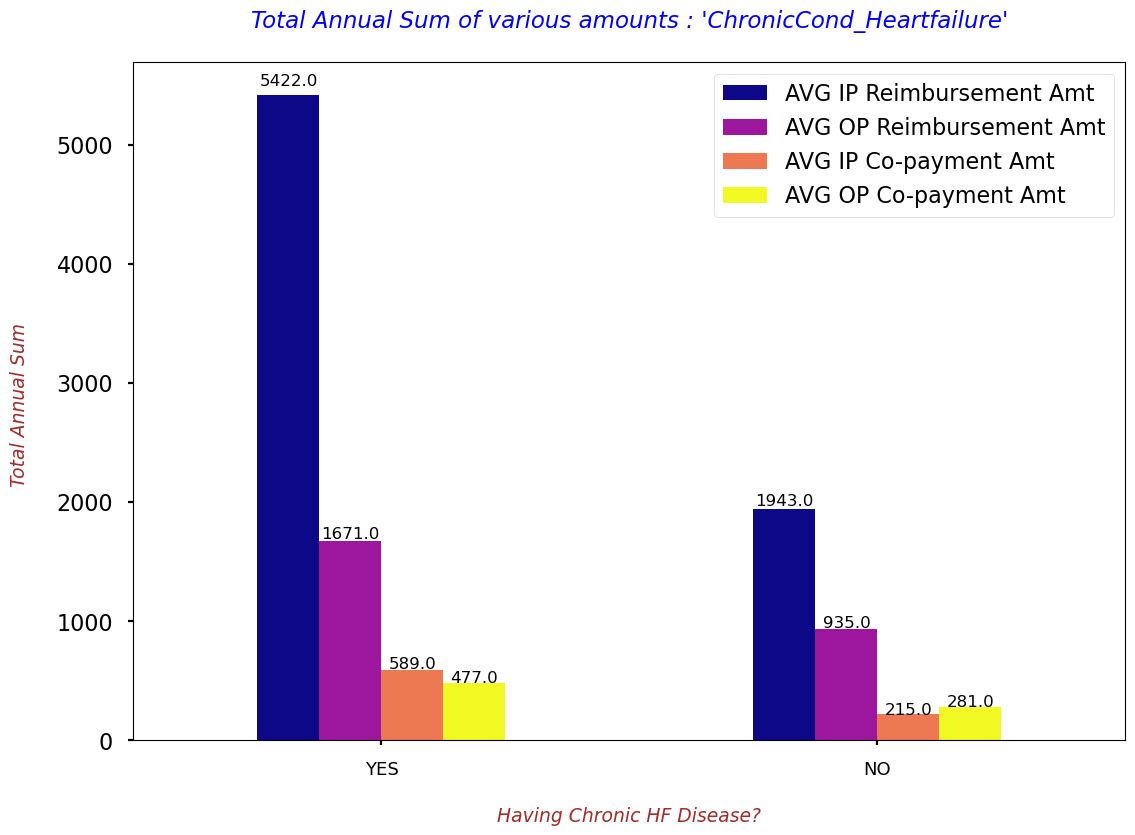

,AVG IP Reimbursement Amt,AVG OP Reimbursement Amt,AVG IP Co-payment Amt,AVG OP Co-payment Amt
ChronicCond_Heartfailure,,,,
1,5421.714862,1670.718692,589.217421,477.322856
2,1942.965904,935.022664,215.206432,280.601149


In [75]:
with plt.style.context('seaborn-poster'):
    fig = CC_HF_all_amts.plot(kind='bar', colormap='plasma')

    for p in fig.patches:
        width = p.get_width()
        height = p.get_height()
        x, y = p.get_xy()
        fig.annotate(f'{round(height,0)}', (x + width/2, y + height*1.015), ha='center', fontsize=12, rotation=0)
# Providing the labels and title to the graph
plt.xlabel("\nHaving Chronic HF Disease?", fontdict=label_font_dict)
plt.xticks(ticks=[0,1], labels=['YES', 'NO'], fontsize=13, rotation=0)
plt.ylabel("Total Annual Sum \n", fontdict=label_font_dict)
plt.title("Total Annual Sum of various amounts : 'ChronicCond_Heartfailure'\n", fontdict=title_font_dict)
plt.show()

# 1 means +ve with Chronic HF Disease
# 2 means -ve with Chronic HF Disease
display(CC_HF_all_amts)

- **`OBSERVATION`**
  - The above graph is telling us below points:
    - Payer pays huge chunk of expenses specially when a beneficiary gets admitted with or without chronic HF disease. To be more precise, in case of +ve it is more than 50%.
    - For other comparisons the difference is not very high.

### **Q11. Lets see the number of beneficiaries on the basis of 'ChronicCond_KidneyDisease'. And, the Annual IP & OP expenditures for such patients.**

In [76]:
# Number of beneficiaries with chronic or no-chronic conditions
pd.DataFrame(bene_train_df.groupby(['ChronicCond_KidneyDisease'])['BeneID'].count())

,BeneID
ChronicCond_KidneyDisease,
1,43279
2,95277


In [77]:
CC_KD_IP_R = pd.DataFrame(bene_train_df.groupby(['ChronicCond_KidneyDisease'])['IPAnnualReimbursementAmt'].sum() / bene_train_df.groupby(['ChronicCond_KidneyDisease'])['BeneID'].count())
CC_KD_IP_R.columns = ['AVG IP Reimbursement Amt']
CC_KD_IP_R

,AVG IP Reimbursement Amt
ChronicCond_KidneyDisease,
1,7500.768040
2,1915.858287


In [78]:
CC_KD_OP_R = pd.DataFrame(bene_train_df.groupby(['ChronicCond_KidneyDisease'])['OPAnnualReimbursementAmt'].sum() / bene_train_df.groupby(['ChronicCond_KidneyDisease'])['BeneID'].count())
CC_KD_OP_R.columns = ['AVG OP Reimbursement Amt']
CC_KD_OP_R

,AVG OP Reimbursement Amt
ChronicCond_KidneyDisease,
1,2061.602625
2,951.457120


In [79]:
CC_KD_IP_D = pd.DataFrame(bene_train_df.groupby(['ChronicCond_KidneyDisease'])['IPAnnualDeductibleAmt'].sum() / bene_train_df.groupby(['ChronicCond_KidneyDisease'])['BeneID'].count())
CC_KD_IP_D.columns = ['AVG IP Co-payment Amt']
CC_KD_IP_D

,AVG IP Co-payment Amt
ChronicCond_KidneyDisease,
1,785.385707
2,224.718809


In [80]:
CC_KD_OP_D = pd.DataFrame(bene_train_df.groupby(['ChronicCond_KidneyDisease'])['OPAnnualDeductibleAmt'].sum() / bene_train_df.groupby(['ChronicCond_KidneyDisease'])['BeneID'].count())
CC_KD_OP_D.columns = ['AVG OP Co-payment Amt']
CC_KD_OP_D

,AVG OP Co-payment Amt
ChronicCond_KidneyDisease,
1,582.706417
2,284.603629


In [81]:
CC_KD_all_amts = pd.concat([CC_KD_IP_R, CC_KD_OP_R, CC_KD_IP_D, CC_KD_OP_D], axis=1)
CC_KD_all_amts

,AVG IP Reimbursement Amt,AVG OP Reimbursement Amt,AVG IP Co-payment Amt,AVG OP Co-payment Amt
ChronicCond_KidneyDisease,,,,
1,7500.768040,2061.602625,785.385707,582.706417
2,1915.858287,951.457120,224.718809,284.603629


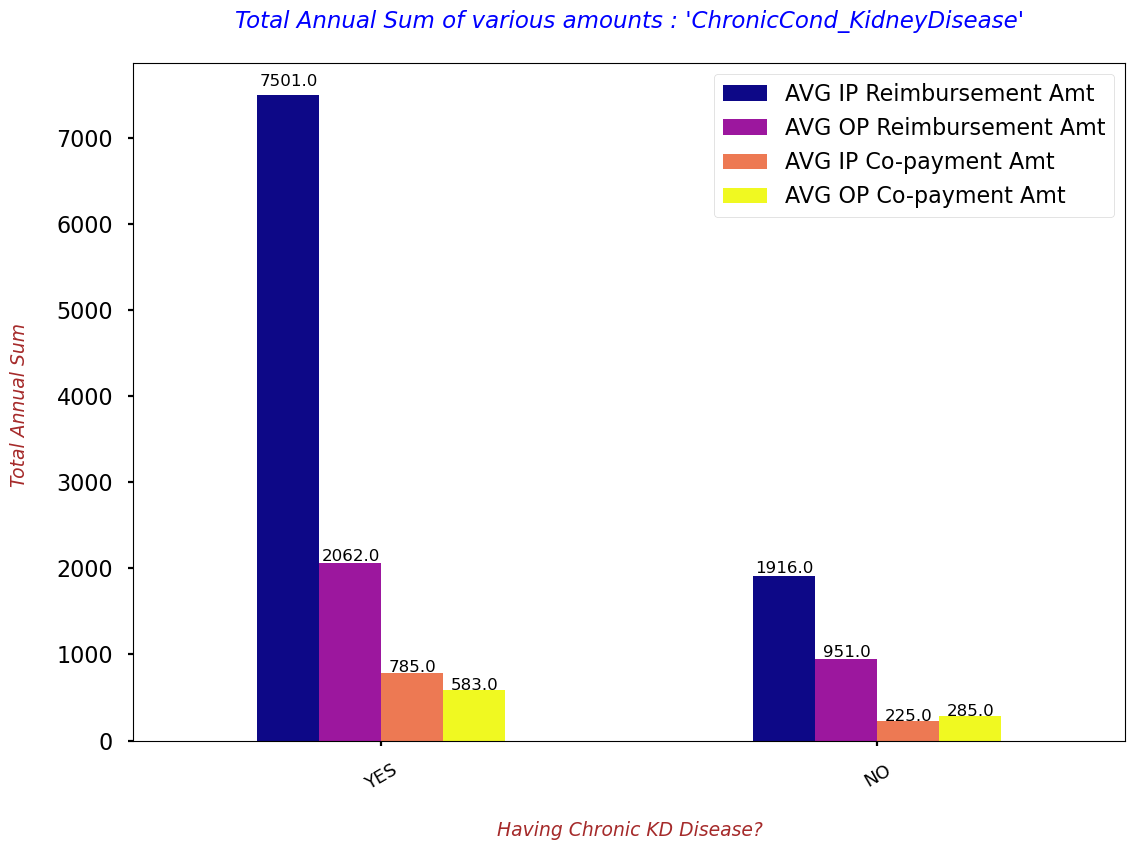

,AVG IP Reimbursement Amt,AVG OP Reimbursement Amt,AVG IP Co-payment Amt,AVG OP Co-payment Amt
ChronicCond_KidneyDisease,,,,
1,7500.768040,2061.602625,785.385707,582.706417
2,1915.858287,951.457120,224.718809,284.603629


In [82]:
with plt.style.context('seaborn-poster'):
  fig = CC_KD_all_amts.plot(kind='bar', colormap='plasma')
  for p in fig.patches:
    width = p.get_width()
    height = p.get_height()
    x, y = p.get_xy()
    fig.annotate(f'{round(height,0)}', (x + width/2, y + height*1.015), ha='center', fontsize=12, rotation=0)

plt.xlabel("\nHaving Chronic KD Disease?", fontdict=label_font_dict)
plt.xticks(ticks=[0,1], labels=['YES', 'NO'], fontsize=13, rotation=30)
plt.ylabel("Total Annual Sum \n", fontdict=label_font_dict)
plt.title("Total Annual Sum of various amounts : 'ChronicCond_KidneyDisease'\n", fontdict=title_font_dict)
plt.show()

# 1 means +ve with Chronic KD Disease
# 2 means -ve with Chronic KD Disease
display(CC_KD_all_amts)

- **`OBSERVATION`**
  - The above graph is telling us below points:
    - Payer pays huge chunk of expenses specially when a beneficiary gets admitted with or without chronic HF disease. To be more precise, in case of +ve it is more than 50%.
    - For other comparisons the difference is not very high.

### **Q12. Lets see the number of beneficiaries on the basis of 'ChronicCond_Cancer'. And, the Annual IP & OP expenditures for such patients.**

In [83]:
# Number of beneficiaries with chronic or no-chronic conditions
pd.DataFrame(bene_train_df.groupby(['ChronicCond_Cancer'])['BeneID'].count())

,BeneID
ChronicCond_Cancer,
1,16621
2,121935


In [84]:
CC_CN_IP_R = pd.DataFrame(bene_train_df.groupby(['ChronicCond_Cancer'])['IPAnnualReimbursementAmt'].sum() / bene_train_df.groupby(['ChronicCond_Cancer'])['BeneID'].count())
CC_CN_IP_R.columns = ['AVG IP Reimbursement Amt']
CC_CN_IP_R

,AVG IP Reimbursement Amt
ChronicCond_Cancer,
1,6067.532038
2,3332.222250


In [85]:
CC_CN_OP_R = pd.DataFrame(bene_train_df.groupby(['ChronicCond_Cancer'])['OPAnnualReimbursementAmt'].sum() / bene_train_df.groupby(['ChronicCond_Cancer'])['BeneID'].count())
CC_CN_OP_R.columns = ['AVG OP Reimbursement Amt']
CC_CN_OP_R

,AVG OP Reimbursement Amt
ChronicCond_Cancer,
1,1788.427291
2,1231.398942


In [86]:
CC_CN_IP_D = pd.DataFrame(bene_train_df.groupby(['ChronicCond_Cancer'])['IPAnnualDeductibleAmt'].sum() / bene_train_df.groupby(['ChronicCond_Cancer'])['BeneID'].count())
CC_CN_IP_D.columns = ['AVG IP Co-payment Amt']
CC_CN_IP_D

,AVG IP Co-payment Amt
ChronicCond_Cancer,
1,636.339811
2,367.610924


In [87]:
CC_CN_OP_D = pd.DataFrame(bene_train_df.groupby(['ChronicCond_Cancer'])['OPAnnualDeductibleAmt'].sum() / bene_train_df.groupby(['ChronicCond_Cancer'])['BeneID'].count())
CC_CN_OP_D.columns = ['AVG OP Co-payment Amt']
CC_CN_OP_D

,AVG OP Co-payment Amt
ChronicCond_Cancer,
1,520.832682
2,358.210284


In [88]:
CC_CN_all_amts = pd.concat([CC_CN_IP_R, CC_CN_OP_R, CC_CN_IP_D, CC_CN_OP_D], axis=1)
CC_CN_all_amts

,AVG IP Reimbursement Amt,AVG OP Reimbursement Amt,AVG IP Co-payment Amt,AVG OP Co-payment Amt
ChronicCond_Cancer,,,,
1,6067.532038,1788.427291,636.339811,520.832682
2,3332.222250,1231.398942,367.610924,358.210284


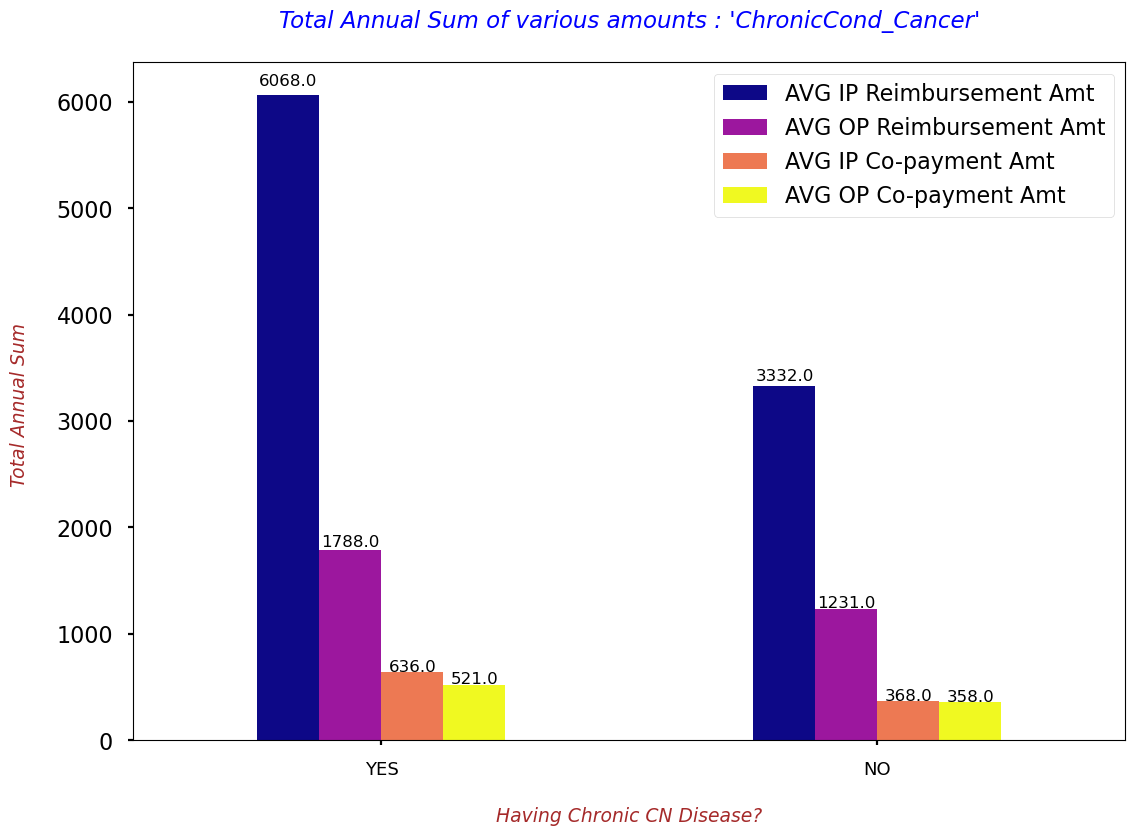

,AVG IP Reimbursement Amt,AVG OP Reimbursement Amt,AVG IP Co-payment Amt,AVG OP Co-payment Amt
ChronicCond_Cancer,,,,
1,6067.532038,1788.427291,636.339811,520.832682
2,3332.222250,1231.398942,367.610924,358.210284


In [89]:
with plt.style.context('seaborn-poster'):
  fig = CC_CN_all_amts.plot(kind='bar', colormap='plasma')
  for p in fig.patches:
    width = p.get_width()
    height = p.get_height()
    x, y = p.get_xy()
    fig.annotate(f'{round(height,0)}', (x + width/2, y + height*1.015), ha='center', fontsize=12, rotation=0)
 
plt.xlabel("\nHaving Chronic CN Disease?", fontdict=label_font_dict)
plt.xticks(ticks=[0,1], labels=['YES', 'NO'], fontsize=13, rotation=0)
plt.ylabel("Total Annual Sum \n", fontdict=label_font_dict)
plt.title("Total Annual Sum of various amounts : 'ChronicCond_Cancer'\n", fontdict=title_font_dict)
plt.show()

# 1 means +ve with Chronic CN Disease
# 2 means -ve with Chronic CN Disease
display(CC_CN_all_amts)

- **`OBSERVATION`**
  - The above graph is telling us below points:
    - Payer pays huge chunk of expenses specially when a beneficiary gets admitted with or without chronic HF disease. To be more precise, in case of +ve it is around 50%.
    - For other comparisons the difference is not very high.

### **Q13. Lets see the number of beneficiaries on the basis of 'ChronicCond_ObstrPulmonary'. And, the Annual IP & OP expenditures for such patients.**

In [90]:
# Number of beneficiaries with chronic or no-chronic conditions
pd.DataFrame(bene_train_df.groupby(['ChronicCond_ObstrPulmonary'])['BeneID'].count())

,BeneID
ChronicCond_ObstrPulmonary,
1,32859
2,105697


In [91]:
CC_PL_IP_R = pd.DataFrame(bene_train_df.groupby(['ChronicCond_ObstrPulmonary'])['IPAnnualReimbursementAmt'].sum() / bene_train_df.groupby(['ChronicCond_ObstrPulmonary'])['BeneID'].count())
CC_PL_IP_R.columns = ['AVG IP Reimbursement Amt']
CC_PL_IP_R

,AVG IP Reimbursement Amt
ChronicCond_ObstrPulmonary,
1,7361.772422
2,2509.650132


In [92]:
CC_PL_OP_R = pd.DataFrame(bene_train_df.groupby(['ChronicCond_ObstrPulmonary'])['OPAnnualReimbursementAmt'].sum() / bene_train_df.groupby(['ChronicCond_ObstrPulmonary'])['BeneID'].count())
CC_PL_OP_R.columns = ['AVG OP Reimbursement Amt']
CC_PL_OP_R

,AVG OP Reimbursement Amt
ChronicCond_ObstrPulmonary,
1,1810.864908
2,1138.848501


In [93]:
CC_PL_IP_D = pd.DataFrame(bene_train_df.groupby(['ChronicCond_ObstrPulmonary'])['IPAnnualDeductibleAmt'].sum() / bene_train_df.groupby(['ChronicCond_ObstrPulmonary'])['BeneID'].count())
CC_PL_IP_D.columns = ['AVG IP Co-payment Amt']
CC_PL_IP_D

,AVG IP Co-payment Amt
ChronicCond_ObstrPulmonary,
1,818.228917
2,269.781148


In [94]:
CC_PL_OP_D = pd.DataFrame(bene_train_df.groupby(['ChronicCond_ObstrPulmonary'])['OPAnnualDeductibleAmt'].sum() / bene_train_df.groupby(['ChronicCond_ObstrPulmonary'])['BeneID'].count())
CC_PL_OP_D.columns = ['AVG OP Co-payment Amt']
CC_PL_OP_D

,AVG OP Co-payment Amt
ChronicCond_ObstrPulmonary,
1,519.44767
2,333.65753


In [95]:
CC_PL_all_amts = pd.concat([CC_PL_IP_R, CC_PL_OP_R, CC_PL_IP_D, CC_PL_OP_D], axis=1)
CC_PL_all_amts

,AVG IP Reimbursement Amt,AVG OP Reimbursement Amt,AVG IP Co-payment Amt,AVG OP Co-payment Amt
ChronicCond_ObstrPulmonary,,,,
1,7361.772422,1810.864908,818.228917,519.44767
2,2509.650132,1138.848501,269.781148,333.65753


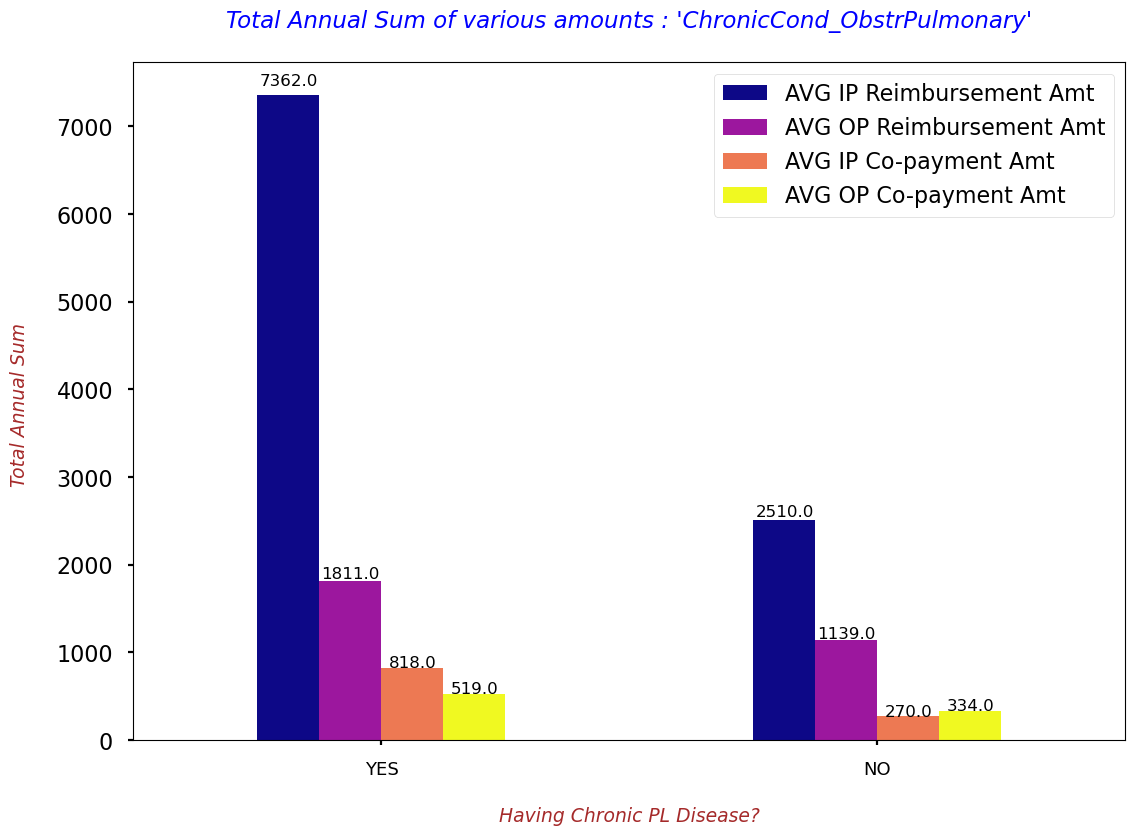

,AVG IP Reimbursement Amt,AVG OP Reimbursement Amt,AVG IP Co-payment Amt,AVG OP Co-payment Amt
ChronicCond_ObstrPulmonary,,,,
1,7361.772422,1810.864908,818.228917,519.44767
2,2509.650132,1138.848501,269.781148,333.65753


In [96]:
with plt.style.context('seaborn-poster'):
  fig = CC_PL_all_amts.plot(kind='bar', colormap='plasma')
  for p in fig.patches:
    width = p.get_width()
    height = p.get_height()
    x, y = p.get_xy()
    fig.annotate(f'{round(height,0)}', (x + width/2, y + height*1.015), ha='center', fontsize=12, rotation=0)

plt.xlabel("\nHaving Chronic PL Disease?", fontdict=label_font_dict)
plt.xticks(ticks=[0,1], labels=['YES', 'NO'], fontsize=13, rotation=0)
plt.ylabel("Total Annual Sum \n", fontdict=label_font_dict)
plt.title("Total Annual Sum of various amounts : 'ChronicCond_ObstrPulmonary'\n", fontdict=title_font_dict)
plt.show()
# 1 means +ve with Chronic PL Disease
# 2 means -ve with Chronic PL Disease
display(CC_PL_all_amts)

- **`OBSERVATION`**
  - The above graph is telling us below points:
    - Payer pays huge chunk of expenses specially when a beneficiary gets admitted with or without chronic HF disease. To be more precise, in case of +ve it is more than 50%.
    - For other comparisons the difference is not very high.

### **Q14. Lets see the number of beneficiaries on the basis of 'ChronicCond_Depression'. And, the Annual IP & OP expenditures for such patients.**

In [97]:
# Number of beneficiaries with chronic or no-chronic conditions
pd.DataFrame(bene_train_df.groupby(['ChronicCond_Depression'])['BeneID'].count())

,BeneID
ChronicCond_Depression,
1,49260
2,89296


In [98]:
CC_DP_IP_R = pd.DataFrame(bene_train_df.groupby(['ChronicCond_Depression'])['IPAnnualReimbursementAmt'].sum() / bene_train_df.groupby(['ChronicCond_Depression'])['BeneID'].count())
CC_DP_IP_R.columns = ['AVG IP Reimbursement Amt']
CC_DP_IP_R

,AVG IP Reimbursement Amt
ChronicCond_Depression,
1,5022.162810
2,2909.102647


In [99]:
CC_DP_OP_R = pd.DataFrame(bene_train_df.groupby(['ChronicCond_Depression'])['OPAnnualReimbursementAmt'].sum() / bene_train_df.groupby(['ChronicCond_Depression'])['BeneID'].count())
CC_DP_OP_R.columns = ['AVG OP Reimbursement Amt']
CC_DP_OP_R

,AVG OP Reimbursement Amt
ChronicCond_Depression,
1,1603.871701
2,1129.606701


In [100]:
CC_DP_IP_D = pd.DataFrame(bene_train_df.groupby(['ChronicCond_Depression'])['IPAnnualDeductibleAmt'].sum() / bene_train_df.groupby(['ChronicCond_Depression'])['BeneID'].count())
CC_DP_IP_D.columns = ['AVG IP Co-payment Amt']
CC_DP_IP_D

,AVG IP Co-payment Amt
ChronicCond_Depression,
1,570.054771
2,305.952607


In [101]:
CC_DP_OP_D = pd.DataFrame(bene_train_df.groupby(['ChronicCond_Depression'])['OPAnnualDeductibleAmt'].sum() / bene_train_df.groupby(['ChronicCond_Depression'])['BeneID'].count())
CC_DP_OP_D.columns = ['AVG OP Co-payment Amt']
CC_DP_OP_D

,AVG OP Co-payment Amt
ChronicCond_Depression,
1,464.285708
2,329.963459


In [102]:
CC_DP_all_amts = pd.concat([CC_DP_IP_R, CC_DP_OP_R, CC_DP_IP_D, CC_DP_OP_D], axis=1)
CC_DP_all_amts

,AVG IP Reimbursement Amt,AVG OP Reimbursement Amt,AVG IP Co-payment Amt,AVG OP Co-payment Amt
ChronicCond_Depression,,,,
1,5022.162810,1603.871701,570.054771,464.285708
2,2909.102647,1129.606701,305.952607,329.963459


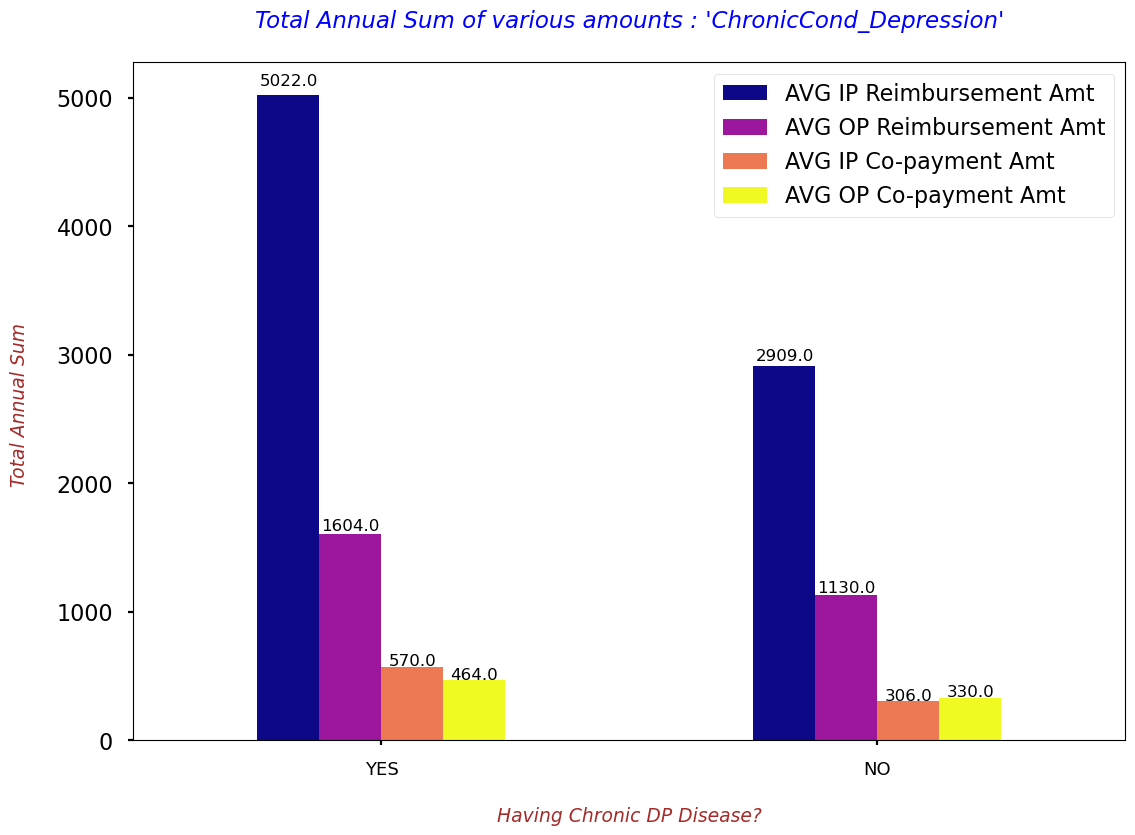

,AVG IP Reimbursement Amt,AVG OP Reimbursement Amt,AVG IP Co-payment Amt,AVG OP Co-payment Amt
ChronicCond_Depression,,,,
1,5022.162810,1603.871701,570.054771,464.285708
2,2909.102647,1129.606701,305.952607,329.963459


In [103]:
with plt.style.context('seaborn-poster'):
  fig = CC_DP_all_amts.plot(kind='bar', colormap='plasma')
  for p in fig.patches:
    width = p.get_width()
    height = p.get_height()
    x, y = p.get_xy()
    fig.annotate(f'{round(height,0)}', (x + width/2, y + height*1.015), ha='center', fontsize=12, rotation=0)

plt.xlabel("\nHaving Chronic DP Disease?", fontdict=label_font_dict)
plt.xticks(ticks=[0,1], labels=['YES', 'NO'], fontsize=13, rotation=0)
plt.ylabel("Total Annual Sum \n", fontdict=label_font_dict)
plt.title("Total Annual Sum of various amounts : 'ChronicCond_Depression'\n", fontdict=title_font_dict)
plt.show()

# 1 means +ve with Chronic DP Disease
# 2 means -ve with Chronic DP Disease
display(CC_DP_all_amts)

- **`OBSERVATION`**
  - The above graph is telling us below points:
    - Payer pays huge chunk of expenses specially when a beneficiary gets admitted with or without chronic HF disease. To be more precise, in case of +ve it is around 42%.
    - For other comparisons the difference is not very high.

### **Q15. Lets see the number of beneficiaries on the basis of 'ChronicCond_Diabetes'. And, the Annual IP & OP expenditures for such patients.**

In [104]:
# Number of beneficiaries with chronic or no-chronic conditions
pd.DataFrame(bene_train_df.groupby(['ChronicCond_Diabetes'])['BeneID'].count())

,BeneID
ChronicCond_Diabetes,
1,83391
2,55165


In [105]:
CC_DB_IP_R = pd.DataFrame(bene_train_df.groupby(['ChronicCond_Diabetes'])['IPAnnualReimbursementAmt'].sum() / bene_train_df.groupby(['ChronicCond_Diabetes'])['BeneID'].count())
CC_DB_IP_R.columns = ['AVG IP Reimbursement Amt']
CC_DB_IP_R

,AVG IP Reimbursement Amt
ChronicCond_Diabetes,
1,4870.622010
2,1830.815372


In [106]:
CC_DB_OP_R = pd.DataFrame(bene_train_df.groupby(['ChronicCond_Diabetes'])['OPAnnualReimbursementAmt'].sum() / bene_train_df.groupby(['ChronicCond_Diabetes'])['BeneID'].count())
CC_DB_OP_R.columns = ['AVG OP Reimbursement Amt']
CC_DB_OP_R

,AVG OP Reimbursement Amt
ChronicCond_Diabetes,
1,1607.259536
2,831.054110


In [107]:
CC_DB_IP_D = pd.DataFrame(bene_train_df.groupby(['ChronicCond_Diabetes'])['IPAnnualDeductibleAmt'].sum() / bene_train_df.groupby(['ChronicCond_Diabetes'])['BeneID'].count())
CC_DB_IP_D.columns = ['AVG IP Co-payment Amt']
CC_DB_IP_D

,AVG IP Co-payment Amt
ChronicCond_Diabetes,
1,534.254680
2,196.668359


In [108]:
CC_DB_OP_D = pd.DataFrame(bene_train_df.groupby(['ChronicCond_Diabetes'])['OPAnnualDeductibleAmt'].sum() / bene_train_df.groupby(['ChronicCond_Diabetes'])['BeneID'].count())
CC_DB_OP_D.columns = ['AVG OP Co-payment Amt']
CC_DB_OP_D

,AVG OP Co-payment Amt
ChronicCond_Diabetes,
1,464.345421
2,246.767008


In [109]:
CC_DB_all_amts = pd.concat([CC_DB_IP_R, CC_DB_OP_R, CC_DB_IP_D, CC_DB_OP_D], axis=1)
CC_DB_all_amts

,AVG IP Reimbursement Amt,AVG OP Reimbursement Amt,AVG IP Co-payment Amt,AVG OP Co-payment Amt
ChronicCond_Diabetes,,,,
1,4870.622010,1607.259536,534.254680,464.345421
2,1830.815372,831.054110,196.668359,246.767008


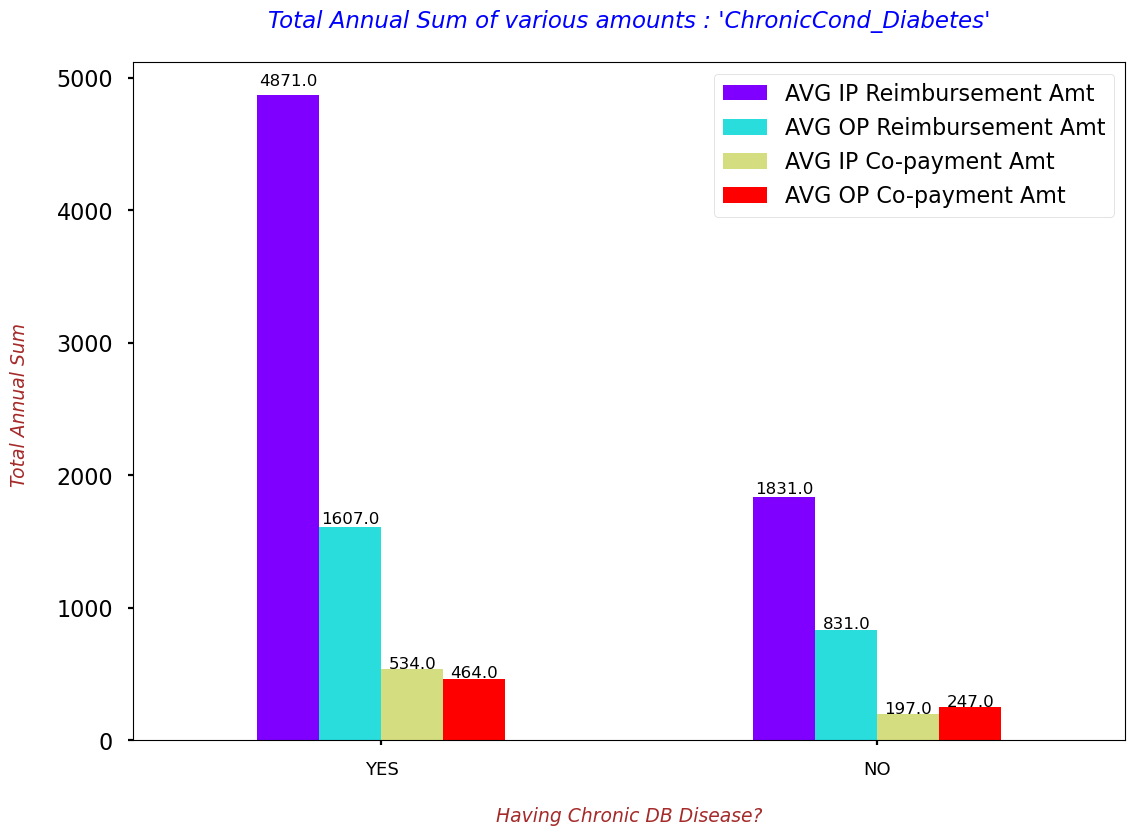

,AVG IP Reimbursement Amt,AVG OP Reimbursement Amt,AVG IP Co-payment Amt,AVG OP Co-payment Amt
ChronicCond_Diabetes,,,,
1,4870.622010,1607.259536,534.254680,464.345421
2,1830.815372,831.054110,196.668359,246.767008


In [110]:
with plt.style.context('seaborn-poster'):
  fig = CC_DB_all_amts.plot(kind='bar', colormap='rainbow')
  for p in fig.patches:
    width = p.get_width()
    height = p.get_height()
    x, y = p.get_xy()
    fig.annotate(f'{round(height,0)}', (x + width/2, y + height*1.015), ha='center', fontsize=12, rotation=0)

plt.xlabel("\nHaving Chronic DB Disease?", fontdict=label_font_dict)
plt.xticks(ticks=[0,1], labels=['YES', 'NO'], fontsize=13, rotation=0)
plt.ylabel("Total Annual Sum \n", fontdict=label_font_dict)
plt.title("Total Annual Sum of various amounts : 'ChronicCond_Diabetes'\n", fontdict=title_font_dict)
plt.show()

# 1 means +ve with Chronic DB Disease
# 2 means -ve with Chronic DB Disease
display(CC_DB_all_amts)

- **`OBSERVATION`**
  - The above graph is telling us below points:
    - Payer pays huge chunk of expenses specially when a beneficiary gets admitted with or without chronic HF disease. To be more precise, in case of +ve it is more than 50%.
    - For other comparisons the difference is not very high.

### **Q16. Lets see the number of beneficiaries on the basis of 'ChronicCond_IschemicHeart'. And, the Annual IP & OP expenditures for such patients.**

In [111]:
# Number of beneficiaries with chronic or no-chronic conditions
pd.DataFrame(bene_train_df.groupby(['ChronicCond_IschemicHeart'])['BeneID'].count())

,BeneID
ChronicCond_IschemicHeart,
1,93644
2,44912


In [112]:
CC_IH_IP_R = pd.DataFrame(bene_train_df.groupby(['ChronicCond_IschemicHeart'])['IPAnnualReimbursementAmt'].sum() / bene_train_df.groupby(['ChronicCond_IschemicHeart'])['BeneID'].count())
CC_IH_IP_R.columns = ['AVG IP Reimbursement Amt']
CC_IH_IP_R

,AVG IP Reimbursement Amt
ChronicCond_IschemicHeart,
1,4697.683034
2,1497.442554


In [113]:
CC_IH_OP_R = pd.DataFrame(bene_train_df.groupby(['ChronicCond_IschemicHeart'])['OPAnnualReimbursementAmt'].sum() / bene_train_df.groupby(['ChronicCond_IschemicHeart'])['BeneID'].count())
CC_IH_OP_R.columns = ['AVG OP Reimbursement Amt']
CC_IH_OP_R

,AVG OP Reimbursement Amt
ChronicCond_IschemicHeart,
1,1521.077485
2,833.547827


In [114]:
CC_IH_IP_D = pd.DataFrame(bene_train_df.groupby(['ChronicCond_IschemicHeart'])['IPAnnualDeductibleAmt'].sum() / bene_train_df.groupby(['ChronicCond_IschemicHeart'])['BeneID'].count())
CC_IH_IP_D.columns = ['AVG IP Co-payment Amt']
CC_IH_IP_D

,AVG IP Co-payment Amt
ChronicCond_IschemicHeart,
1,506.661676
2,177.133416


In [115]:
CC_IH_OP_D = pd.DataFrame(bene_train_df.groupby(['ChronicCond_IschemicHeart'])['OPAnnualDeductibleAmt'].sum() / bene_train_df.groupby(['ChronicCond_IschemicHeart'])['BeneID'].count())
CC_IH_OP_D.columns = ['AVG OP Co-payment Amt']
CC_IH_OP_D

,AVG OP Co-payment Amt
ChronicCond_IschemicHeart,
1,441.447535
2,244.839197


In [116]:
CC_IH_all_amts = pd.concat([CC_IH_IP_R, CC_IH_OP_R, CC_IH_IP_D, CC_IH_OP_D], axis=1)
CC_IH_all_amts

,AVG IP Reimbursement Amt,AVG OP Reimbursement Amt,AVG IP Co-payment Amt,AVG OP Co-payment Amt
ChronicCond_IschemicHeart,,,,
1,4697.683034,1521.077485,506.661676,441.447535
2,1497.442554,833.547827,177.133416,244.839197


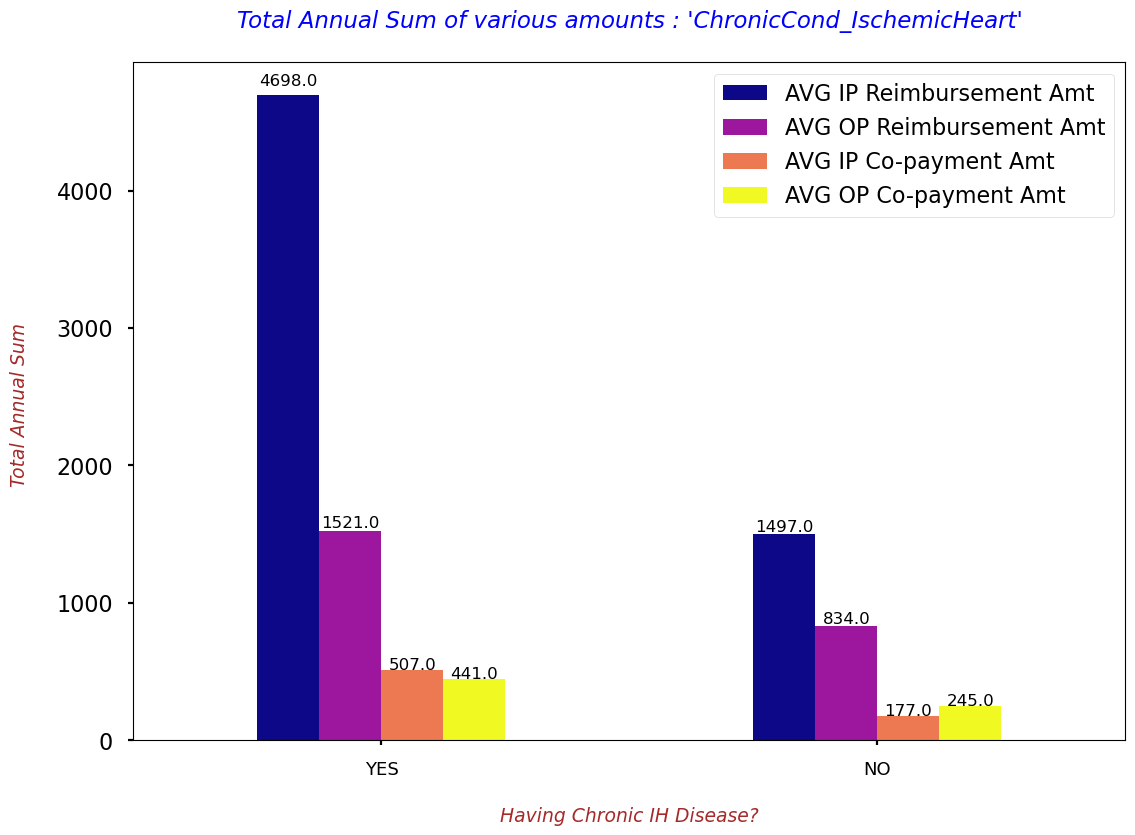

,AVG IP Reimbursement Amt,AVG OP Reimbursement Amt,AVG IP Co-payment Amt,AVG OP Co-payment Amt
ChronicCond_IschemicHeart,,,,
1,4697.683034,1521.077485,506.661676,441.447535
2,1497.442554,833.547827,177.133416,244.839197


In [117]:
with plt.style.context('seaborn-poster'):
  fig = CC_IH_all_amts.plot(kind='bar', colormap='plasma')

  for p in fig.patches:
    width = p.get_width()
    height = p.get_height()
    x, y = p.get_xy()
    fig.annotate(f'{round(height,0)}', (x + width/2, y + height*1.015), ha='center', fontsize=12, rotation=0)

plt.xlabel("\nHaving Chronic IH Disease?", fontdict=label_font_dict)
plt.xticks(ticks=[0,1], labels=['YES', 'NO'], fontsize=13, rotation=0)
plt.ylabel("Total Annual Sum \n", fontdict=label_font_dict)
plt.title("Total Annual Sum of various amounts : 'ChronicCond_IschemicHeart'\n", fontdict=title_font_dict)
plt.show()
    
# 1 means +ve with Chronic IH Disease
# 2 means -ve with Chronic IH Disease
display(CC_IH_all_amts)

- **`OBSERVATION`**
  - The above graph is telling us below points:
    - Payer pays huge chunk of expenses specially when a beneficiary gets admitted with or without chronic HF disease. To be more precise, in case of +ve it is more than 50%.
    - For other comparisons the difference is not very high.

### **Q17. Lets see the number of beneficiaries on the basis of 'ChronicCond_Osteoporasis'. And, the Annual IP & OP expenditures for such patients.**

In [118]:
# Number of beneficiaries with chronic or no-chronic conditions
pd.DataFrame(bene_train_df.groupby(['ChronicCond_Osteoporasis'])['BeneID'].count())

,BeneID
ChronicCond_Osteoporasis,
1,38059
2,100497


In [119]:
CC_OS_IP_R = pd.DataFrame(bene_train_df.groupby(['ChronicCond_Osteoporasis'])['IPAnnualReimbursementAmt'].sum() / bene_train_df.groupby(['ChronicCond_Osteoporasis'])['BeneID'].count())
CC_OS_IP_R.columns = ['AVG IP Reimbursement Amt']
CC_OS_IP_R

,AVG IP Reimbursement Amt
ChronicCond_Osteoporasis,
1,4608.419822
2,3301.303721


In [120]:
CC_OS_OP_R = pd.DataFrame(bene_train_df.groupby(['ChronicCond_Osteoporasis'])['OPAnnualReimbursementAmt'].sum() / bene_train_df.groupby(['ChronicCond_Osteoporasis'])['BeneID'].count())
CC_OS_OP_R.columns = ['AVG OP Reimbursement Amt']
CC_OS_OP_R

,AVG OP Reimbursement Amt
ChronicCond_Osteoporasis,
1,1494.709004
2,1223.807178


In [121]:
CC_OS_IP_D = pd.DataFrame(bene_train_df.groupby(['ChronicCond_Osteoporasis'])['IPAnnualDeductibleAmt'].sum() / bene_train_df.groupby(['ChronicCond_Osteoporasis'])['BeneID'].count())
CC_OS_IP_D.columns = ['AVG IP Co-payment Amt']
CC_OS_IP_D

,AVG IP Co-payment Amt
ChronicCond_Osteoporasis,
1,512.038204
2,357.359722


In [122]:
CC_OS_OP_D = pd.DataFrame(bene_train_df.groupby(['ChronicCond_Osteoporasis'])['OPAnnualDeductibleAmt'].sum() / bene_train_df.groupby(['ChronicCond_Osteoporasis'])['BeneID'].count())
CC_OS_OP_D.columns = ['AVG OP Co-payment Amt']
CC_OS_OP_D

,AVG OP Co-payment Amt
ChronicCond_Osteoporasis,
1,436.249271
2,355.552106


In [123]:
CC_OS_all_amts = pd.concat([CC_OS_IP_R, CC_OS_OP_R, CC_OS_IP_D, CC_OS_OP_D], axis=1)
CC_OS_all_amts

,AVG IP Reimbursement Amt,AVG OP Reimbursement Amt,AVG IP Co-payment Amt,AVG OP Co-payment Amt
ChronicCond_Osteoporasis,,,,
1,4608.419822,1494.709004,512.038204,436.249271
2,3301.303721,1223.807178,357.359722,355.552106


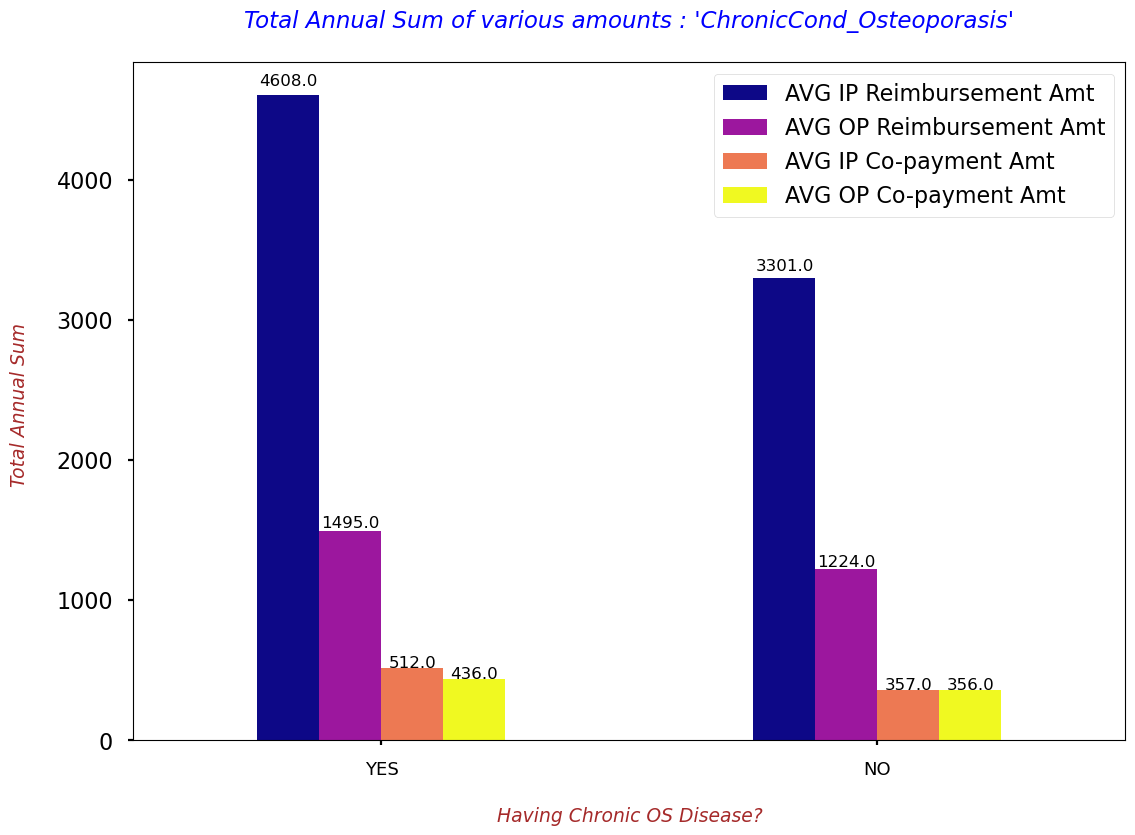

,AVG IP Reimbursement Amt,AVG OP Reimbursement Amt,AVG IP Co-payment Amt,AVG OP Co-payment Amt
ChronicCond_Osteoporasis,,,,
1,4608.419822,1494.709004,512.038204,436.249271
2,3301.303721,1223.807178,357.359722,355.552106


In [124]:
with plt.style.context('seaborn-poster'):
  fig = CC_OS_all_amts.plot(kind='bar', colormap='plasma')
  for p in fig.patches:
    width = p.get_width()
    height = p.get_height()
    x, y = p.get_xy()
    fig.annotate(f'{round(height,0)}', (x + width/2, y + height*1.015), ha='center', fontsize=12, rotation=0)
 
  plt.xlabel("\nHaving Chronic OS Disease?", fontdict=label_font_dict)
  plt.xticks(ticks=[0,1], labels=['YES', 'NO'], fontsize=13, rotation=0)
  plt.ylabel("Total Annual Sum \n", fontdict=label_font_dict)
  plt.title("Total Annual Sum of various amounts : 'ChronicCond_Osteoporasis'\n", fontdict=title_font_dict)
  plt.show()
# 1 means +ve with Chronic OS Disease
# 2 means -ve with Chronic OS Disease
display(CC_OS_all_amts)

- **`OBSERVATION`**
  - The above graph is telling us below points:
    - Payer pays huge chunk of expenses specially when a beneficiary gets admitted with or without chronic HF disease. To be more precise, in case of +ve the difference is not that high.
    - For other comparisons the difference is not very high.

### **Q18. Lets see the number of beneficiaries on the basis of 'ChronicCond_rheumatoidarthritis'. And, the Annual IP & OP expenditures for such patients.**

In [125]:
# Number of beneficiaries with chronic or no-chronic conditions
pd.DataFrame(bene_train_df.groupby(['ChronicCond_rheumatoidarthritis'])['BeneID'].count())

,BeneID
ChronicCond_rheumatoidarthritis,
1,35584
2,102972


In [126]:
CC_RH_IP_R = pd.DataFrame(bene_train_df.groupby(['ChronicCond_rheumatoidarthritis'])['IPAnnualReimbursementAmt'].sum() / bene_train_df.groupby(['ChronicCond_rheumatoidarthritis'])['BeneID'].count())
CC_RH_IP_R.columns = ['AVG IP Reimbursement Amt']
CC_RH_IP_R

,AVG IP Reimbursement Amt
ChronicCond_rheumatoidarthritis,
1,5102.027597
2,3162.145243


In [127]:
CC_RH_OP_R = pd.DataFrame(bene_train_df.groupby(['ChronicCond_rheumatoidarthritis'])['OPAnnualReimbursementAmt'].sum() / bene_train_df.groupby(['ChronicCond_rheumatoidarthritis'])['BeneID'].count())
CC_RH_OP_R.columns = ['AVG OP Reimbursement Amt']
CC_RH_OP_R

,AVG OP Reimbursement Amt
ChronicCond_rheumatoidarthritis,
1,1548.057835
2,1211.882745


In [128]:
CC_RH_IP_D = pd.DataFrame(bene_train_df.groupby(['ChronicCond_rheumatoidarthritis'])['IPAnnualDeductibleAmt'].sum() / bene_train_df.groupby(['ChronicCond_rheumatoidarthritis'])['BeneID'].count())
CC_RH_IP_D.columns = ['AVG IP Co-payment Amt']
CC_RH_IP_D

,AVG IP Co-payment Amt
ChronicCond_rheumatoidarthritis,
1,562.630789
2,343.594259


In [129]:
CC_RH_OP_D = pd.DataFrame(bene_train_df.groupby(['ChronicCond_rheumatoidarthritis'])['OPAnnualDeductibleAmt'].sum() / bene_train_df.groupby(['ChronicCond_rheumatoidarthritis'])['BeneID'].count())
CC_RH_OP_D.columns = ['AVG OP Co-payment Amt']
CC_RH_OP_D

,AVG OP Co-payment Amt
ChronicCond_rheumatoidarthritis,
1,453.423196
2,351.556928


In [130]:
CC_RH_all_amts = pd.concat([CC_RH_IP_R, CC_RH_OP_R, CC_RH_IP_D, CC_RH_OP_D], axis=1)
CC_RH_all_amts

,AVG IP Reimbursement Amt,AVG OP Reimbursement Amt,AVG IP Co-payment Amt,AVG OP Co-payment Amt
ChronicCond_rheumatoidarthritis,,,,
1,5102.027597,1548.057835,562.630789,453.423196
2,3162.145243,1211.882745,343.594259,351.556928


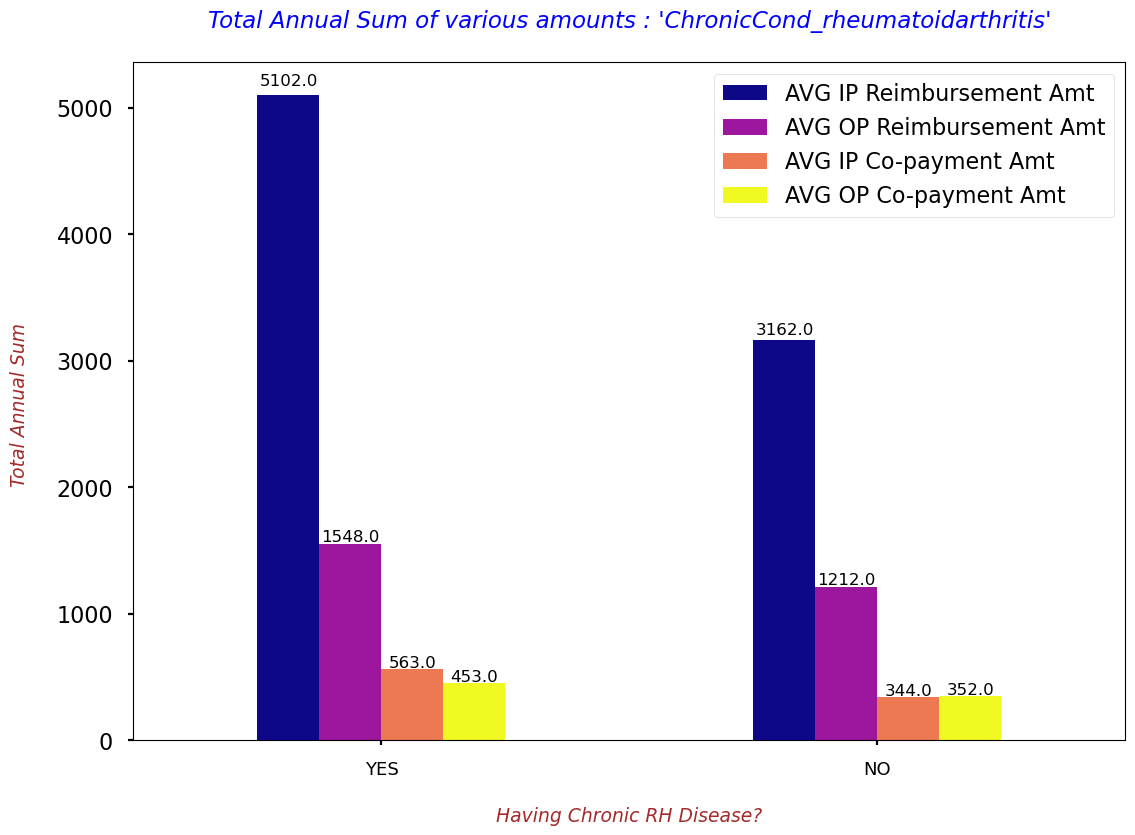

,AVG IP Reimbursement Amt,AVG OP Reimbursement Amt,AVG IP Co-payment Amt,AVG OP Co-payment Amt
ChronicCond_rheumatoidarthritis,,,,
1,5102.027597,1548.057835,562.630789,453.423196
2,3162.145243,1211.882745,343.594259,351.556928


In [131]:
with plt.style.context('seaborn-poster'):
  fig = CC_RH_all_amts.plot(kind='bar', colormap='plasma')
  for p in fig.patches:
    width = p.get_width()
    height = p.get_height()
    x, y = p.get_xy()
    fig.annotate(f'{round(height,0)}', (x + width/2, y + height*1.015), ha='center', fontsize=12, rotation=0)
  # Providing the labels and title to the graph
  plt.xlabel("\nHaving Chronic RH Disease?", fontdict=label_font_dict)
  plt.xticks(ticks=[0,1], labels=['YES', 'NO'], fontsize=13, rotation=0)
  plt.ylabel("Total Annual Sum \n", fontdict=label_font_dict)
  plt.title("Total Annual Sum of various amounts : 'ChronicCond_rheumatoidarthritis'\n", fontdict=title_font_dict)
  plt.show()
    
# 1 means +ve with Chronic RH Disease
# 2 means -ve with Chronic RH Disease
display(CC_RH_all_amts)

- **`OBSERVATION`**
  - The above graph is telling us below points:
    - Payer pays huge chunk of expenses specially when a beneficiary gets admitted with or without chronic HF disease. To be more precise, in case of +ve the difference is not that high.
    - For other comparisons the difference is not very high.

### **Q19. Lets see the number of beneficiaries on the basis of 'ChronicCond_stroke'. And, the Annual IP & OP expenditures for such patients.**

In [132]:
# Number of beneficiaries with chronic or no-chronic conditions
pd.DataFrame(bene_train_df.groupby(['ChronicCond_stroke'])['BeneID'].count())

,BeneID
ChronicCond_stroke,
1,10954
2,127602


In [133]:
CC_ST_IP_R = pd.DataFrame(bene_train_df.groupby(['ChronicCond_stroke'])['IPAnnualReimbursementAmt'].sum() / bene_train_df.groupby(['ChronicCond_stroke'])['BeneID'].count())
CC_ST_IP_R.columns = ['AVG IP Reimbursement Amt']
CC_ST_IP_R

,AVG IP Reimbursement Amt
ChronicCond_stroke,
1,8111.475260
2,3278.239134


In [134]:
CC_ST_OP_R = pd.DataFrame(bene_train_df.groupby(['ChronicCond_stroke'])['OPAnnualReimbursementAmt'].sum() / bene_train_df.groupby(['ChronicCond_stroke'])['BeneID'].count())
CC_ST_OP_R.columns = ['AVG OP Reimbursement Amt']
CC_ST_OP_R

,AVG OP Reimbursement Amt
ChronicCond_stroke,
1,1925.197188
2,1244.396404


In [135]:
CC_ST_IP_D = pd.DataFrame(bene_train_df.groupby(['ChronicCond_stroke'])['IPAnnualDeductibleAmt'].sum() / bene_train_df.groupby(['ChronicCond_stroke'])['BeneID'].count())
CC_ST_IP_D.columns = ['AVG IP Co-payment Amt']
CC_ST_IP_D

,AVG IP Co-payment Amt
ChronicCond_stroke,
1,861.399489
2,360.225326


In [136]:
CC_ST_OP_D = pd.DataFrame(bene_train_df.groupby(['ChronicCond_stroke'])['OPAnnualDeductibleAmt'].sum() / bene_train_df.groupby(['ChronicCond_stroke'])['BeneID'].count())
CC_ST_OP_D.columns = ['AVG OP Co-payment Amt']
CC_ST_OP_D

,AVG OP Co-payment Amt
ChronicCond_stroke,
1,535.947508
2,364.135061


In [137]:
CC_ST_all_amts = pd.concat([CC_ST_IP_R, CC_ST_OP_R, CC_ST_IP_D, CC_ST_OP_D], axis=1)
CC_ST_all_amts

,AVG IP Reimbursement Amt,AVG OP Reimbursement Amt,AVG IP Co-payment Amt,AVG OP Co-payment Amt
ChronicCond_stroke,,,,
1,8111.475260,1925.197188,861.399489,535.947508
2,3278.239134,1244.396404,360.225326,364.135061


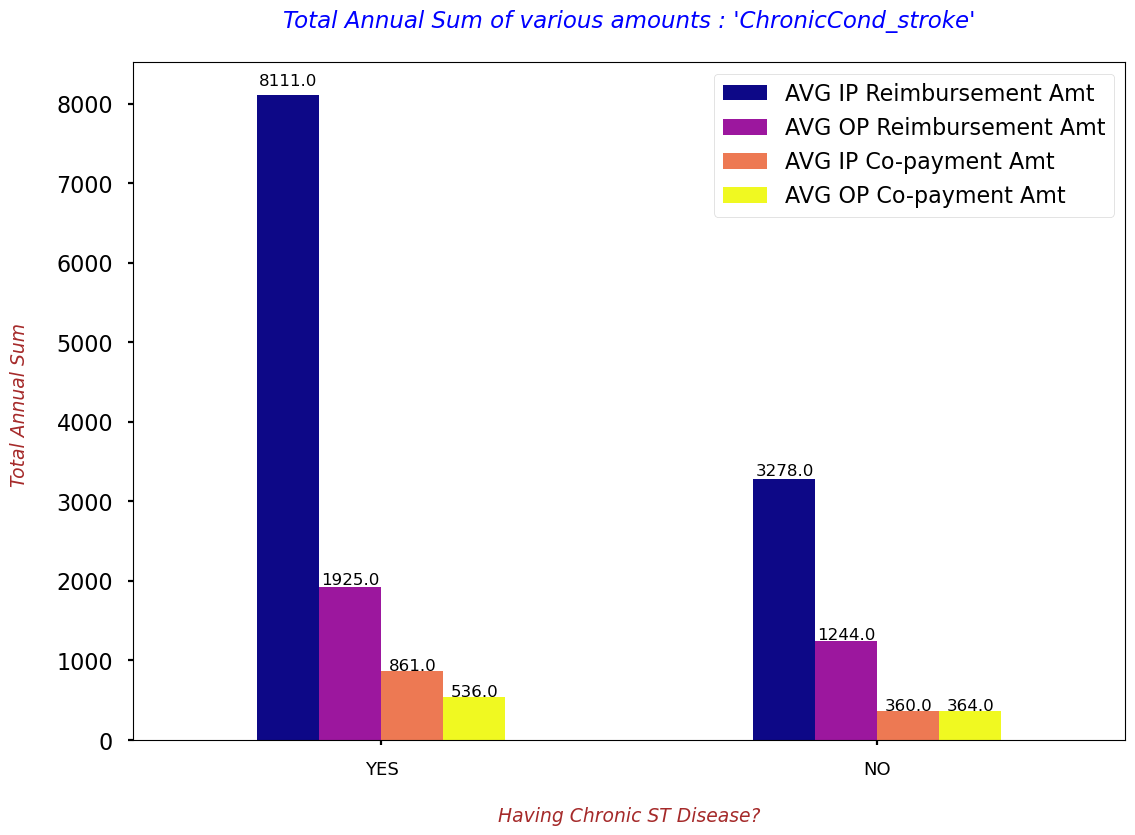

,AVG IP Reimbursement Amt,AVG OP Reimbursement Amt,AVG IP Co-payment Amt,AVG OP Co-payment Amt
ChronicCond_stroke,,,,
1,8111.475260,1925.197188,861.399489,535.947508
2,3278.239134,1244.396404,360.225326,364.135061


In [138]:
with plt.style.context('seaborn-poster'):
  fig = CC_ST_all_amts.plot(kind='bar', colormap='plasma')
  for p in fig.patches:
    width = p.get_width()
    height = p.get_height()
    x, y = p.get_xy()
    fig.annotate(f'{round(height,0)}', (x + width/2, y + height*1.015), ha='center', fontsize=12, rotation=0)
  
  plt.xlabel("\nHaving Chronic ST Disease?", fontdict=label_font_dict)
  plt.xticks(ticks=[0,1], labels=['YES', 'NO'], fontsize=13, rotation=0)
  plt.ylabel("Total Annual Sum \n", fontdict=label_font_dict)
  plt.title("Total Annual Sum of various amounts : 'ChronicCond_stroke'\n", fontdict=title_font_dict)
  plt.show()
    
# 1 means +ve with Chronic ST Disease
# 2 means -ve with Chronic ST Disease
display(CC_ST_all_amts)

- **`OBSERVATION`**
  - The above graph is telling us below points:
    - Payer pays huge chunk of expenses specially when a beneficiary gets admitted with or without chronic HF disease. To be more precise, in case of +ve the difference is more than 50%.
    - For other comparisons the difference is not very high.

### **Q20. Lets see the number of beneficiaries on the basis of 'RenalDiseaseIndicator'. And, the Annual IP & OP expenditures for such patients.**

In [139]:
# Number of beneficiaries with chronic or no-chronic conditions
pd.DataFrame(bene_train_df.groupby(['RenalDiseaseIndicator'])['BeneID'].count())

,BeneID
RenalDiseaseIndicator,
No,118978
Yes,19578


In [140]:
RKD_IP_R = pd.DataFrame(bene_train_df.groupby(['RenalDiseaseIndicator'])['IPAnnualReimbursementAmt'].sum() / bene_train_df.groupby(['RenalDiseaseIndicator'])['BeneID'].count())
RKD_IP_R.columns = ['AVG IP Reimbursement Amt']
RKD_IP_R

,AVG IP Reimbursement Amt
RenalDiseaseIndicator,
No,3051.430264
Yes,7360.808050


In [141]:
RKD_OP_R = pd.DataFrame(bene_train_df.groupby(['RenalDiseaseIndicator'])['OPAnnualReimbursementAmt'].sum() / bene_train_df.groupby(['RenalDiseaseIndicator'])['BeneID'].count())
RKD_OP_R.columns = ['AVG OP Reimbursement Amt']
RKD_OP_R

,AVG OP Reimbursement Amt
RenalDiseaseIndicator,
No,1047.351611
Yes,2822.774543


In [142]:
RKD_IP_D = pd.DataFrame(bene_train_df.groupby(['RenalDiseaseIndicator'])['IPAnnualDeductibleAmt'].sum() / bene_train_df.groupby(['RenalDiseaseIndicator'])['BeneID'].count())
RKD_IP_D.columns = ['AVG IP Co-payment Amt']
RKD_IP_D

,AVG IP Co-payment Amt
RenalDiseaseIndicator,
No,342.384239
Yes,749.057616


In [143]:
RKD_OP_D = pd.DataFrame(bene_train_df.groupby(['RenalDiseaseIndicator'])['OPAnnualDeductibleAmt'].sum() / bene_train_df.groupby(['RenalDiseaseIndicator'])['BeneID'].count())
RKD_OP_D.columns = ['AVG OP Co-payment Amt']
RKD_OP_D

,AVG OP Co-payment Amt
RenalDiseaseIndicator,
No,311.659139
Yes,779.167944


In [144]:
RKD_all_amts = pd.concat([RKD_IP_R, RKD_OP_R, RKD_IP_D, RKD_OP_D], axis=1)
RKD_all_amts

,AVG IP Reimbursement Amt,AVG OP Reimbursement Amt,AVG IP Co-payment Amt,AVG OP Co-payment Amt
RenalDiseaseIndicator,,,,
No,3051.430264,1047.351611,342.384239,311.659139
Yes,7360.808050,2822.774543,749.057616,779.167944


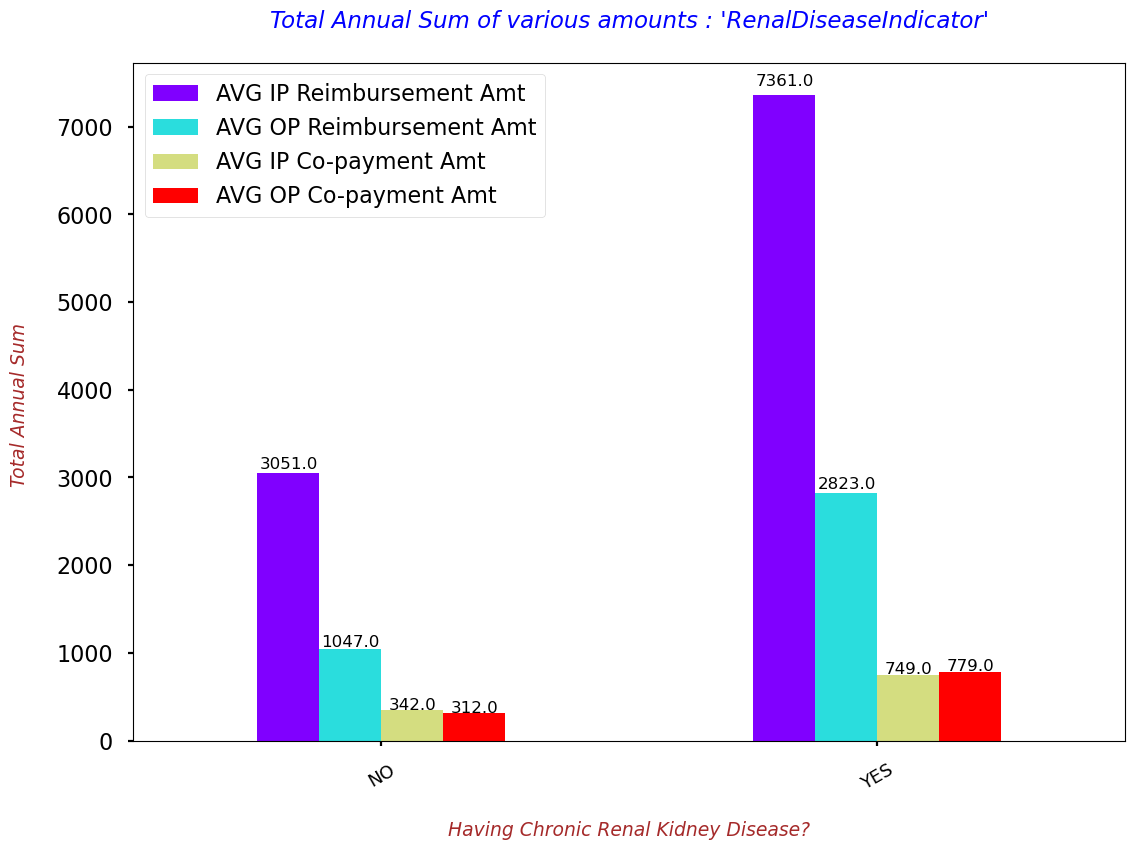

,AVG IP Reimbursement Amt,AVG OP Reimbursement Amt,AVG IP Co-payment Amt,AVG OP Co-payment Amt
RenalDiseaseIndicator,,,,
No,3051.430264,1047.351611,342.384239,311.659139
Yes,7360.808050,2822.774543,749.057616,779.167944


In [145]:
with plt.style.context('seaborn-poster'):
  fig = RKD_all_amts.plot(kind='bar', colormap='rainbow')
  for p in fig.patches:
    width = p.get_width()
    height = p.get_height()
    x, y = p.get_xy()
    fig.annotate(f'{round(height,0)}', (x + width/2, y + height*1.015), ha='center', fontsize=12, rotation=0)
  
  plt.xlabel("\nHaving Chronic Renal Kidney Disease?", fontdict=label_font_dict)
  plt.xticks(ticks=[0,1], labels=['NO', 'YES'], fontsize=13, rotation=30)
  plt.ylabel("Total Annual Sum \n", fontdict=label_font_dict)
  plt.title("Total Annual Sum of various amounts : 'RenalDiseaseIndicator'\n", fontdict=title_font_dict)
  plt.show()
    
# Y means +ve with Renal Kidney Disease
# 0 means -ve with Renal Kidney Disease
display(RKD_all_amts)

- **`OBSERVATION`**
  - The above graph is telling us below points:
    - Payer pays huge chunk of expenses specially when a beneficiary gets admitted with or without Renal Kidney Disease. To be more precise, in case of +ve the difference is more than 50%.
    - For other comparisons the difference is not very high.

### **Q21. Lets visualize the spread of Annual IP and OP expenditures through out the AGE and its assciated features for males and females.**

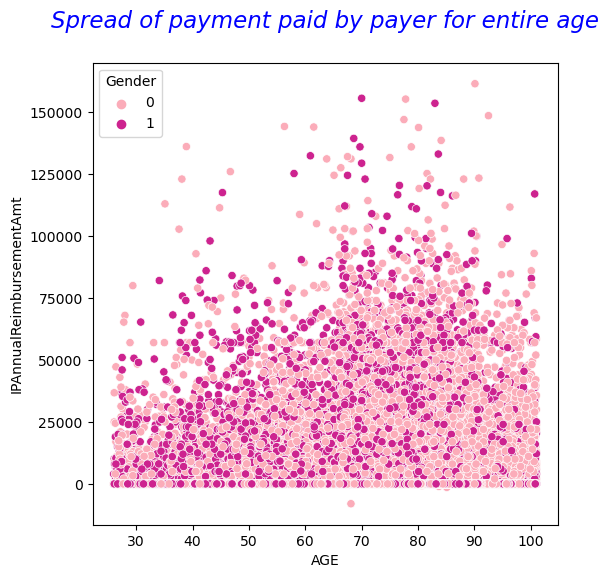

In [146]:
plt.figure(figsize=(6,6))
sns.scatterplot(data=bene_train_df, x='AGE', y='IPAnnualReimbursementAmt', hue='Gender', palette='RdPu')
plt.title("Spread of payment paid by payer for entire age\n", fontdict=title_font_dict)
plt.show()

- **`OBSERVATION`**
  - The above graph shows us the complete overlapping of data points.

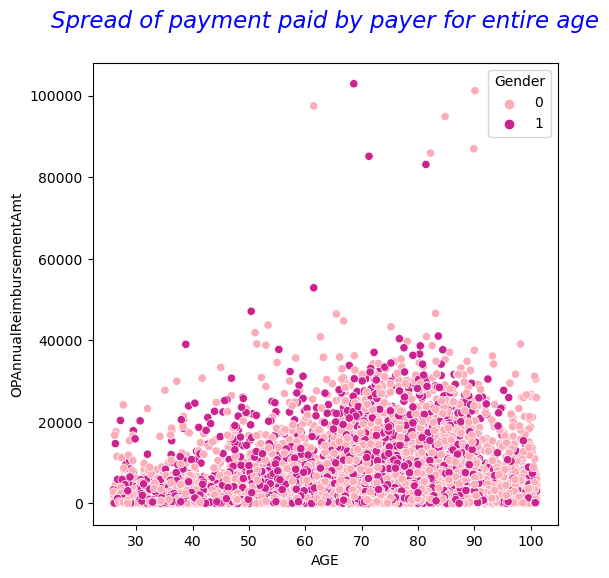

In [147]:
plt.figure(figsize=(6,6))
sns.scatterplot(data=bene_train_df, x='AGE', y='OPAnnualReimbursementAmt', hue='Gender', palette='RdPu')
plt.title("Spread of payment paid by payer for entire age\n", fontdict=title_font_dict)
plt.show()

- **`OBSERVATION`**
  - The above graph shows us the complete overlapping of data points.

- **(AGE GROUPS) , (IPAnnualReimbursementAmt) and (GENDER)**

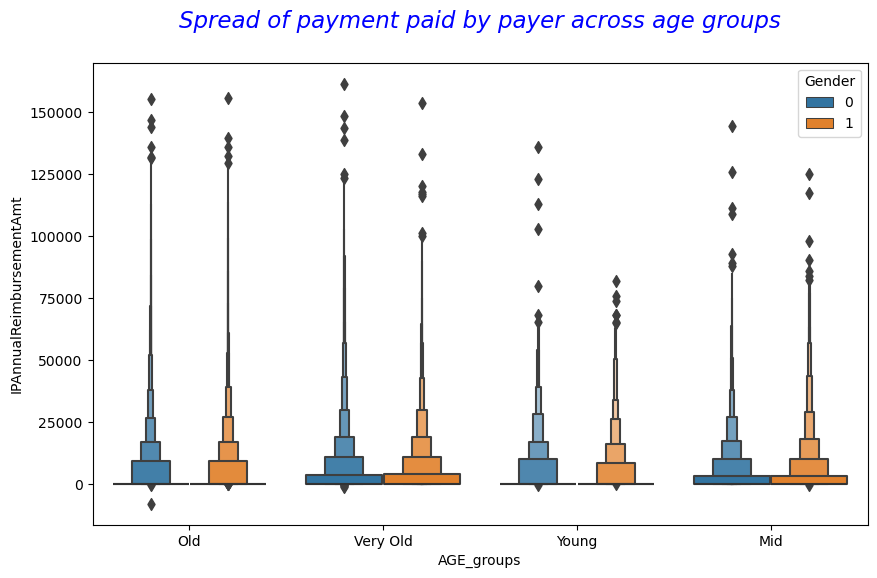

In [148]:
plt.figure(figsize=(10,6))
sns.boxenplot(data=bene_train_df, x='AGE_groups', y='IPAnnualReimbursementAmt', hue='Gender')
plt.title("Spread of payment paid by payer across age groups\n", fontdict=title_font_dict)
plt.show()

- **`OBSERVATION`**
  - The above graph shows us there is no such difference in the amounts across different AGE Groups.

- **(AGE GROUPS) , (OPAnnualReimbursementAmt) and (GENDER)**

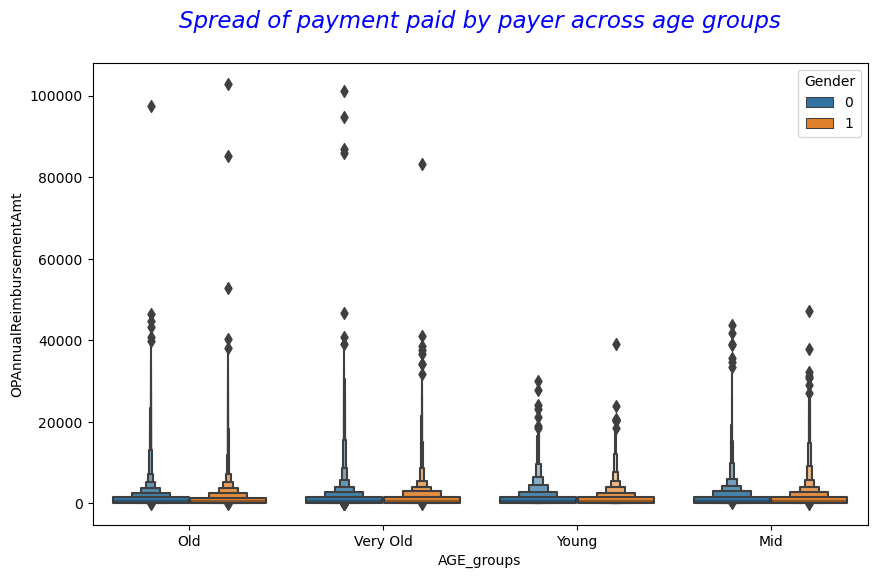

In [149]:
plt.figure(figsize=(10,6))
sns.boxenplot(data=bene_train_df, x='AGE_groups', y='OPAnnualReimbursementAmt', hue='Gender')
plt.title("Spread of payment paid by payer across age groups\n", fontdict=title_font_dict)
plt.show()

- **`OBSERVATION`**
  - The above graph shows us there is no such difference in the amounts across different AGE Groups.

- **(DOB MONTH) , (IPAnnualReimbursementAmt) and (GENDER)**

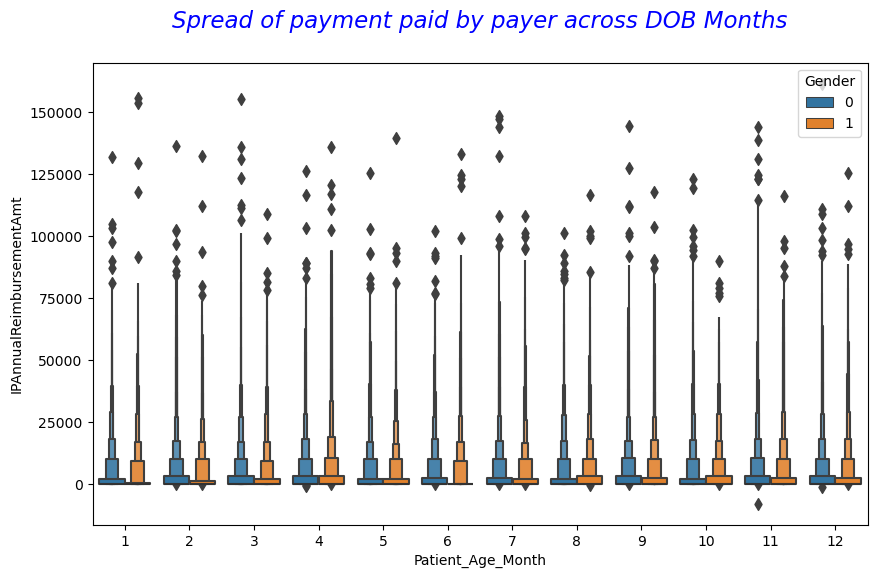

In [150]:
plt.figure(figsize=(10,6))
sns.boxenplot(data=bene_train_df, x='Patient_Age_Month', y='IPAnnualReimbursementAmt', hue='Gender')
plt.title("Spread of payment paid by payer across DOB Months\n", fontdict=title_font_dict)
plt.legend(loc='upper right', title="Gender")
plt.show()

- **`OBSERVATION`**
  - The above graph shows us there is no such difference in the amounts across different AGE Groups.

- **(DOB MONTH) , (OPAnnualReimbursementAmt) and (GENDER)**

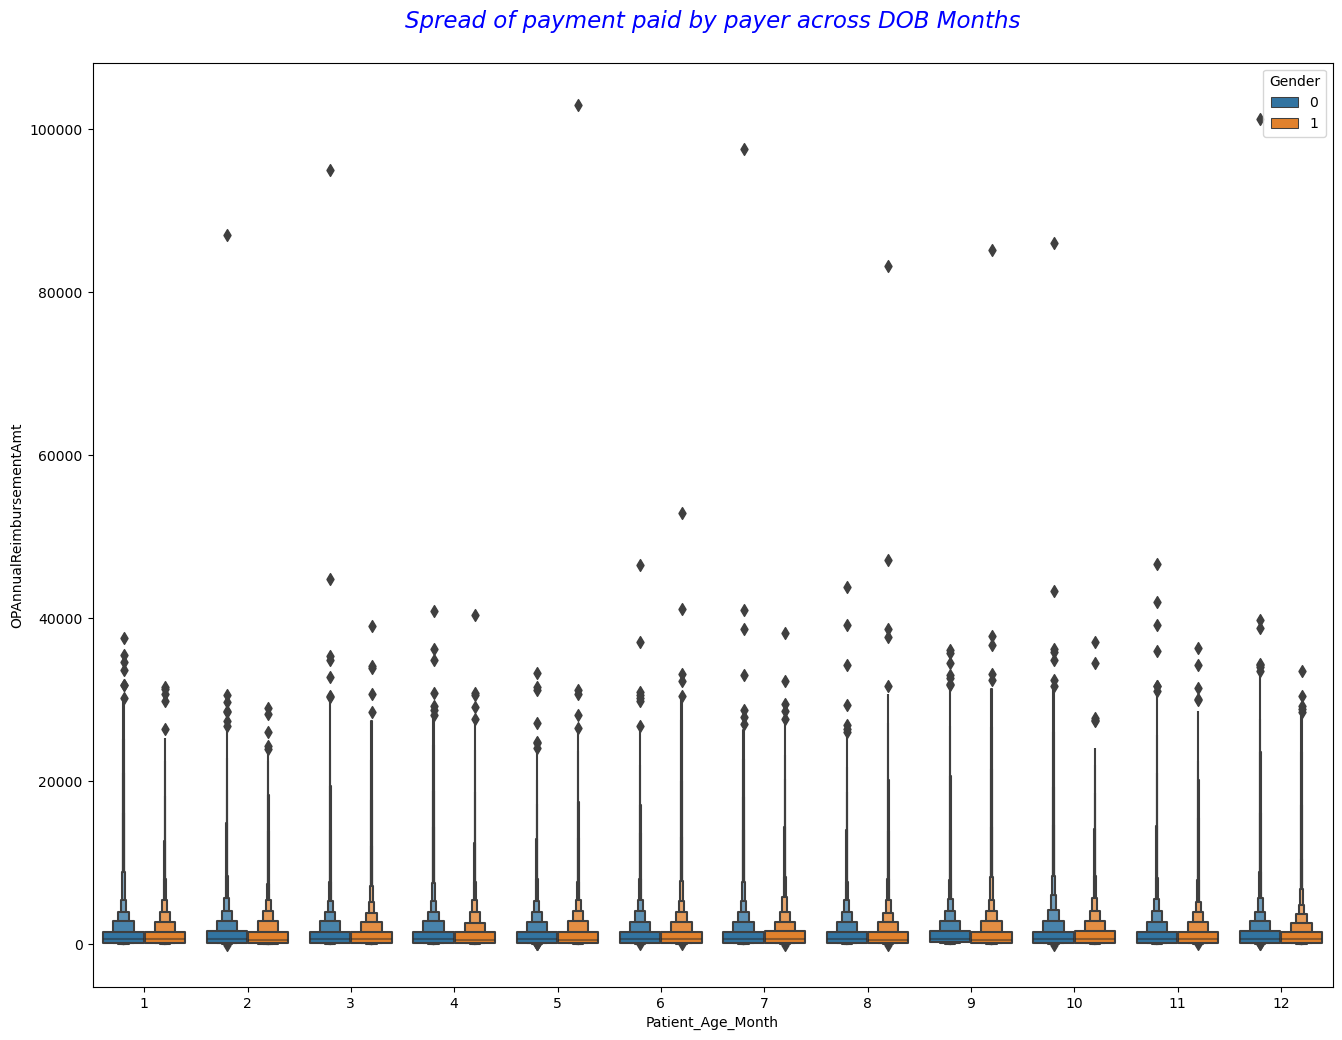

In [151]:
plt.figure(figsize=(16,12))
sns.boxenplot(data=bene_train_df, x='Patient_Age_Month', y='OPAnnualReimbursementAmt', hue='Gender')
plt.title("Spread of payment paid by payer across DOB Months\n", fontdict=title_font_dict)
plt.legend(loc='upper right', title="Gender")
plt.show()

- **`OBSERVATION`**
  - The above graph shows us there is no such difference in the amounts across different AGE Groups.

- **(DOB YEARS) , (IPAnnualReimbursementAmt) and (GENDER)**

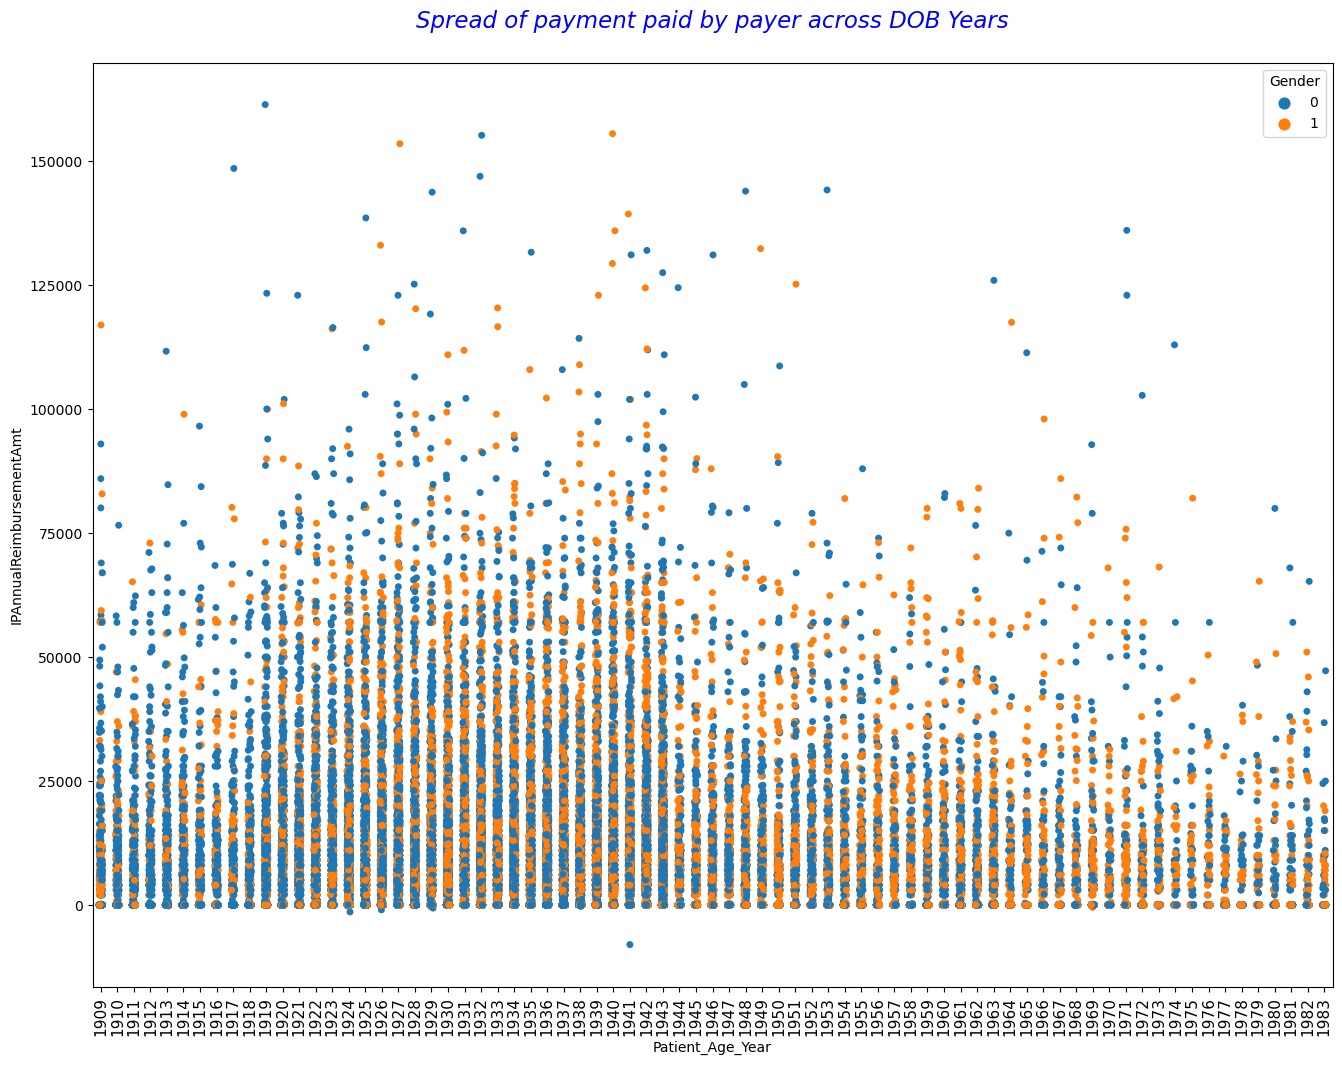

In [152]:
plt.figure(figsize=(16,12))
sns.stripplot(data=bene_train_df, x='Patient_Age_Year', y='IPAnnualReimbursementAmt', hue='Gender')
plt.xticks(rotation=90, fontsize=11)
plt.title("Spread of payment paid by payer across DOB Years\n", fontdict=title_font_dict)
plt.show()

- **`OBSERVATION`**
  - The above graph shows us there is no such difference in the amounts across different AGE Groups.

- **(DOB YEARS) , (OPAnnualReimbursementAmt) and (GENDER)**

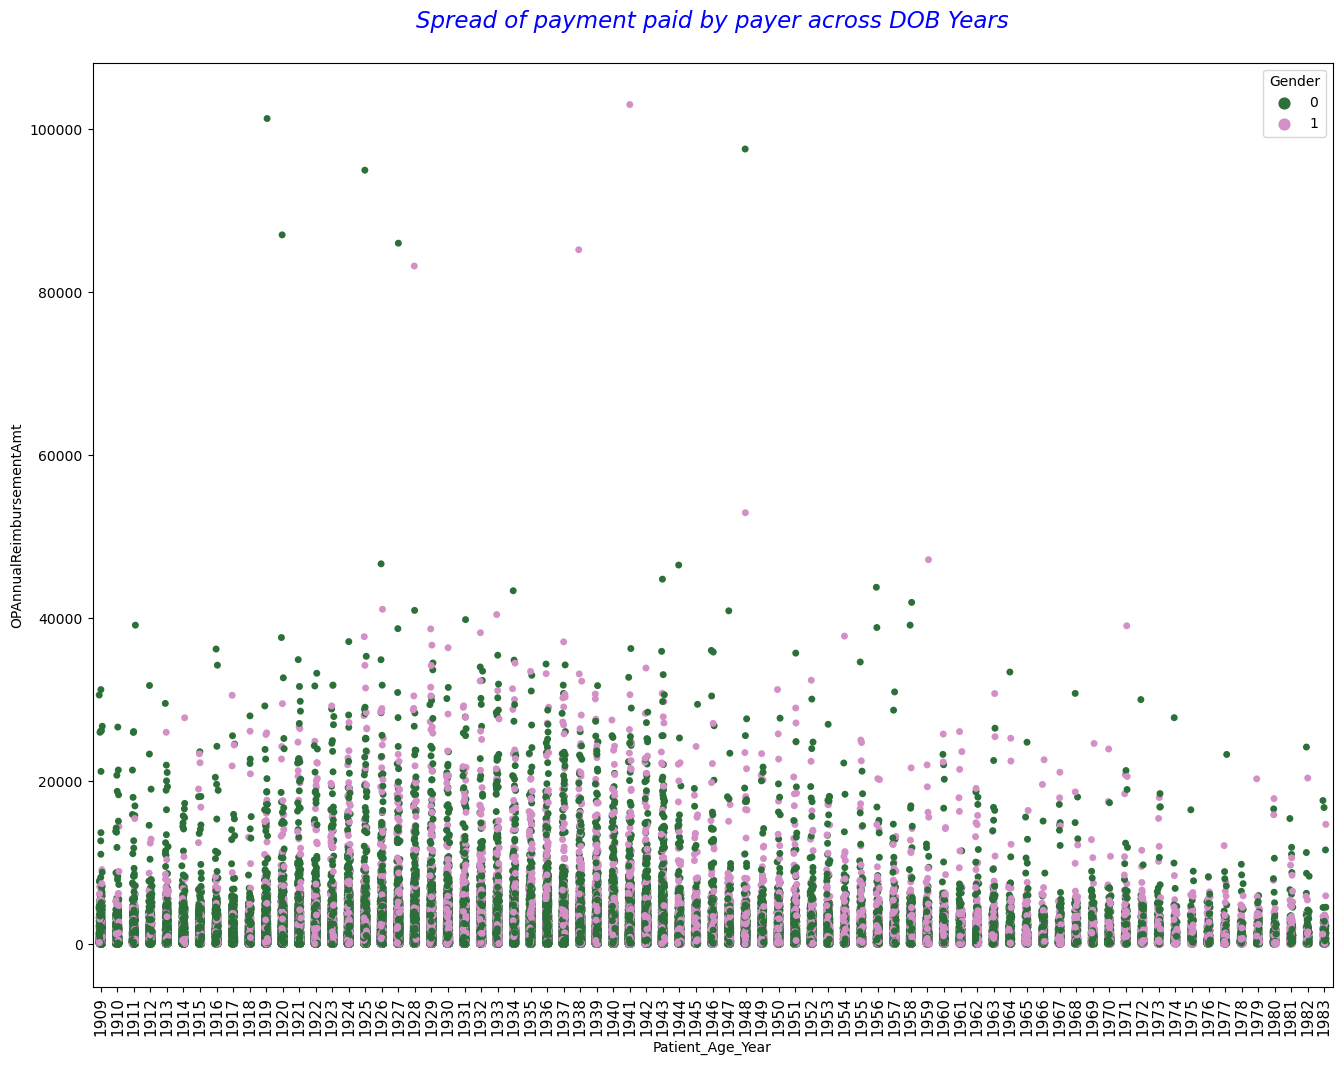

In [153]:
plt.figure(figsize=(16,12))
sns.stripplot(data=bene_train_df, x='Patient_Age_Year', y='OPAnnualReimbursementAmt', hue='Gender', palette='cubehelix')
plt.xticks(rotation=90, fontsize=11)
plt.title("Spread of payment paid by payer across DOB Years\n", fontdict=title_font_dict)
plt.show()

- **`OBSERVATION`**
  - The above graph shows us there is no such difference in the amounts across different AGE Groups.

- **(LIFE Status) , (IPAnnualReimbursementAmt) and (GENDER)**

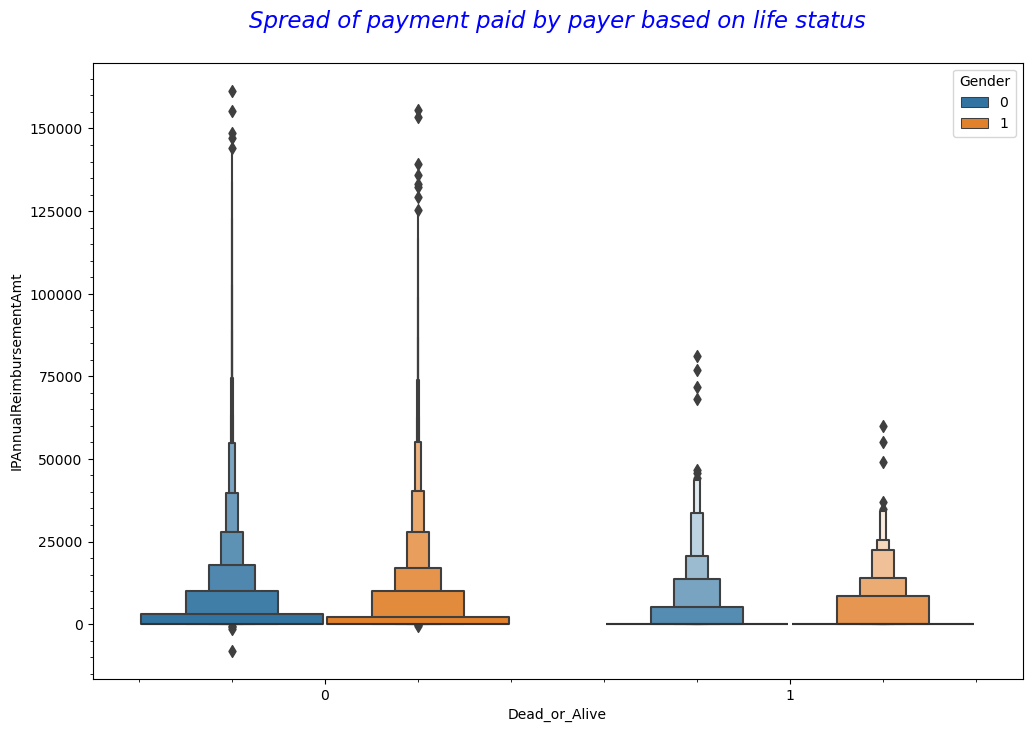

In [154]:
plt.figure(figsize=(12,8))
sns.boxenplot(data=bene_train_df, x='Dead_or_Alive', y='IPAnnualReimbursementAmt', hue='Gender')
plt.minorticks_on()
plt.title("Spread of payment paid by payer based on life status\n", fontdict=title_font_dict)
plt.show()

- **`OBSERVATION`**
  - The above graph shows us there is no such difference in the amounts across different AGE Groups.

- **(LIFE STATUS) , (OPAnnualReimbursementAmt) and (GENDER)**

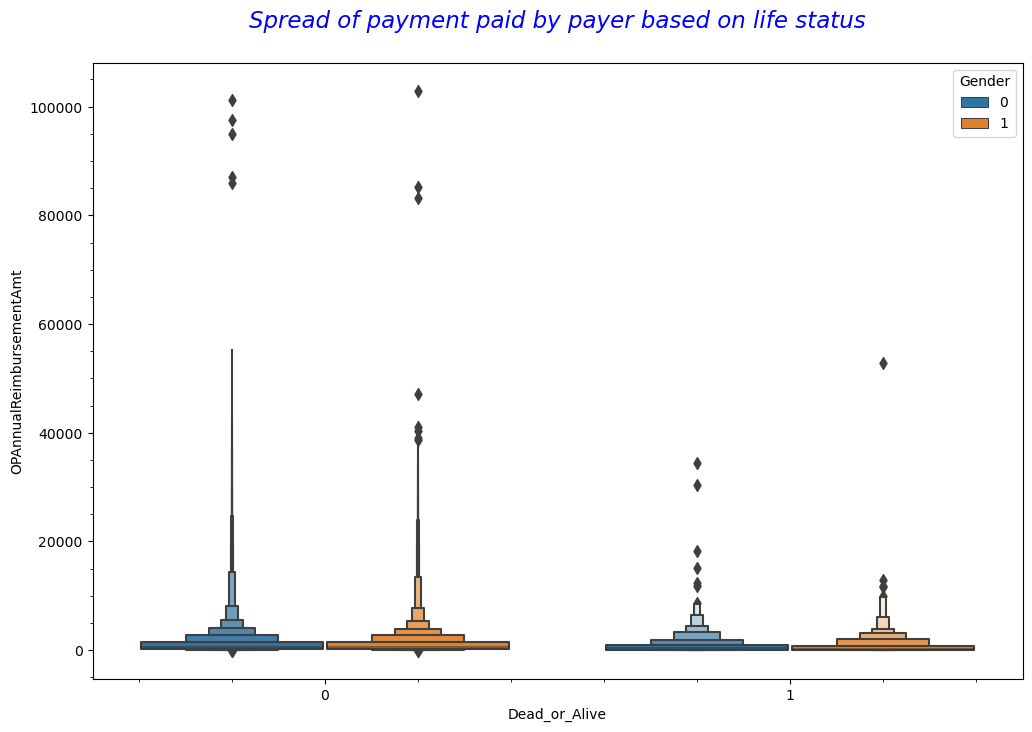

In [155]:
plt.figure(figsize=(12,8))
sns.boxenplot(data=bene_train_df, x='Dead_or_Alive', y='OPAnnualReimbursementAmt', hue='Gender')
plt.minorticks_on()
plt.title("Spread of payment paid by payer based on life status\n", fontdict=title_font_dict)
plt.show()

- **`OBSERVATION`**
  - The above graph shows us there is no such difference in the amounts across different AGE Groups.

- **(HUMAN RACE) , (IPAnnualReimbursementAmt) and (GENDER)**

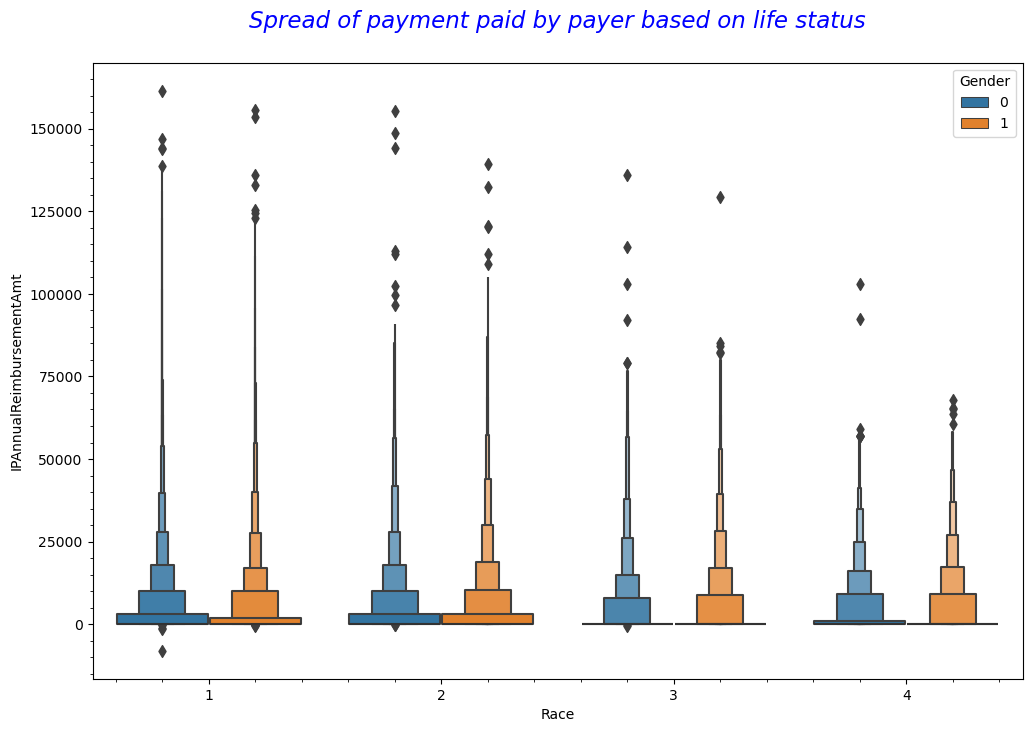

In [156]:
plt.figure(figsize=(12,8))
sns.boxenplot(data=bene_train_df, x='Race', y='IPAnnualReimbursementAmt', hue='Gender')
plt.minorticks_on()
plt.title("Spread of payment paid by payer based on life status\n", fontdict=title_font_dict)
plt.show()

- **`OBSERVATION`**
  - The above graph shows us there is no such difference in the amounts across different AGE Groups.

- **(HUMAN RACE) , (OPAnnualReimbursementAmt) and (GENDER)**

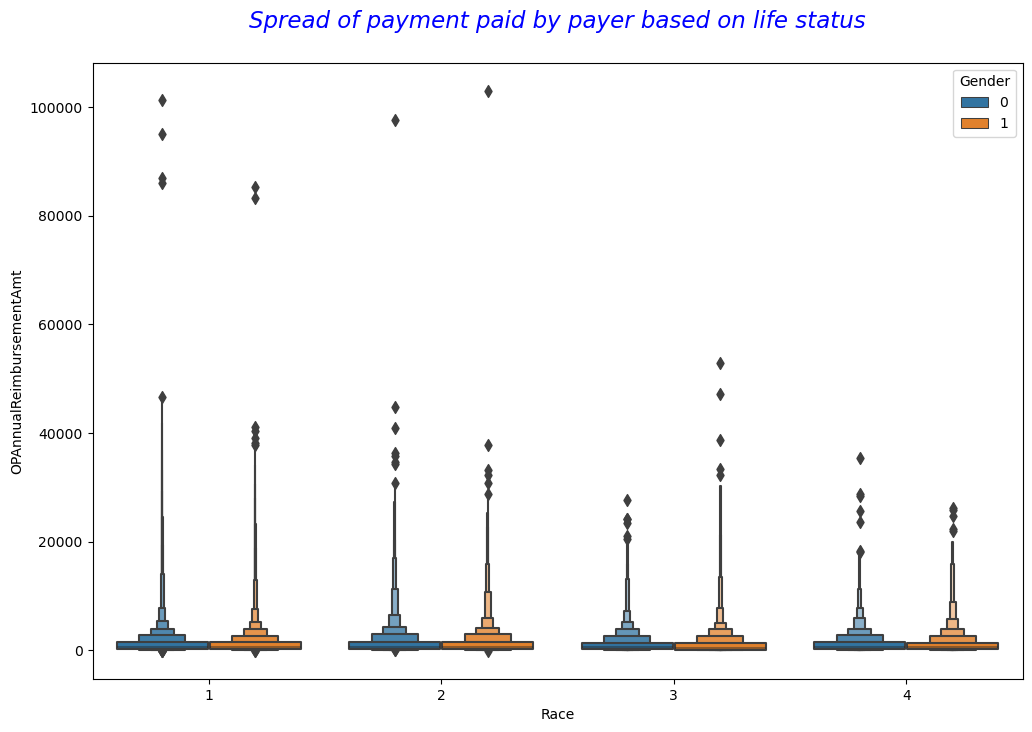

In [157]:
plt.figure(figsize=(12,8))
sns.boxenplot(data=bene_train_df, x='Race', y='OPAnnualReimbursementAmt', hue='Gender')
plt.title("Spread of payment paid by payer based on life status\n", fontdict=title_font_dict)
plt.show()

- **`OBSERVATION`**
  - The above graph shows us there is no such difference in the amounts across different AGE Groups.

# **`BENE - EDA - SUMMARY`**

1. For the below mentioned features, based on the above initial analysis it looks like these might not be able to provide much information or differentiation but still I would like to check them after adding CLAIMS data.
    - `DOB YEAR`
    - `DOB MONTH`
    - `AGE GROUPS`
    - `LIFE STATUS`
    - `HUMAN RACE`
    - `STATE`
      
      
2. For the below mentioned features majority of the values are same which most probably won't be of any use thus removing these from BENE dataset.
    - `NoOfMonths_PartACov`
    - `NoOfMonths_PartBCov`
    

3. The `Pre-disease` indicators looks like important features based on the initial analysis thus it would interesting to see how much they are useful after adding CLAIMS dataset.


4. `Date of Death` is also removed from the dataset, as we have already calculated bene age, life status and others out of it.

In [158]:
bene_train_df.drop(["NoOfMonths_PartACov", "NoOfMonths_PartBCov"], axis=1, inplace=True)

In [159]:
bene_train_df.shape

(138556, 27)

In [160]:
bene_train_df.head()

,BeneID,DOB,Gender,Race,RenalDiseaseIndicator,State,County,ChronicCond_Alzheimer,ChronicCond_Heartfailure,ChronicCond_KidneyDisease,ChronicCond_Cancer,ChronicCond_ObstrPulmonary,ChronicCond_Depression,ChronicCond_Diabetes,ChronicCond_IschemicHeart,ChronicCond_Osteoporasis,ChronicCond_rheumatoidarthritis,ChronicCond_stroke,IPAnnualReimbursementAmt,IPAnnualDeductibleAmt,OPAnnualReimbursementAmt,OPAnnualDeductibleAmt,Patient_Age_Year,Patient_Age_Month,Dead_or_Alive,AGE,AGE_groups
0,BENE11001,1943-01-01,1,1,No,39,230,1,2,1,2,2,1,1,1,2,1,1,36000,3204,60,70,1943,1,0,67.0,Old
1,BENE11002,1936-09-01,0,1,No,39,280,2,2,2,2,2,2,2,2,2,2,2,0,0,30,50,1936,9,0,73.3,Old
2,BENE11003,1936-08-01,1,1,No,52,590,1,2,2,2,2,2,2,1,2,2,2,0,0,90,40,1936,8,0,73.4,Old
3,BENE11004,1922-07-01,1,1,No,39,270,1,1,2,2,2,2,1,1,1,1,2,0,0,1810,760,1922,7,0,87.5,Very Old
4,BENE11005,1935-09-01,1,1,No,24,680,2,2,2,2,1,2,1,2,2,2,2,0,0,1790,1200,1935,9,0,74.3,Old


In [161]:
bene_train_df.to_csv("train_bene_1.csv")

# **IP & OP Data - EDA**

In [162]:
bene_train_df = pd.read_csv("Train_Beneficiarydata-1542865627584.csv")
ip_train_df = pd.read_csv("Train_Inpatientdata-1542865627584.csv")
op_train_df = pd.read_csv("Train_Outpatientdata-1542865627584.csv")

## ***Records_counts_for_In-patient_&_Out-patient_Data***

- **In-patients**

In [163]:
ip_train_df.shape

(40474, 30)

In [164]:
display(ip_train_df.info())
print('*'*50)
display(ip_train_df.describe())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40474 entries, 0 to 40473
Data columns (total 30 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   BeneID                  40474 non-null  object 
 1   ClaimID                 40474 non-null  object 
 2   ClaimStartDt            40474 non-null  object 
 3   ClaimEndDt              40474 non-null  object 
 4   Provider                40474 non-null  object 
 5   InscClaimAmtReimbursed  40474 non-null  int64  
 6   AttendingPhysician      40362 non-null  object 
 7   OperatingPhysician      23830 non-null  object 
 8   OtherPhysician          4690 non-null   object 
 9   AdmissionDt             40474 non-null  object 
 10  ClmAdmitDiagnosisCode   40474 non-null  object 
 11  DeductibleAmtPaid       39575 non-null  float64
 12  DischargeDt             40474 non-null  object 
 13  DiagnosisGroupCode      40474 non-null  object 
 14  ClmDiagnosisCode_1      40474 non-null

None

**************************************************


,InscClaimAmtReimbursed,DeductibleAmtPaid,ClmProcedureCode_1,ClmProcedureCode_2,ClmProcedureCode_3,ClmProcedureCode_4,ClmProcedureCode_5,ClmProcedureCode_6
count,40474.000000,39575.0,23148.000000,5454.000000,965.000000,116.000000,9.000000,0.0
mean,10087.884074,1068.0,5894.611759,4103.738174,4226.355440,4070.172414,5269.444444,NaN
std,10303.099402,0.0,3049.304400,2028.182156,2282.761581,1994.409802,2780.071632,NaN
min,0.000000,1068.0,11.000000,42.000000,42.000000,42.000000,2724.000000,NaN
25%,4000.000000,1068.0,3848.000000,2724.000000,2724.000000,2758.750000,4139.000000,NaN
50%,7000.000000,1068.0,5369.000000,4019.000000,4019.000000,4019.000000,4139.000000,NaN
75%,12000.000000,1068.0,8666.250000,4439.000000,5185.000000,4439.000000,5185.000000,NaN
max,125000.000000,1068.0,9999.000000,9999.000000,9999.000000,9986.000000,9982.000000,NaN


In [165]:
ip_train_df.head()

,BeneID,ClaimID,ClaimStartDt,ClaimEndDt,Provider,InscClaimAmtReimbursed,AttendingPhysician,OperatingPhysician,OtherPhysician,AdmissionDt,ClmAdmitDiagnosisCode,DeductibleAmtPaid,DischargeDt,DiagnosisGroupCode,ClmDiagnosisCode_1,ClmDiagnosisCode_2,ClmDiagnosisCode_3,ClmDiagnosisCode_4,ClmDiagnosisCode_5,ClmDiagnosisCode_6,ClmDiagnosisCode_7,ClmDiagnosisCode_8,ClmDiagnosisCode_9,ClmDiagnosisCode_10,ClmProcedureCode_1,ClmProcedureCode_2,ClmProcedureCode_3,ClmProcedureCode_4,ClmProcedureCode_5,ClmProcedureCode_6
0,BENE11001,CLM46614,2009-04-12,2009-04-18,PRV55912,26000,PHY390922,NaN,NaN,2009-04-12,7866,1068.0,2009-04-18,201,1970,4019,5853,7843,2768,71590,2724,19889,5849,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,BENE11001,CLM66048,2009-08-31,2009-09-02,PRV55907,5000,PHY318495,PHY318495,NaN,2009-08-31,6186,1068.0,2009-09-02,750,6186,2948,56400,NaN,NaN,NaN,NaN,NaN,NaN,NaN,7092.0,NaN,NaN,NaN,NaN,NaN
2,BENE11001,CLM68358,2009-09-17,2009-09-20,PRV56046,5000,PHY372395,NaN,PHY324689,2009-09-17,29590,1068.0,2009-09-20,883,29623,30390,71690,34590,V1581,32723,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,BENE11011,CLM38412,2009-02-14,2009-02-22,PRV52405,5000,PHY369659,PHY392961,PHY349768,2009-02-14,431,1068.0,2009-02-22,067,43491,2762,7843,32723,V1041,4254,25062,40390,4019,NaN,331.0,NaN,NaN,NaN,NaN,NaN
4,BENE11014,CLM63689,2009-08-13,2009-08-30,PRV56614,10000,PHY379376,PHY398258,NaN,2009-08-13,78321,1068.0,2009-08-30,975,042,3051,34400,5856,42732,486,5119,29620,20300,NaN,3893.0,NaN,NaN,NaN,NaN,NaN


In [166]:
print("Number of records where patient gets admitted {} ".format(ip_train_df.shape[0]))

Number of records where patient gets admitted 40474 


- **Out-patients**

In [167]:
op_train_df.shape

(517737, 27)

In [168]:
display(op_train_df.info())
print('*'*50)
display(op_train_df.describe())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 517737 entries, 0 to 517736
Data columns (total 27 columns):
 #   Column                  Non-Null Count   Dtype  
---  ------                  --------------   -----  
 0   BeneID                  517737 non-null  object 
 1   ClaimID                 517737 non-null  object 
 2   ClaimStartDt            517737 non-null  object 
 3   ClaimEndDt              517737 non-null  object 
 4   Provider                517737 non-null  object 
 5   InscClaimAmtReimbursed  517737 non-null  int64  
 6   AttendingPhysician      516341 non-null  object 
 7   OperatingPhysician      90617 non-null   object 
 8   OtherPhysician          195046 non-null  object 
 9   ClmDiagnosisCode_1      507284 non-null  object 
 10  ClmDiagnosisCode_2      322357 non-null  object 
 11  ClmDiagnosisCode_3      203257 non-null  object 
 12  ClmDiagnosisCode_4      125596 non-null  object 
 13  ClmDiagnosisCode_5      74344 non-null   object 
 14  ClmDiagnosisCode_6  

None

**************************************************


,InscClaimAmtReimbursed,ClmProcedureCode_1,ClmProcedureCode_2,ClmProcedureCode_3,ClmProcedureCode_4,ClmProcedureCode_5,ClmProcedureCode_6,DeductibleAmtPaid
count,517737.000000,162.000000,36.000000,4.000000,2.000000,0.0,0.0,517737.000000
mean,286.334799,6116.611111,4503.277778,2959.000000,4075.500000,NaN,NaN,2.779233
std,694.034343,3217.719258,2504.015000,1863.455393,5323.806956,NaN,NaN,15.785839
min,0.000000,51.000000,412.000000,412.000000,311.000000,NaN,NaN,0.000000
25%,40.000000,3893.000000,2724.000000,2146.000000,2193.250000,NaN,NaN,0.000000
50%,80.000000,5244.500000,4019.000000,3511.500000,4075.500000,NaN,NaN,0.000000
75%,200.000000,9421.500000,5849.000000,4324.500000,5957.750000,NaN,NaN,0.000000
max,102500.000000,9999.000000,9982.000000,4401.000000,7840.000000,NaN,NaN,897.000000


In [169]:
op_train_df.head()

,BeneID,ClaimID,ClaimStartDt,ClaimEndDt,Provider,InscClaimAmtReimbursed,AttendingPhysician,OperatingPhysician,OtherPhysician,ClmDiagnosisCode_1,ClmDiagnosisCode_2,ClmDiagnosisCode_3,ClmDiagnosisCode_4,ClmDiagnosisCode_5,ClmDiagnosisCode_6,ClmDiagnosisCode_7,ClmDiagnosisCode_8,ClmDiagnosisCode_9,ClmDiagnosisCode_10,ClmProcedureCode_1,ClmProcedureCode_2,ClmProcedureCode_3,ClmProcedureCode_4,ClmProcedureCode_5,ClmProcedureCode_6,DeductibleAmtPaid,ClmAdmitDiagnosisCode
0,BENE11002,CLM624349,2009-10-11,2009-10-11,PRV56011,30,PHY326117,NaN,NaN,78943,V5866,V1272,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,56409
1,BENE11003,CLM189947,2009-02-12,2009-02-12,PRV57610,80,PHY362868,NaN,NaN,6115,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,79380
2,BENE11003,CLM438021,2009-06-27,2009-06-27,PRV57595,10,PHY328821,NaN,NaN,2723,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,NaN
3,BENE11004,CLM121801,2009-01-06,2009-01-06,PRV56011,40,PHY334319,NaN,NaN,71988,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,NaN
4,BENE11004,CLM150998,2009-01-22,2009-01-22,PRV56011,200,PHY403831,NaN,NaN,82382,30000,72887,4280,7197,V4577,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,71947


In [170]:
print("Number of records where patients didn't gets admitted {} ".format(op_train_df.shape[0]))

Number of records where patients didn't gets admitted 517737 


- **Patient IDs who medicated with or without admission**

In [171]:
ip_bene_unq = set(ip_train_df['BeneID'])
op_bene_unq = set(op_train_df['BeneID'])

In [172]:
len(ip_bene_unq), len(op_bene_unq)

(31289, 133980)

- **Number of patients who either are in-patients or out-patients**

In [173]:
only_in_patients = ip_bene_unq.intersection(op_bene_unq)
len(only_in_patients)

26713

In [174]:
print("Only admitted in-patients {} ".format(len(only_in_patients)))

Only admitted in-patients 26713 


In [175]:
only_out_patients = op_bene_unq.difference(ip_bene_unq)
len(only_out_patients)

107267

In [176]:
print("Only out-patients {}".format(len(only_out_patients)))

Only out-patients 107267


In [177]:
patients_counts = pd.DataFrame([len(only_in_patients), len(only_out_patients)]).T
patients_counts.columns = ['Only In-patients', 'Only Out-patients']
patients_counts

,Only In-patients,Only Out-patients
0,26713,107267


In [178]:
tot_patients = len(only_in_patients) + len(only_out_patients)
tot_patients

133980

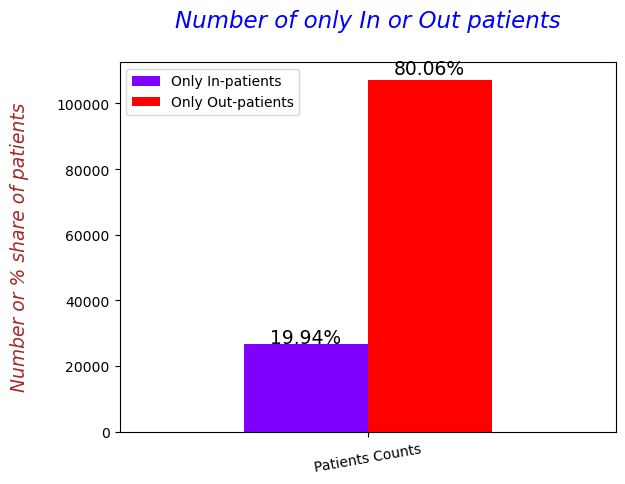

In [179]:
fig = patients_counts.plot(kind='bar',colormap='rainbow')
for p in fig.patches:
    width = p.get_width()
    height = p.get_height()
    x, y = p.get_xy()
    fig.annotate(f'{str(round((height*100)/tot_patients,2))+"%"}', (x + width/2, y + height*1.015), ha='center', fontsize=13.5)
plt.xticks(labels=["Patients Counts"], ticks=[0], rotation=10)
plt.ylabel("Number or % share of patients\n", fontdict=label_font_dict)
plt.title("Number of only In or Out patients\n", fontdict=title_font_dict)
plt.show()

**`OBSERVATION`**
* From the above plot, we can decude that 80% of the patients gets medicared without even admission.

# ***Exploring the In-patients Data***

In [180]:
ip_train_df

,BeneID,ClaimID,ClaimStartDt,ClaimEndDt,Provider,InscClaimAmtReimbursed,AttendingPhysician,OperatingPhysician,OtherPhysician,AdmissionDt,ClmAdmitDiagnosisCode,DeductibleAmtPaid,DischargeDt,DiagnosisGroupCode,ClmDiagnosisCode_1,ClmDiagnosisCode_2,ClmDiagnosisCode_3,ClmDiagnosisCode_4,ClmDiagnosisCode_5,ClmDiagnosisCode_6,ClmDiagnosisCode_7,ClmDiagnosisCode_8,ClmDiagnosisCode_9,ClmDiagnosisCode_10,ClmProcedureCode_1,ClmProcedureCode_2,ClmProcedureCode_3,ClmProcedureCode_4,ClmProcedureCode_5,ClmProcedureCode_6
0,BENE11001,CLM46614,2009-04-12,2009-04-18,PRV55912,26000,PHY390922,NaN,NaN,2009-04-12,7866,1068.0,2009-04-18,201,1970,4019,5853,7843,2768,71590,2724,19889,5849,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,BENE11001,CLM66048,2009-08-31,2009-09-02,PRV55907,5000,PHY318495,PHY318495,NaN,2009-08-31,6186,1068.0,2009-09-02,750,6186,2948,56400,NaN,NaN,NaN,NaN,NaN,NaN,NaN,7092.0,NaN,NaN,NaN,NaN,NaN
2,BENE11001,CLM68358,2009-09-17,2009-09-20,PRV56046,5000,PHY372395,NaN,PHY324689,2009-09-17,29590,1068.0,2009-09-20,883,29623,30390,71690,34590,V1581,32723,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,BENE11011,CLM38412,2009-02-14,2009-02-22,PRV52405,5000,PHY369659,PHY392961,PHY349768,2009-02-14,431,1068.0,2009-02-22,067,43491,2762,7843,32723,V1041,4254,25062,40390,4019,NaN,331.0,NaN,NaN,NaN,NaN,NaN
4,BENE11014,CLM63689,2009-08-13,2009-08-30,PRV56614,10000,PHY379376,PHY398258,NaN,2009-08-13,78321,1068.0,2009-08-30,975,042,3051,34400,5856,42732,486,5119,29620,20300,NaN,3893.0,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
40469,BENE159167,CLM69886,2009-09-28,2009-10-02,PRV53671,7000,PHY345332,PHY319565,NaN,2009-09-28,2859,1068.0,2009-10-02,812,2851,2762,53550,V0254,V1005,5173,79092,70704,2869,4148,9904.0,NaN,NaN,NaN,NaN,NaN
40470,BENE159175,CLM74504,2009-11-03,2009-11-06,PRV54981,4000,PHY342806,PHY365497,NaN,2009-11-03,79902,1068.0,2009-11-06,228,42823,4148,4019,3970,4241,V1042,49122,4254,5990,NaN,8605.0,NaN,NaN,NaN,NaN,NaN
40471,BENE159177,CLM76485,2009-11-18,2009-11-22,PRV56588,3000,PHY423220,PHY332752,NaN,2009-11-18,78605,1068.0,2009-11-22,302,4280,3963,5859,4019,40390,4111,71534,71590,V4502,NaN,9390.0,NaN,NaN,NaN,NaN,NaN
40472,BENE159177,CLM79949,2009-12-17,2009-12-18,PRV56575,5000,PHY353156,NaN,NaN,2009-12-17,7802,1068.0,2009-12-18,309,7802,5859,496,2809,V1254,42822,4263,0414,41400,NaN,NaN,NaN,NaN,NaN,NaN,NaN


- **NULL records in the in-patients data**

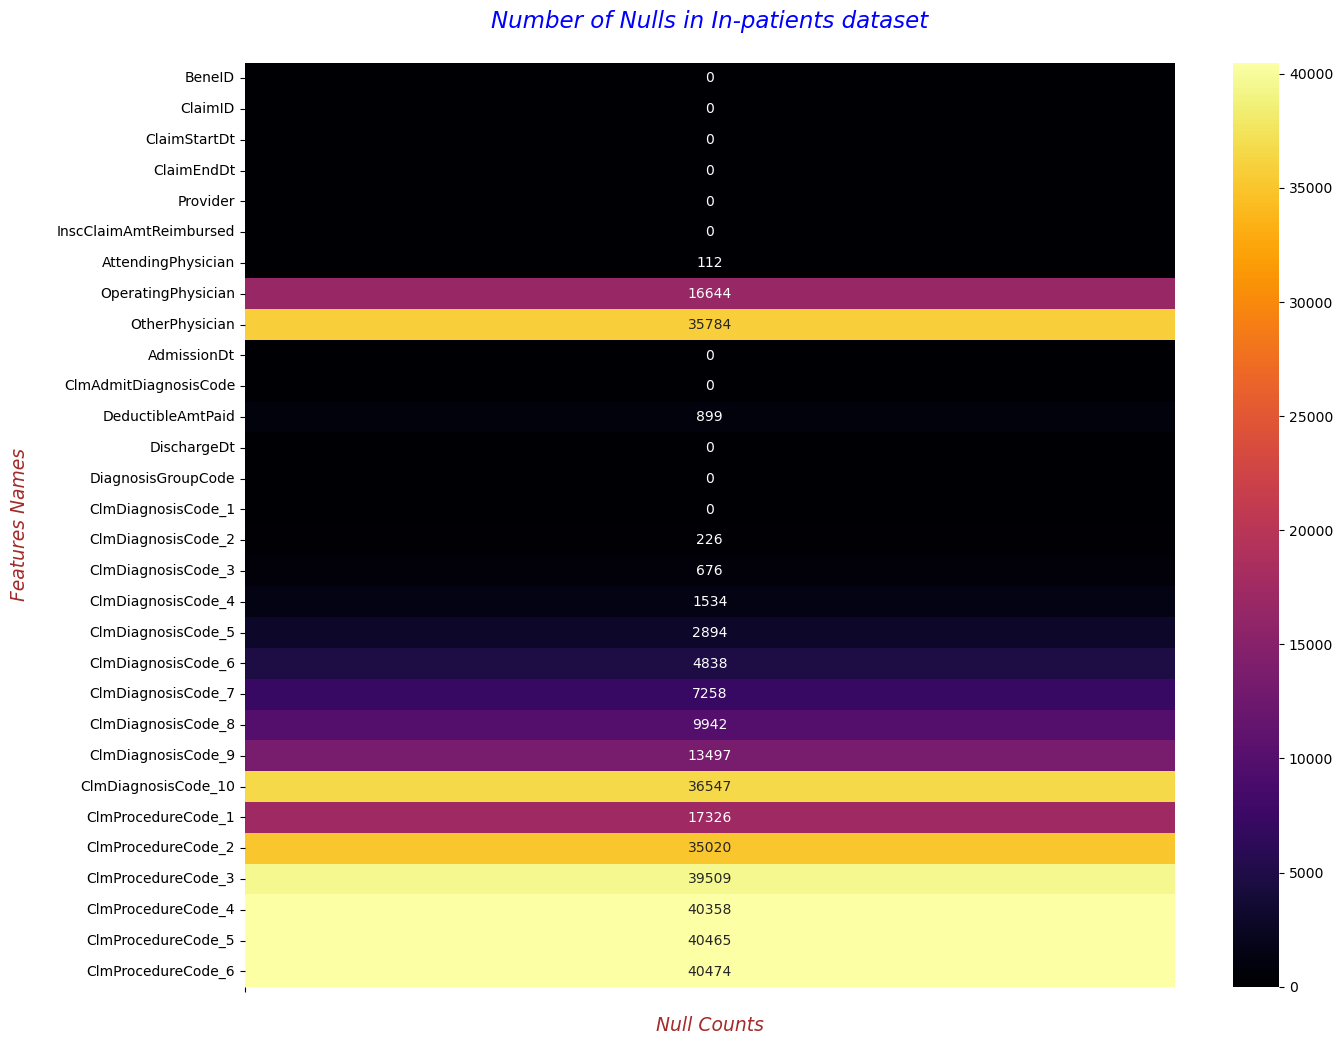

In [181]:
plt.figure(figsize=(15,12))
fig = sns.heatmap(pd.DataFrame(ip_train_df.isnull().sum()), annot=True, fmt=".7g", cmap='inferno', cbar=True)
plt.xticks(labels=[" "], ticks=[0])
plt.xlabel("Null Counts", fontdict=label_font_dict)
plt.ylabel("Features Names\n", fontdict=label_font_dict)
plt.title("Number of Nulls in In-patients dataset\n", fontdict=title_font_dict)
plt.show()

**`OBSERVATION`**
* From the above plot, we can see that the majority of the ProcedureCodes are having NULLS. And, ClmDiagnosisCode_10 is very rare among Patients.

- **Added Flag for indicating whether beneficiary admitted or not?**

In [182]:
ip_train_df["Admitted?"] = 1

- **Added Claim_Clearance_Days**

In [183]:
ip_train_df['ClaimStartDt'] = pd.to_datetime(ip_train_df['ClaimStartDt'], format="%Y-%m-%d")
ip_train_df['ClaimEndDt'] = pd.to_datetime(ip_train_df['ClaimEndDt'], format="%Y-%m-%d")

In [184]:
ip_train_df['Claim_Duration'] = (ip_train_df['ClaimEndDt'] - ip_train_df['ClaimStartDt']).dt.days

In [185]:
ip_train_df['Claim_Duration'].describe()

count    40474.000000
mean         5.660251
std          5.628873
min          0.000000
25%          2.000000
50%          4.000000
75%          7.000000
max         36.000000
Name: Claim_Duration, dtype: float64

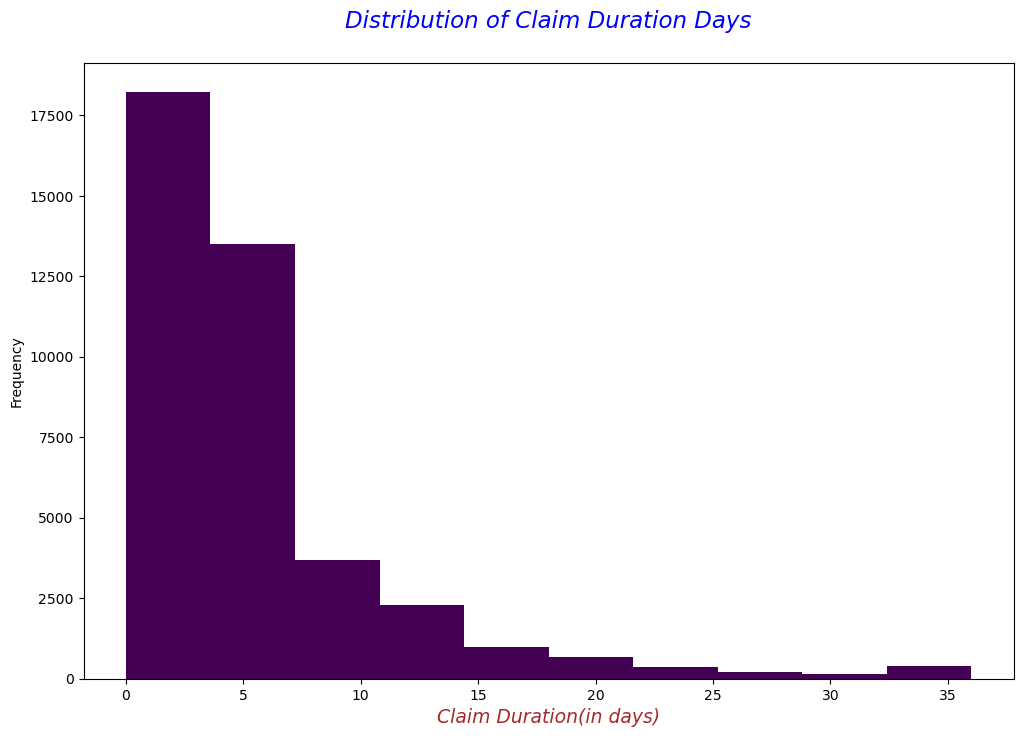

In [186]:
plt.figure(figsize=(12,8))
ip_train_df['Claim_Duration'].plot(kind='hist', colormap="viridis");
plt.xlabel("Claim Duration(in days)", fontdict=label_font_dict)
plt.title("Distribution of Claim Duration Days\n", fontdict=title_font_dict)
plt.show()

**`OBSERVATION`**
* From the above plot, we can decude that the majority of the claims filed for less than 7 days.


- **Percentiles values**

In [187]:
for val in [0.1,0.2,0.25,0.3,0.4,0.5,0.6,0.7,0.75,0.8,0.9,0.91,0.92,0.93,0.94,0.95,0.96,0.97,0.98,0.99,0.999,0.9999,0.99999,0.999999,1.0]:
    percentile = round(float(val*100),6)
    percentile_val = round(ip_train_df["Claim_Duration"].quantile(val),1)
    print("Percentile --> {} and its value is --> {}".format(percentile,percentile_val))

Percentile --> 10.0 and its value is --> 1.0
Percentile --> 20.0 and its value is --> 2.0
Percentile --> 25.0 and its value is --> 2.0
Percentile --> 30.0 and its value is --> 3.0
Percentile --> 40.0 and its value is --> 3.0
Percentile --> 50.0 and its value is --> 4.0
Percentile --> 60.0 and its value is --> 5.0
Percentile --> 70.0 and its value is --> 6.0
Percentile --> 75.0 and its value is --> 7.0
Percentile --> 80.0 and its value is --> 8.0
Percentile --> 90.0 and its value is --> 12.0
Percentile --> 91.0 and its value is --> 13.0
Percentile --> 92.0 and its value is --> 14.0
Percentile --> 93.0 and its value is --> 14.0
Percentile --> 94.0 and its value is --> 15.0
Percentile --> 95.0 and its value is --> 17.0
Percentile --> 96.0 and its value is --> 18.0
Percentile --> 97.0 and its value is --> 21.0
Percentile --> 98.0 and its value is --> 25.0
Percentile --> 99.0 and its value is --> 32.0
Percentile --> 99.9 and its value is --> 35.0
Percentile --> 99.99 and its value is --> 35

**`OBSERVATION`**
* From the results, we can say that 95% of the claims are filed for 17 days.

### **Q1. What is the relationship b/w Amount of Insurance Claim Reimbursed v/s Claim Clearance Days?**

In [188]:
unq_claim_duration_days = ip_train_df['Claim_Duration'].unique()
unq_claim_duration_days

array([ 6,  2,  3,  8, 17,  5,  4,  7,  1, 11, 35,  9, 15, 12, 24, 23, 14,
        0, 10, 13, 18, 19, 28, 16, 21, 26, 22, 32, 27, 20, 31, 25, 34, 30,
       29, 33, 36], dtype=int64)

In [189]:
tot_claims_filed_for_specific_days = pd.DataFrame(ip_train_df.groupby(['Claim_Duration'])['BeneID'].count())
tot_claims_filed_for_specific_days

,BeneID
Claim_Duration,
0,605
1,4599
2,6119
3,6899
4,4993
5,3579
6,2714
7,2210
8,1612


In [190]:
tot_insc_amount_for_claim_durations = pd.DataFrame(ip_train_df.groupby(['Claim_Duration'])['InscClaimAmtReimbursed'].sum())
tot_insc_amount_for_claim_durations

,InscClaimAmtReimbursed
Claim_Duration,
0,3925000
1,33356000
2,43987610
3,56477460
4,43932690
5,33962440
6,29057610
7,25537200
8,20637600


In [191]:
claim_clearance_amts = pd.merge(left=tot_claims_filed_for_specific_days, right=tot_insc_amount_for_claim_durations,
                                how='inner',
                                left_on=tot_claims_filed_for_specific_days.index,
                                right_on=tot_insc_amount_for_claim_durations.index)

claim_clearance_amts.head()

,key_0,BeneID,InscClaimAmtReimbursed
0,0,605,3925000
1,1,4599,33356000
2,2,6119,43987610
3,3,6899,56477460
4,4,4993,43932690


In [192]:
claim_clearance_amts.columns = ['Claim_durations_in_days', 'Total_claims', 'All_Claims_Total_Amount']
claim_clearance_amts.head()

,Claim_durations_in_days,Total_claims,All_Claims_Total_Amount
0,0,605,3925000
1,1,4599,33356000
2,2,6119,43987610
3,3,6899,56477460
4,4,4993,43932690


In [193]:
claim_clearance_amts['Avg_Claim_Insc_Amount'] = np.round(claim_clearance_amts['All_Claims_Total_Amount']/claim_clearance_amts['Total_claims'],2)

In [194]:
claim_clearance_amts.head()

,Claim_durations_in_days,Total_claims,All_Claims_Total_Amount,Avg_Claim_Insc_Amount
0,0,605,3925000,6487.60
1,1,4599,33356000,7252.88
2,2,6119,43987610,7188.69
3,3,6899,56477460,8186.33
4,4,4993,43932690,8798.86


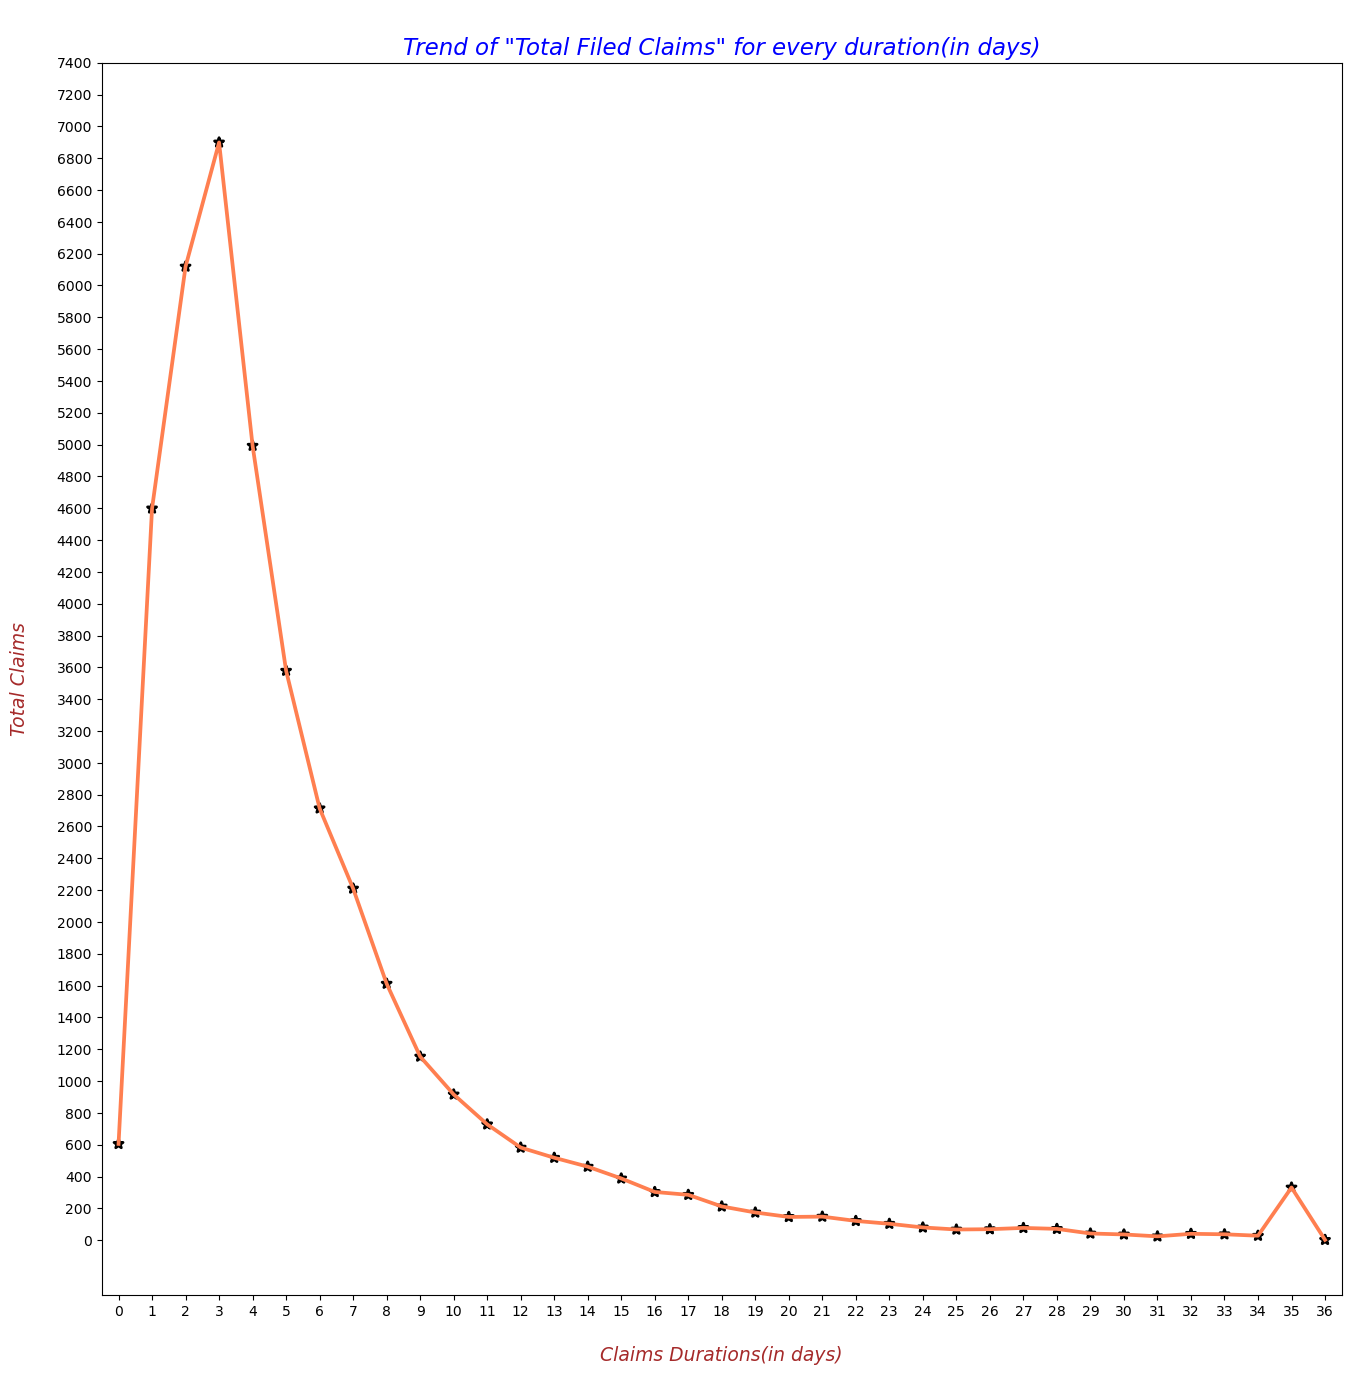

In [195]:
plt.figure(figsize=(16,16))
sns.pointplot(data=claim_clearance_amts, x='Claim_durations_in_days', y='Total_claims', 
              color='k', markers="*", linestyles="")
sns.pointplot(data=claim_clearance_amts, x='Claim_durations_in_days', y='Total_claims', 
              color='coral', markers="", linestyles="-")


plt.xticks(rotation=0)
plt.xlabel("\nClaims Durations(in days)", fontdict= label_font_dict)
plt.ylabel("Total Claims\n", fontdict= label_font_dict)
plt.yticks(np.arange(0,7500,200))
plt.title('\nTrend of "Total Filed Claims" for every duration(in days)', fontdict=title_font_dict)
plt.show()

**`OBSERVATION`**
* The above graph tells us that the most number of claims are filed for 3 days. And, there are very less number of claims for duration greater than 15.
    * However, we can witness a litter spike for 35 days of duration for claims.

* And, there are around 600 claims for which the duration is 0 that means Claim Start Date and End Date is same.

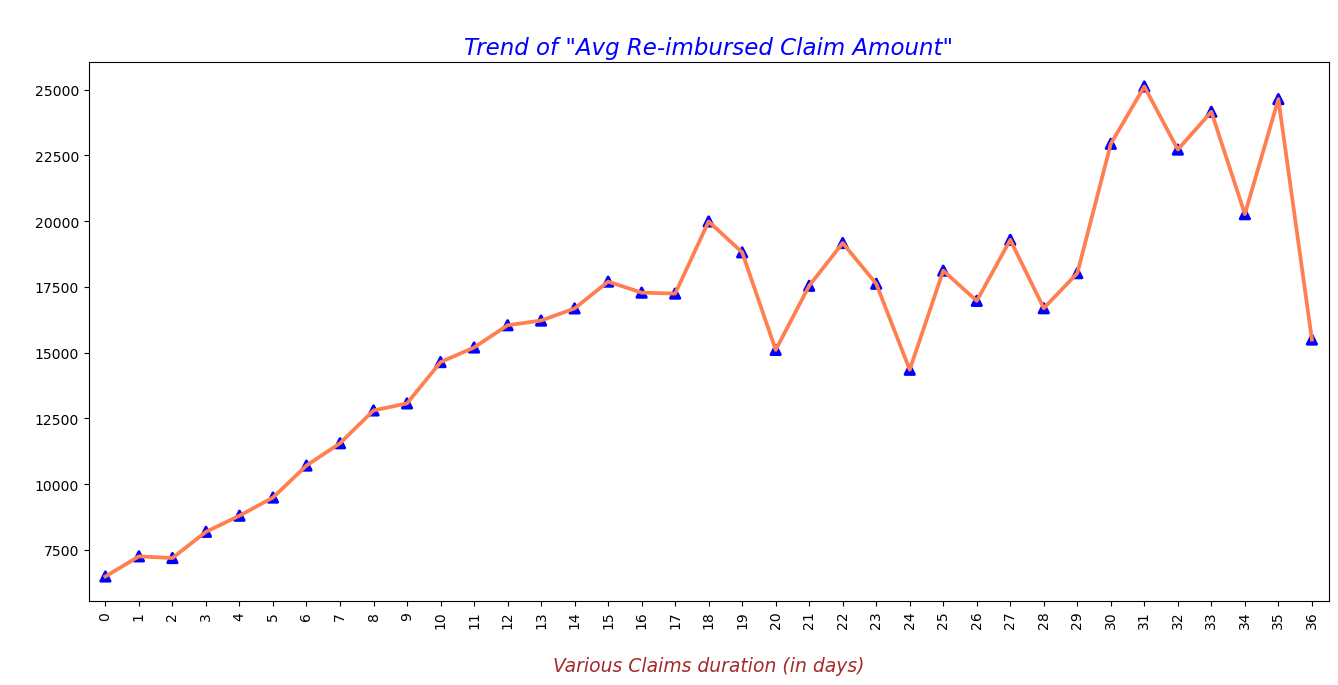

In [196]:
plt.figure(figsize=(16,7))
sns.pointplot(data=claim_clearance_amts, x='Claim_durations_in_days', y='Avg_Claim_Insc_Amount', 
              color='blue', markers="^", linestyles="")
sns.pointplot(data=claim_clearance_amts, x='Claim_durations_in_days', y='Avg_Claim_Insc_Amount', 
              color='coral', markers="", linestyles="-")
plt.xticks(rotation=90)
plt.xlabel("\nVarious Claims duration (in days)", fontdict= label_font_dict)
plt.ylabel(" ", fontdict= label_font_dict)
plt.title('\nTrend of "Avg Re-imbursed Claim Amount"', fontdict=title_font_dict)
plt.show()

**`OBSERVATION`**
* The above graph tells us that as the claim duration increases then the Avg Re-imbursed Amount also increases, however, as we have already seen that total number of claims are very less when duration is greater than 15 days.

* Another thing to look here is that if the duration is b/w [30-35] then the Average Re-imbursed amount is very high and reaches its maximum.

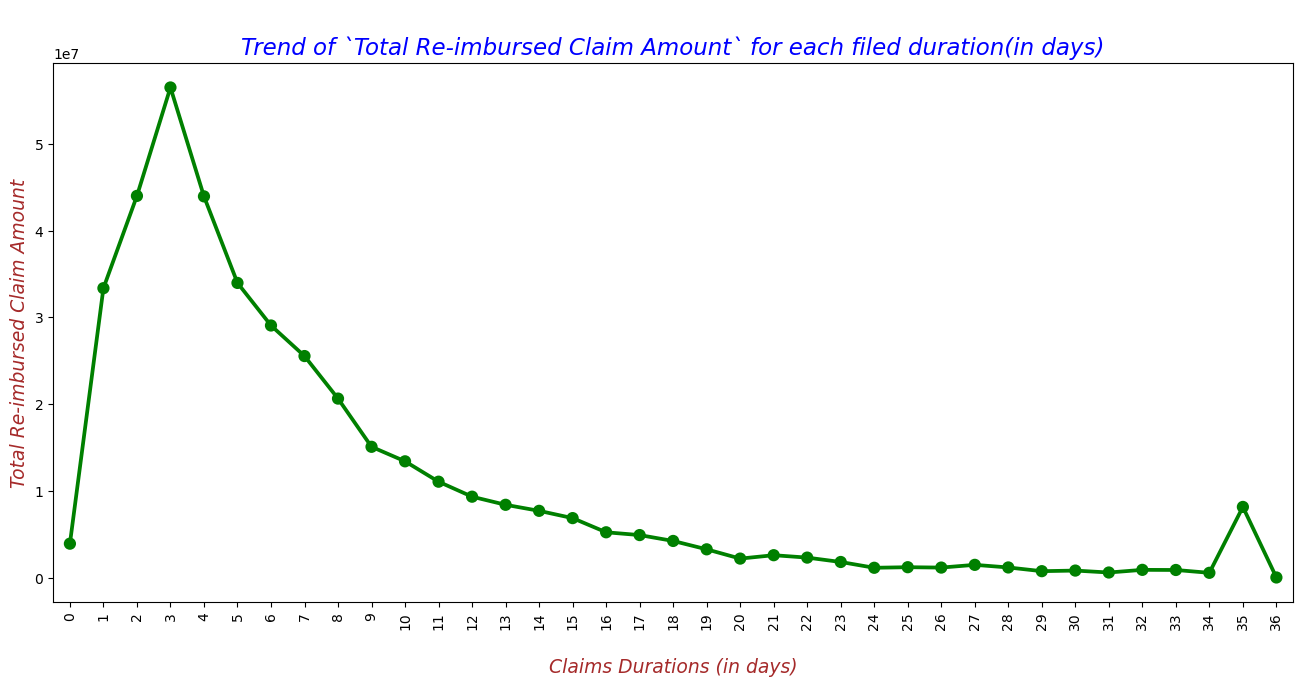

In [197]:
plt.figure(figsize=(16,7))
sns.pointplot(data=claim_clearance_amts, x='Claim_durations_in_days', y='All_Claims_Total_Amount', color='green')
plt.xticks(rotation=90)
plt.xlabel("\nClaims Durations (in days)", fontdict= label_font_dict)
plt.ylabel("Total Re-imbursed Claim Amount", fontdict= label_font_dict)
plt.title("\nTrend of `Total Re-imbursed Claim Amount` for each filed duration(in days)", fontdict=title_font_dict)
plt.show()

**`OBSERVATION`**
* The above graph tells us that the Total Re-imbursed Amount is the highest for 3 days claims

* And, for claims with durations from 12 to 34 the total re-imbursed amount is very less, however, for 35 days duration we can witness a clear spike that can be a potential sign of fraudulent.

### **Q2. What is the relationship b/w Claimed and Admitted Durations with Re-imbursed Amount?**

In [198]:
ip_train_df['DischargeDt'] = pd.to_datetime(ip_train_df['DischargeDt'], format="%Y-%m-%d")
ip_train_df['AdmissionDt'] = pd.to_datetime(ip_train_df['AdmissionDt'], format="%Y-%m-%d")

In [199]:
ip_train_df['Admitted_Days'] = ip_train_df['DischargeDt'] - ip_train_df['AdmissionDt']
ip_train_df['Admitted_Days'] = ip_train_df['Admitted_Days'].dt.days

In [200]:
claims_with_diff_admitted_and_claimed_dur = ip_train_df[~(ip_train_df['Claim_Duration'] == ip_train_df['Admitted_Days'])]
claims_with_diff_admitted_and_claimed_dur.head()

,BeneID,ClaimID,ClaimStartDt,ClaimEndDt,Provider,InscClaimAmtReimbursed,AttendingPhysician,OperatingPhysician,OtherPhysician,AdmissionDt,ClmAdmitDiagnosisCode,DeductibleAmtPaid,DischargeDt,DiagnosisGroupCode,ClmDiagnosisCode_1,...,ClmDiagnosisCode_5,ClmDiagnosisCode_6,ClmDiagnosisCode_7,ClmDiagnosisCode_8,ClmDiagnosisCode_9,ClmDiagnosisCode_10,ClmProcedureCode_1,ClmProcedureCode_2,ClmProcedureCode_3,ClmProcedureCode_4,ClmProcedureCode_5,ClmProcedureCode_6,Admitted?,Claim_Duration,Admitted_Days
35,BENE11093,CLM82202,2009-01-03,2009-01-12,PRV51842,20000,PHY341192,PHY355416,NaN,2009-01-03,4439,1068.0,2009-01-09,255,99662,...,V854,4280,E9320,04185,412,42732,3950.0,2762.0,NaN,NaN,NaN,NaN,1,9,6
2163,BENE18587,CLM37486,2009-02-10,2009-02-11,PRV52020,3000,PHY359519,NaN,NaN,2009-02-08,2859,1068.0,2009-02-11,804,2859,...,4168,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,1,3
3864,BENE24807,CLM82212,2008-12-31,2009-01-11,PRV54111,13000,PHY360669,PHY408812,NaN,2008-12-31,55221,1068.0,2009-01-09,345,56889,...,42731,9974,4589,27801,25000,NaN,5369.0,NaN,NaN,NaN,NaN,NaN,1,11,9
4422,BENE26849,CLM70032,2009-10-02,2009-10-07,PRV56647,12000,PHY332134,NaN,NaN,2009-09-29,2930,1068.0,2009-10-07,867,0389,...,42820,486,25000,4589,42833,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,5,8
5400,BENE30503,CLM67400,2009-09-12,2009-09-14,PRV54228,3000,PHY364179,NaN,NaN,2009-09-09,5789,1068.0,2009-09-14,376,56211,...,4019,3004,41401,5771,2724,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,2,5


In [201]:
claims_with_diff_admitted_and_claimed_dur['InscClaimAmtReimbursed'].sum()

671400

**`OBSERVATION`**
* The above table tells us that there are 49 claims whose Claimed Duration and Admitted Duration are different.

* And, for these 49 claims the total re-imbursed amount is around 0.67 Million. So, doesn't look like an issue here as the admitted days can be greater than claimed duration based upon the plan bought by the beneficiary.

* **Lets check whether claimed duration is greater then admitted duration**

In [202]:
claims_with_diff_admitted_and_claimed_dur[claims_with_diff_admitted_and_claimed_dur['Claim_Duration']  > 
                                          claims_with_diff_admitted_and_claimed_dur['Admitted_Days']]

,BeneID,ClaimID,ClaimStartDt,ClaimEndDt,Provider,InscClaimAmtReimbursed,AttendingPhysician,OperatingPhysician,OtherPhysician,AdmissionDt,ClmAdmitDiagnosisCode,DeductibleAmtPaid,DischargeDt,DiagnosisGroupCode,ClmDiagnosisCode_1,...,ClmDiagnosisCode_5,ClmDiagnosisCode_6,ClmDiagnosisCode_7,ClmDiagnosisCode_8,ClmDiagnosisCode_9,ClmDiagnosisCode_10,ClmProcedureCode_1,ClmProcedureCode_2,ClmProcedureCode_3,ClmProcedureCode_4,ClmProcedureCode_5,ClmProcedureCode_6,Admitted?,Claim_Duration,Admitted_Days
35,BENE11093,CLM82202,2009-01-03,2009-01-12,PRV51842,20000,PHY341192,PHY355416,NaN,2009-01-03,4439,1068.0,2009-01-09,255,99662,...,V854,4280,E9320,04185,412,42732,3950.0,2762.0,NaN,NaN,NaN,NaN,1,9,6
3864,BENE24807,CLM82212,2008-12-31,2009-01-11,PRV54111,13000,PHY360669,PHY408812,NaN,2008-12-31,55221,1068.0,2009-01-09,345,56889,...,42731,9974,4589,27801,25000,NaN,5369.0,NaN,NaN,NaN,NaN,NaN,1,11,9
7752,BENE39346,CLM82211,2009-02-18,2009-02-26,PRV54065,19000,PHY337531,PHY341176,NaN,2009-02-18,44421,1068.0,2009-02-23,254,4422,...,44021,V1582,2724,25040,4439,27801,3712.0,NaN,NaN,NaN,NaN,NaN,1,8,5
9094,BENE44545,CLM82209,2009-01-18,2009-01-27,PRV52843,14000,PHY365072,NaN,NaN,2009-01-18,85181,1068.0,2009-01-25,023,85202,...,2449,3485,78720,5070,5990,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,9,7
9974,BENE47786,CLM82208,2009-05-27,2009-06-04,PRV52828,14000,PHY391167,NaN,NaN,2009-05-27,486,1068.0,2009-06-01,166,486,...,V140,27652,53081,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,8,5
17060,BENE73681,CLM82213,2009-02-10,2009-02-21,PRV54354,11000,PHY397703,NaN,PHY390453,2009-02-10,78079,1068.0,2009-02-18,315,41071,...,5849,42831,5853,28860,V4502,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,11,8
18267,BENE78133,CLM82210,2009-01-02,2009-01-05,PRV53461,20000,PHY331754,PHY426843,NaN,2009-01-02,72981,1068.0,2009-01-03,228,44422,...,NaN,NaN,NaN,NaN,NaN,NaN,387.0,NaN,NaN,NaN,NaN,NaN,1,3,1
21298,BENE88968,CLM82205,2009-02-23,2009-02-28,PRV52045,24000,PHY339550,PHY359571,NaN,2009-02-23,78650,1068.0,2009-02-25,304,V5332,...,42741,V8536,4271,4148,4275,NaN,54.0,NaN,NaN,NaN,NaN,NaN,1,5,2
26395,BENE107828,CLM82216,2009-01-01,2009-01-22,PRV55018,19000,PHY364322,PHY320450,NaN,2009-01-01,78900,1068.0,2009-01-19,439,5758,...,41071,496,5990,5856,2720,486,5123.0,7850.0,NaN,NaN,NaN,NaN,1,21,18
27053,BENE110116,CLM82217,2009-02-09,2009-03-17,PRV56268,20000,PHY400645,PHY408610,NaN,2009-02-09,25010,1068.0,2009-03-16,642,25080,...,42789,42731,56881,5184,73007,NaN,3950.0,NaN,NaN,NaN,NaN,NaN,1,36,35


In [203]:
claims_with_diff_admitted_and_claimed_dur[claims_with_diff_admitted_and_claimed_dur['Claim_Duration']  > \
                                          claims_with_diff_admitted_and_claimed_dur['Admitted_Days']]['InscClaimAmtReimbursed'].sum()

274000

**`OBSERVATION`**
* The above table tells us that 17 claims out of 49 have Claimed Duration greater than the Admitted Duration.

* And, for these 17 claims the total re-imbursed amount is around 0.27 Million. For now, I'll keep this feature but my initial look says that it won't be much of a use.

### **Q3. What is the relationship b/w DeductibleAmtPaid and Re-imbursed Amount?**

In [204]:
no_of_claim_with_no_copay = ip_train_df[ip_train_df['DeductibleAmtPaid'].isna()].shape[0]
no_of_claim_with_no_copay

899

In [205]:
no_of_claim_with_copay = ip_train_df[~ip_train_df['DeductibleAmtPaid'].isna()].shape[0]
no_of_claim_with_copay

39575

In [206]:
percent_of_no_copay_claims = round((no_of_claim_with_no_copay / (no_of_claim_with_copay + no_of_claim_with_no_copay)) * 100,1)
print("Percentage of claims with no co-payment or deductible : {}% ".format(percent_of_no_copay_claims))

Percentage of claims with no co-payment or deductible : 2.2% 


In [207]:
re_imbursed_amt_for_no_copay = ip_train_df[ip_train_df['DeductibleAmtPaid'].isna()]['InscClaimAmtReimbursed'].sum()
re_imbursed_amt_for_no_copay

10690000

In [208]:
re_imbursed_amt_with_some_copay = ip_train_df[~ip_train_df['DeductibleAmtPaid'].isna()]['InscClaimAmtReimbursed'].sum()
re_imbursed_amt_with_some_copay

397607020

In [209]:
tot_sum_of_claims_with_copay = re_imbursed_amt_with_some_copay / (re_imbursed_amt_with_some_copay + re_imbursed_amt_for_no_copay)
tot_sum_of_claims_with_no_copay = re_imbursed_amt_for_no_copay / (re_imbursed_amt_with_some_copay + re_imbursed_amt_for_no_copay)

In [210]:
percent_of_tot_sum_no_copay_claims_amt = round(tot_sum_of_claims_with_no_copay * 100,1)
print("Percentage of Total Re-imbursed Amount for claims with no co-payment or deductible: {}% ".\
      format(percent_of_tot_sum_no_copay_claims_amt))

Percentage of Total Re-imbursed Amount for claims with no co-payment or deductible: 2.6% 


**`OBSERVATION`**
* The above table tells us that there are a 2% of total claims for which there is no co-payment.
    * And, for these 2% (or 899) of total claims the total re-imbursed amount is 10.6 Million that is 2.6% of the total re-imbursed amount.

In [211]:
# Here, updating the NULL values of DeductibleAmtPaid feature as 0
ip_train_df['DeductibleAmtPaid'].fillna(value=0.0, inplace=True)

### **Q4. What is the relationship of Providers with Total number of claims filed & Re-imbursed Amount?**

In [212]:
# How many unique providers are there in the dataset?
print("We have {} unique number of Providers in the in-patient dataset.".format(ip_train_df['Provider'].nunique()))

We have 2092 unique number of Providers in the in-patient dataset.


In [213]:
provider_tot_claims_filed = pd.DataFrame(ip_train_df.groupby(['Provider'])['ClaimID'].count())
provider_tot_reimbursed_amt = pd.DataFrame(ip_train_df.groupby(['Provider'])['InscClaimAmtReimbursed'].sum())

prv_tot_filed_claims_and_tot_reimb_amt = pd.merge(left=provider_tot_claims_filed, right=provider_tot_reimbursed_amt, how='inner',
                                                  left_on=provider_tot_claims_filed.index, right_on=provider_tot_reimbursed_amt.index)

prv_tot_filed_claims_and_tot_reimb_amt.columns = ['ProviderID', 'Tot_Claims_Filed', 'Tot_Re_Imbursed_Amt']
prv_tot_filed_claims_and_tot_reimb_amt.reset_index(drop=True,inplace=True)
prv_tot_filed_claims_and_tot_reimb_amt['Percentage_out_of_tot_reimb_amt'] = round((prv_tot_filed_claims_and_tot_reimb_amt['Tot_Re_Imbursed_Amt'] / ip_train_df['InscClaimAmtReimbursed'].sum()) * 100, 3)

provider_max_reimbursed_amt = pd.DataFrame(ip_train_df.groupby(['Provider'])['InscClaimAmtReimbursed'].max())
provider_max_reimbursed_amt.rename(columns={"InscClaimAmtReimbursed": "Max_Re_Imbursed_Amt"}, inplace=True)

prv_tot_filed_claims_tot_max_reimb_amt = pd.merge(left=prv_tot_filed_claims_and_tot_reimb_amt, 
                                                  right=provider_max_reimbursed_amt, how='inner',
                                                  left_on=prv_tot_filed_claims_and_tot_reimb_amt['ProviderID'], 
                                                  right_on=provider_max_reimbursed_amt.index)

prv_tot_filed_claims_tot_max_reimb_amt.drop(['key_0'], axis=1, inplace=True)
prv_tot_filed_claims_tot_max_reimb_amt['Diff_in_Tot_and_Max'] = prv_tot_filed_claims_tot_max_reimb_amt['Tot_Re_Imbursed_Amt'] - \
prv_tot_filed_claims_tot_max_reimb_amt['Max_Re_Imbursed_Amt']

prv_tot_filed_claims_tot_max_reimb_amt.head()

,ProviderID,Tot_Claims_Filed,Tot_Re_Imbursed_Amt,Percentage_out_of_tot_reimb_amt,Max_Re_Imbursed_Amt,Diff_in_Tot_and_Max
0,PRV51001,5,97000,0.024,42000,55000
1,PRV51003,62,573000,0.140,57000,516000
2,PRV51007,3,19000,0.005,10000,9000
3,PRV51008,2,25000,0.006,21000,4000
4,PRV51011,1,5000,0.001,5000,0


In [214]:
prv_tot_filed_claims_tot_max_reimb_amt.sort_values(by=['Diff_in_Tot_and_Max','Max_Re_Imbursed_Amt','Percentage_out_of_tot_reimb_amt'],
                                                   axis=0, inplace=True,
                                                   ascending=[True, False, False])

In [215]:
prv_tot_filed_claims_tot_max_reimb_amt.head(60)

,ProviderID,Tot_Claims_Filed,Tot_Re_Imbursed_Amt,Percentage_out_of_tot_reimb_amt,Max_Re_Imbursed_Amt,Diff_in_Tot_and_Max
574,PRV52518,1,57000,0.014,57000,0
578,PRV52537,1,57000,0.014,57000,0
1767,PRV56664,1,57000,0.014,57000,0
1883,PRV57080,1,57000,0.014,57000,0
2012,PRV57399,1,57000,0.014,57000,0
1970,PRV57290,2,55000,0.013,55000,0
305,PRV51681,1,51000,0.012,51000,0
637,PRV52804,1,36000,0.009,36000,0
286,PRV51626,1,35000,0.009,35000,0
11,PRV51035,1,29000,0.007,29000,0


**`OBSERVATION`**
* The above table showing us the Provider Ids who only filed 1 or 2 claims and got the entire amount re-imbursed.
    * This, can be a potential sign of fraudulent because many small-small hospitals in rural area who don't have much facilities or equipments made fraud for benefits. 

In [216]:
tot_re_imb_amt_for_prv_with_5orless_claims = prv_tot_filed_claims_tot_max_reimb_amt[prv_tot_filed_claims_tot_max_reimb_amt['Tot_Claims_Filed'] < 5] \
                                            ['Tot_Re_Imbursed_Amt'].sum()

pp_re_imb_amt_for_prv_with_5orless_claims = round((tot_re_imb_amt_for_prv_with_5orless_claims / ip_train_df['InscClaimAmtReimbursed'].sum()) * 100,2)
print("Total Re-imbursed Amount for Providers with less than 5 filed claims is: {} (17 Million). \n\
And, this is {}% of Total Re-imbursed Claim Amount (408 Million).".format(tot_re_imb_amt_for_prv_with_5orless_claims, 
                                                                    pp_re_imb_amt_for_prv_with_5orless_claims))

Total Re-imbursed Amount for Providers with less than 5 filed claims is: 17012550 (17 Million). 
And, this is 4.17% of Total Re-imbursed Claim Amount (408 Million).


# ***Exploring the Out-patients Data***

In [217]:
op_train_df.shape

(517737, 27)

- **NULL records in the in-patients data**

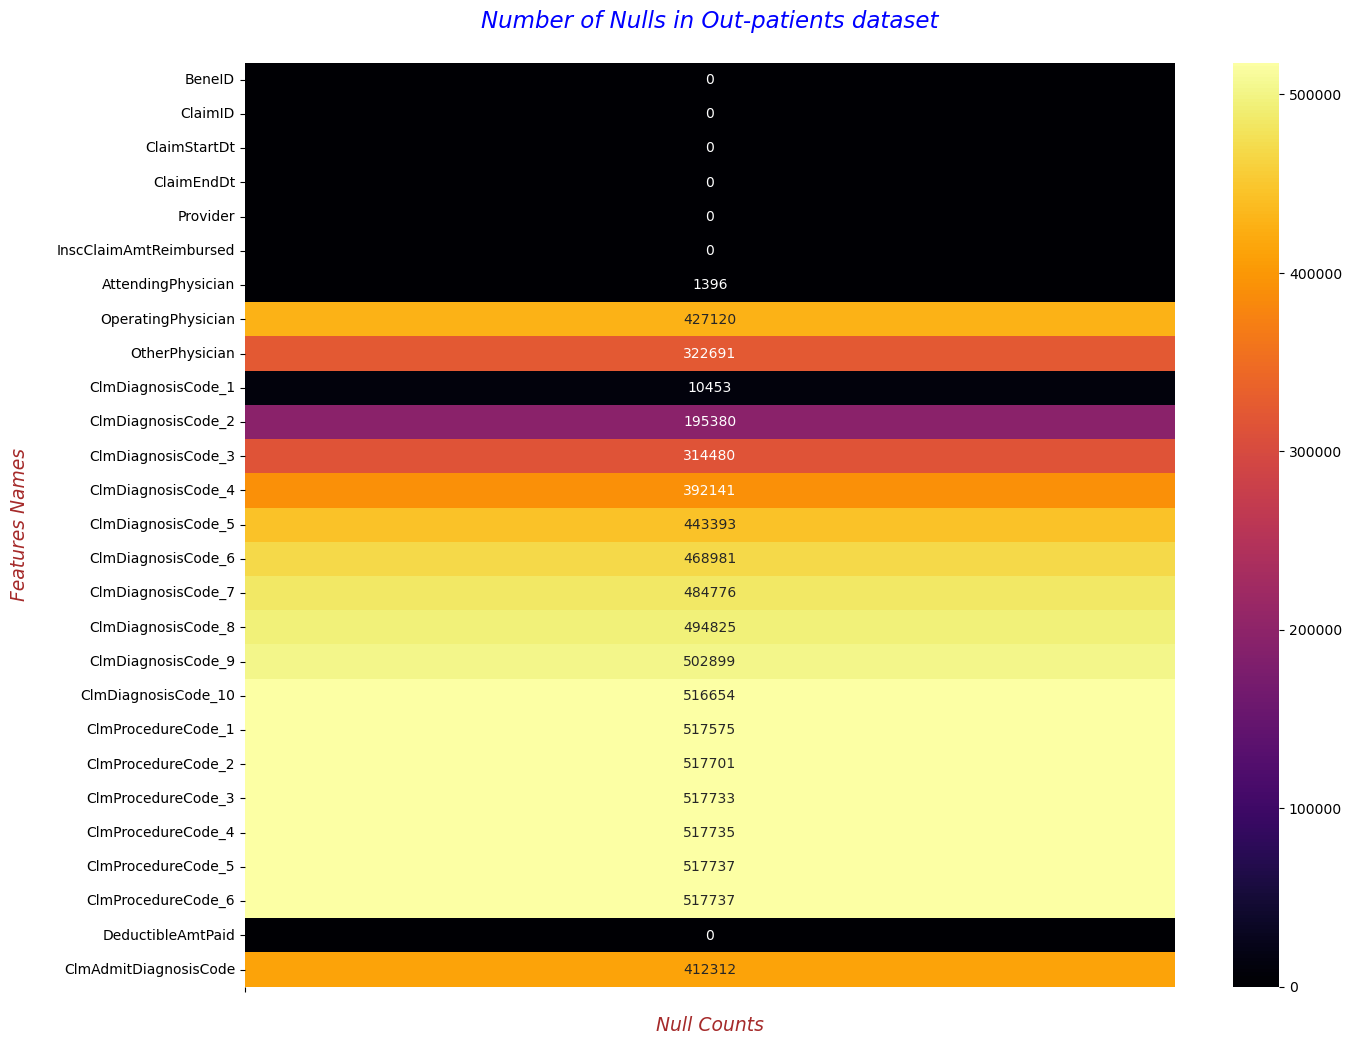

In [218]:
# Here, I'm displaying the number of only out-patients
plt.figure(figsize=(15,12))
fig = sns.heatmap(pd.DataFrame(op_train_df.isnull().sum()), annot=True, fmt=".7g", cmap='inferno', cbar=True)
plt.xticks(labels=[" "], ticks=[0])
plt.xlabel("Null Counts", fontdict=label_font_dict)
plt.ylabel("Features Names\n", fontdict=label_font_dict)
plt.title("Number of Nulls in Out-patients dataset\n", fontdict=title_font_dict)
plt.show()

**`OBSERVATION`**
* From the above plot, we can say that the majority of the ProcedureCodes are having NULLS. 

* ClmDiagnosisCode_9 & ClmDiagnosisCode_10 are very rare among Patients.

- **Added Flag for indicating whether beneficiary admitted or not?**

In [219]:
op_train_df["Admitted?"] = 0

- **Added Claim_Clearance_Days**

In [220]:
op_train_df['ClaimStartDt'] = pd.to_datetime(op_train_df['ClaimStartDt'], format="%Y-%m-%d")
op_train_df['ClaimEndDt'] = pd.to_datetime(op_train_df['ClaimEndDt'], format="%Y-%m-%d")

In [221]:
op_train_df['Claim_Duration'] = (op_train_df['ClaimEndDt'] - op_train_df['ClaimStartDt']).dt.days

In [222]:
op_train_df['Claim_Duration'].describe()

count    517737.000000
mean          1.420532
std           4.707387
min           0.000000
25%           0.000000
50%           0.000000
75%           0.000000
max          23.000000
Name: Claim_Duration, dtype: float64

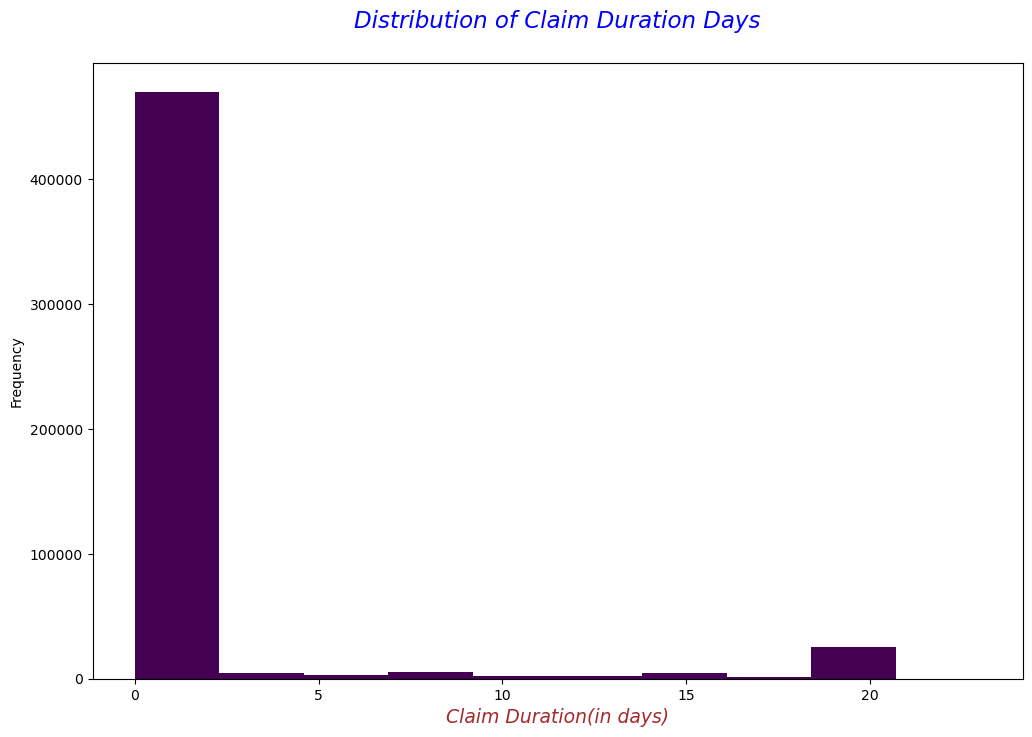

In [223]:
plt.figure(figsize=(12,8))
op_train_df['Claim_Duration'].plot(kind='hist', colormap="viridis");
plt.xlabel("Claim Duration(in days)", fontdict=label_font_dict)
plt.title("Distribution of Claim Duration Days\n", fontdict=title_font_dict)
plt.show();

**`OBSERVATION`**
* From the above plot, we can decude that the majority of the claims filed for less than or equals to 2 days.


- **Percentiles values**

In [224]:
for val in [0.1,0.2,0.25,0.3,0.4,0.5,0.6,0.7,0.75,0.8,0.9,0.91,0.92,0.93,0.94,0.95,0.96,0.97,0.98,0.99,0.999,0.9999,0.99999,0.999999,1.0]:
    percentile = round(float(val*100),6)
    percentile_val = round(op_train_df["Claim_Duration"].quantile(val),1)
    print("Percentile --> {} and its value is --> {}".format(percentile,percentile_val))

Percentile --> 10.0 and its value is --> 0.0
Percentile --> 20.0 and its value is --> 0.0
Percentile --> 25.0 and its value is --> 0.0
Percentile --> 30.0 and its value is --> 0.0
Percentile --> 40.0 and its value is --> 0.0
Percentile --> 50.0 and its value is --> 0.0
Percentile --> 60.0 and its value is --> 0.0
Percentile --> 70.0 and its value is --> 0.0
Percentile --> 75.0 and its value is --> 0.0
Percentile --> 80.0 and its value is --> 0.0
Percentile --> 90.0 and its value is --> 2.0
Percentile --> 91.0 and its value is --> 3.0
Percentile --> 92.0 and its value is --> 6.0
Percentile --> 93.0 and its value is --> 9.0
Percentile --> 94.0 and its value is --> 14.0
Percentile --> 95.0 and its value is --> 17.0
Percentile --> 96.0 and its value is --> 20.0
Percentile --> 97.0 and its value is --> 20.0
Percentile --> 98.0 and its value is --> 20.0
Percentile --> 99.0 and its value is --> 20.0
Percentile --> 99.9 and its value is --> 20.0
Percentile --> 99.99 and its value is --> 20.0
P

**`OBSERVATION`**
* From the results, we can say that 90% of the claims are filed for 2 days.

### **Q5. What is the relationship b/w Claim Duration and Re-imbursed Amount?**

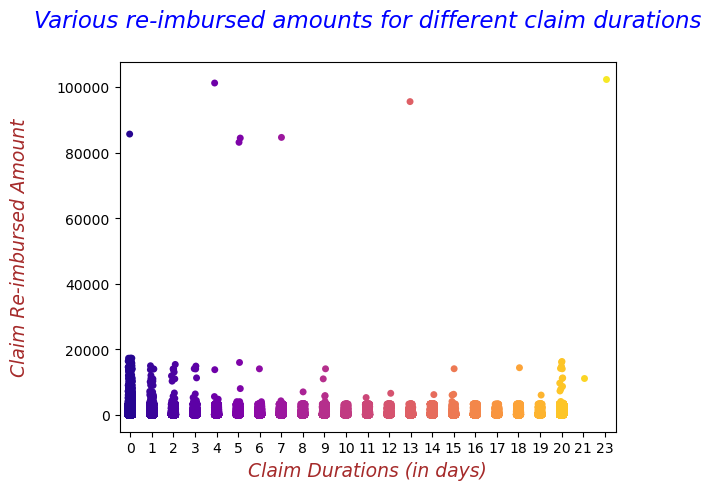

In [225]:
sns.stripplot(x="Claim_Duration", y="InscClaimAmtReimbursed", data=op_train_df, palette="plasma")
plt.xlabel("Claim Durations (in days)", fontdict=label_font_dict)
plt.ylabel("Claim Re-imbursed Amount\n", fontdict=label_font_dict)
plt.title("Various re-imbursed amounts for different claim durations\n", fontdict=title_font_dict)
plt.show()

**`OBSERVATION`**
* From the above plot, we can decude that the majority of the claims filed have re-imbursed amount less than 20,000. And, very few have more than 1,00,000.

In [226]:
for val in [0.1,0.2,0.25,0.3,0.4,0.5,0.6,0.7,0.75,0.8,0.9,0.91,0.92,0.93,0.94,0.95,0.96,0.97,0.98,0.99,0.999,0.9999,0.99999,0.999999,1.0]:
    percentile = round(float(val*100),6)
    percentile_val = round(op_train_df["InscClaimAmtReimbursed"].quantile(val),1)
    print("Percentile --> {} and its value is --> {}".format(percentile,percentile_val))

Percentile --> 10.0 and its value is --> 10.0
Percentile --> 20.0 and its value is --> 30.0
Percentile --> 25.0 and its value is --> 40.0
Percentile --> 30.0 and its value is --> 40.0
Percentile --> 40.0 and its value is --> 60.0
Percentile --> 50.0 and its value is --> 80.0
Percentile --> 60.0 and its value is --> 100.0
Percentile --> 70.0 and its value is --> 200.0
Percentile --> 75.0 and its value is --> 200.0
Percentile --> 80.0 and its value is --> 300.0
Percentile --> 90.0 and its value is --> 700.0
Percentile --> 91.0 and its value is --> 800.0
Percentile --> 92.0 and its value is --> 900.0
Percentile --> 93.0 and its value is --> 1000.0
Percentile --> 94.0 and its value is --> 1200.0
Percentile --> 95.0 and its value is --> 1500.0
Percentile --> 96.0 and its value is --> 1800.0
Percentile --> 97.0 and its value is --> 2100.0
Percentile --> 98.0 and its value is --> 2500.0
Percentile --> 99.0 and its value is --> 3300.0
Percentile --> 99.9 and its value is --> 3500.0
Percentile 

* **99.9% of claims have Re-imbursed amount less than 3500.**

### **Q5.1 What is the relationship b/w Claim Duration and Co-Payment?**

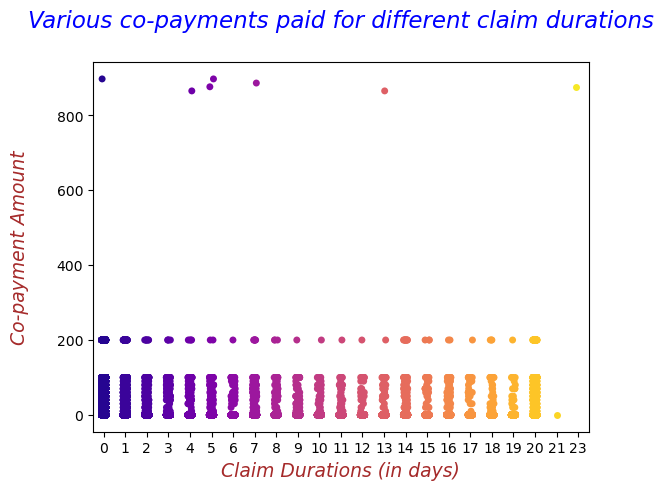

In [227]:
sns.stripplot(x="Claim_Duration", y="DeductibleAmtPaid", data=op_train_df, palette="plasma")
plt.xlabel("Claim Durations (in days)", fontdict=label_font_dict)
plt.ylabel("Co-payment Amount\n", fontdict=label_font_dict)
plt.title("Various co-payments paid for different claim durations\n", fontdict=title_font_dict)
plt.show()

**`OBSERVATION`**
* From the above plot, we can decude that the trend of co-payment is similar across the various durations, however, there are few co-payment which are very high or more than 800.

### **Q6. What is the relationship b/w Amount of Insurance Claim Reimbursed v/s Claim Clearance Days?**

In [228]:
unq_claim_duration_days = op_train_df['Claim_Duration'].unique()
unq_claim_duration_days

array([ 0, 20, 12,  7, 14,  1, 15,  3,  6,  2, 13,  5,  9, 18, 10, 19, 16,
        4,  8, 17, 11, 23, 21], dtype=int64)

In [229]:
op_train_df.columns

Index(['BeneID', 'ClaimID', 'ClaimStartDt', 'ClaimEndDt', 'Provider',
       'InscClaimAmtReimbursed', 'AttendingPhysician', 'OperatingPhysician',
       'OtherPhysician', 'ClmDiagnosisCode_1', 'ClmDiagnosisCode_2',
       'ClmDiagnosisCode_3', 'ClmDiagnosisCode_4', 'ClmDiagnosisCode_5',
       'ClmDiagnosisCode_6', 'ClmDiagnosisCode_7', 'ClmDiagnosisCode_8',
       'ClmDiagnosisCode_9', 'ClmDiagnosisCode_10', 'ClmProcedureCode_1',
       'ClmProcedureCode_2', 'ClmProcedureCode_3', 'ClmProcedureCode_4',
       'ClmProcedureCode_5', 'ClmProcedureCode_6', 'DeductibleAmtPaid',
       'ClmAdmitDiagnosisCode', 'Admitted?', 'Claim_Duration'],
      dtype='object')

In [230]:
tot_claims_filed_for_specific_days = pd.DataFrame(op_train_df.groupby(['Claim_Duration'])['ClaimID'].count())
tot_claims_filed_for_specific_days

,ClaimID
Claim_Duration,
0,453348
1,11960
2,4366
3,2597
4,2238
5,1511
6,1306
7,2564
8,1189


In [231]:
tot_insc_amount_for_claim_durations = pd.DataFrame(op_train_df.groupby(['Claim_Duration'])['InscClaimAmtReimbursed'].sum())
tot_insc_amount_for_claim_durations

,InscClaimAmtReimbursed
Claim_Duration,
0,105624910
1,5381060
2,2227230
3,1272800
4,1270910
5,976870
6,571400
7,1280020
8,463190


In [232]:
claim_clearance_amts = pd.merge(left=tot_claims_filed_for_specific_days, right=tot_insc_amount_for_claim_durations,
                                how='inner',
                                left_on=tot_claims_filed_for_specific_days.index,
                                right_on=tot_insc_amount_for_claim_durations.index)

claim_clearance_amts.columns = ['Claim_durations_in_days', 'Total_claims', 'All_Claims_Total_Amount']
claim_clearance_amts.head()

,Claim_durations_in_days,Total_claims,All_Claims_Total_Amount
0,0,453348,105624910
1,1,11960,5381060
2,2,4366,2227230
3,3,2597,1272800
4,4,2238,1270910


In [233]:
claim_clearance_amts['Avg_Claim_Insc_Amount'] = np.round(claim_clearance_amts['All_Claims_Total_Amount']/claim_clearance_amts['Total_claims'],2)

In [234]:
claim_clearance_amts.head()

,Claim_durations_in_days,Total_claims,All_Claims_Total_Amount,Avg_Claim_Insc_Amount
0,0,453348,105624910,232.99
1,1,11960,5381060,449.92
2,2,4366,2227230,510.13
3,3,2597,1272800,490.10
4,4,2238,1270910,567.88


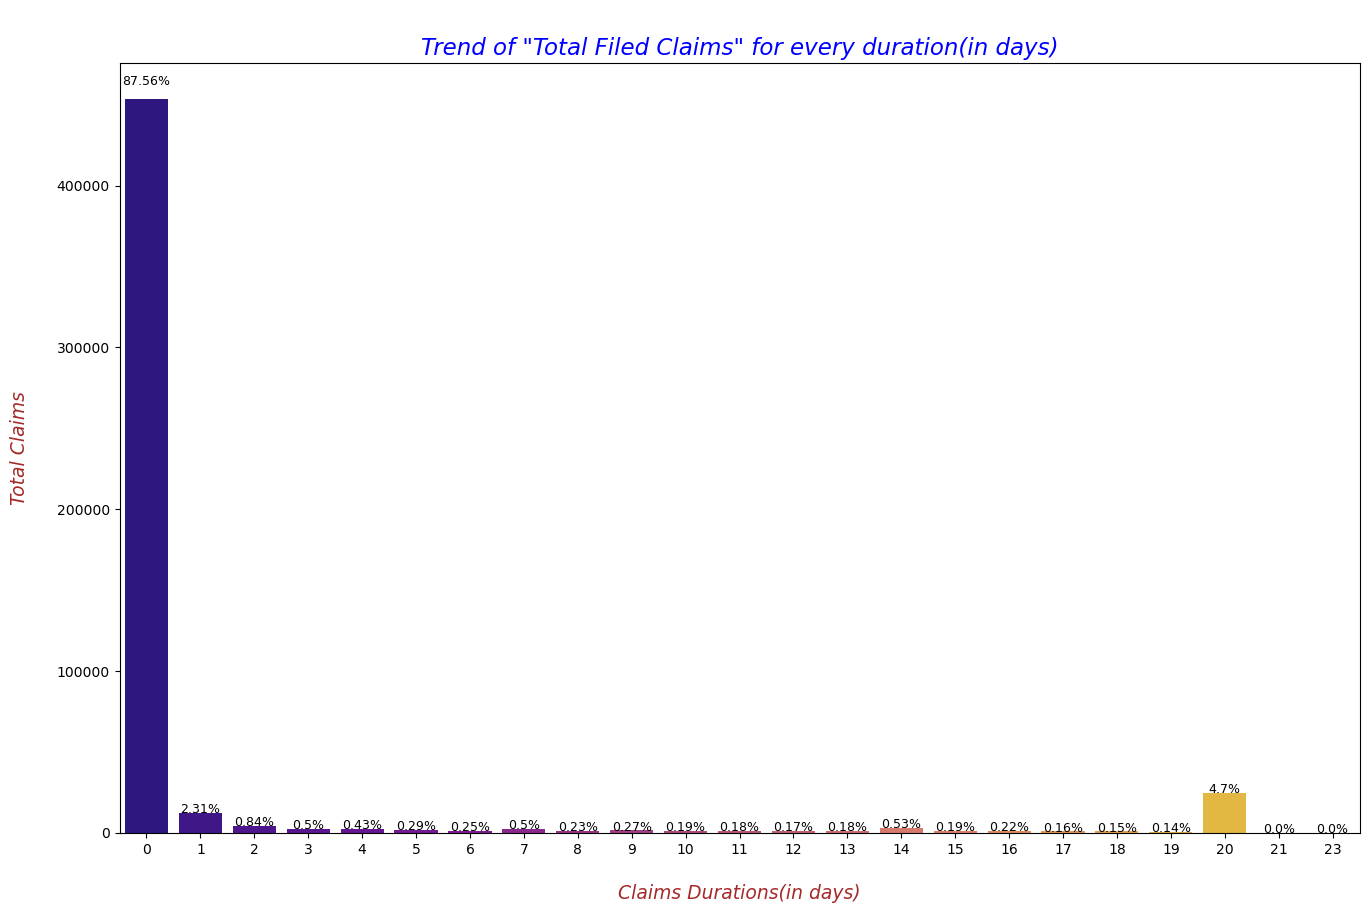

In [235]:
plt.figure(figsize=(16,10))
fig = sns.barplot(data=claim_clearance_amts, x='Claim_durations_in_days', y='Total_claims', palette='plasma')     
for p in fig.patches:
    width = p.get_width()
    height = p.get_height()
    x, y = p.get_xy()
    fig.annotate(f'{str(round((height*100)/claim_clearance_amts["Total_claims"].sum(),2))+"%"}', (x + width/2, y + height*1.02), ha='center', fontsize=9, rotation=0)

plt.xticks(rotation=0)
plt.xlabel("\nClaims Durations(in days)", fontdict= label_font_dict)
plt.ylabel("Total Claims\n", fontdict= label_font_dict)
plt.title('\nTrend of "Total Filed Claims" for every duration(in days)', fontdict=title_font_dict)
plt.show()

**`OBSERVATION`**
* The above graph tells us that the most number of claims are filed for 0 days. And, there are very less number of claims for other durations.
    * However, we can witness a litter spike for 20 days of duration for claims.

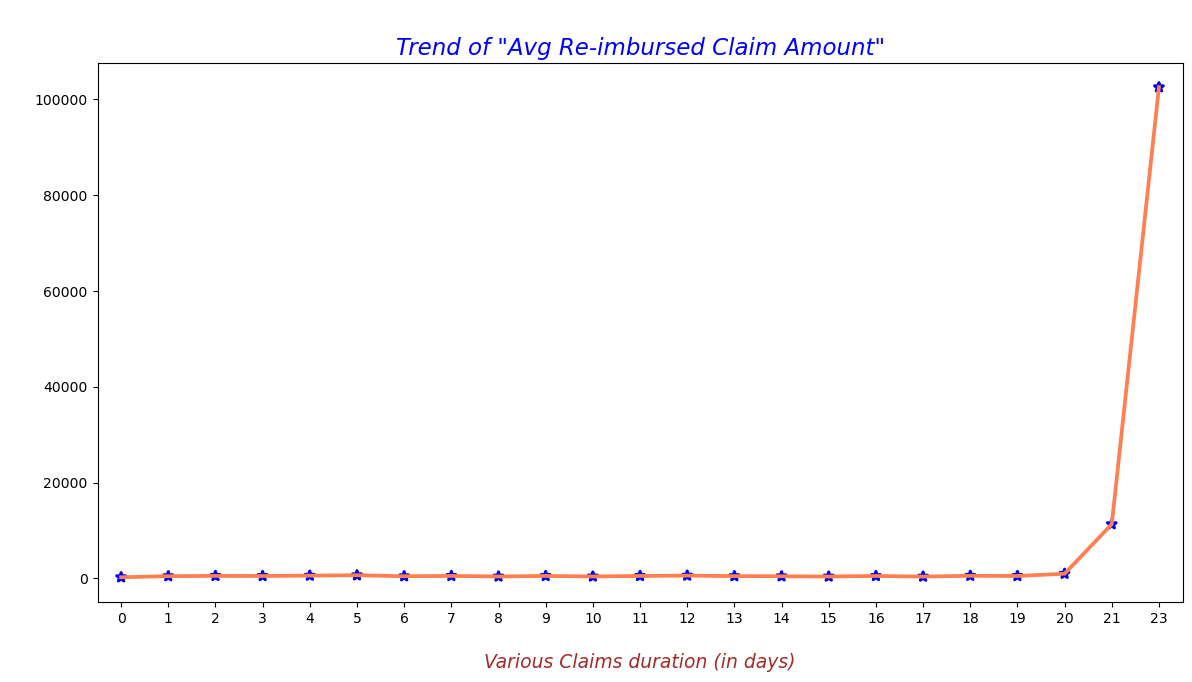

In [236]:
plt.figure(figsize=(14,7))
sns.pointplot(data=claim_clearance_amts, x='Claim_durations_in_days', y='Avg_Claim_Insc_Amount', 
              color='blue', markers="*", linestyles="")
sns.pointplot(data=claim_clearance_amts, x='Claim_durations_in_days', y='Avg_Claim_Insc_Amount', 
              color='coral', markers="", linestyles="-")

plt.xticks(rotation=0)
plt.xlabel("\nVarious Claims duration (in days)", fontdict= label_font_dict)
plt.ylabel(" ", fontdict= label_font_dict)
plt.title('\nTrend of "Avg Re-imbursed Claim Amount"', fontdict=title_font_dict)
plt.show()

**`OBSERVATION`**
* The above graph tells us that the Average Re-imbursed Amount is same throughout the various durations except for 21 and 23 days.

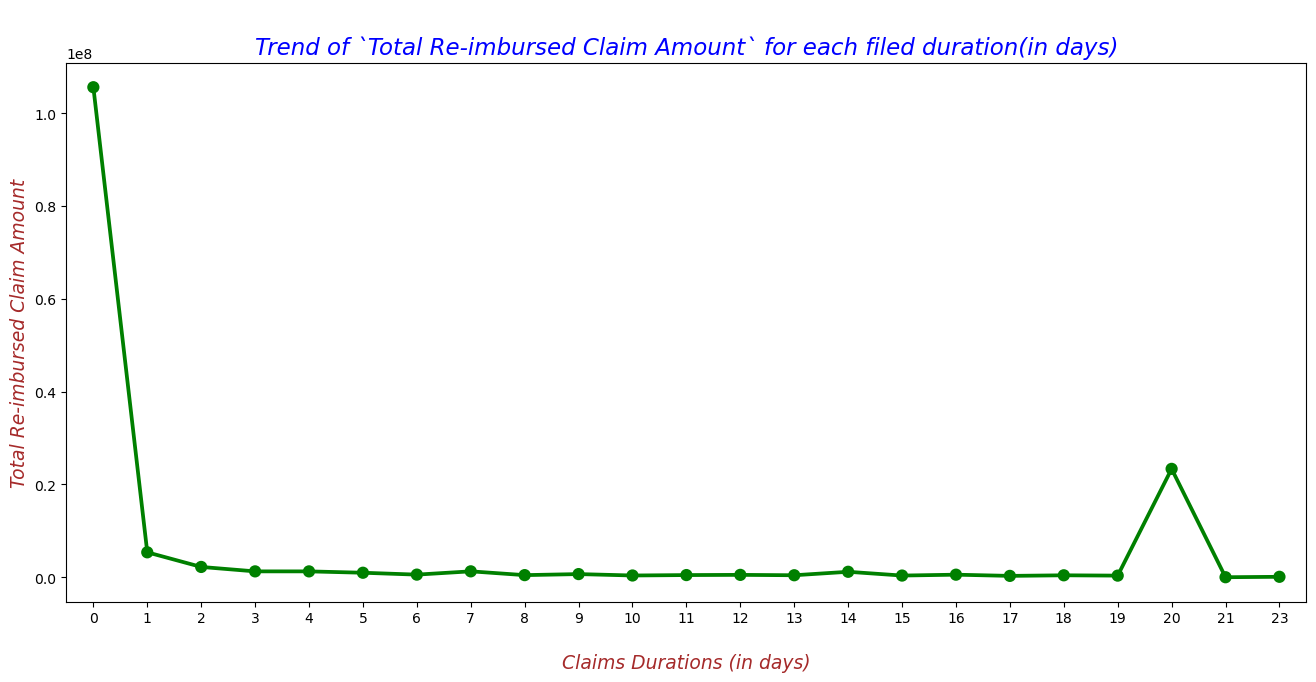

In [237]:
plt.figure(figsize=(16,7))
sns.pointplot(data=claim_clearance_amts, x='Claim_durations_in_days', y='All_Claims_Total_Amount', color='green')
plt.xticks(rotation=0)
plt.xlabel("\nClaims Durations (in days)", fontdict= label_font_dict)
plt.ylabel("Total Re-imbursed Claim Amount", fontdict= label_font_dict)
plt.title("\nTrend of `Total Re-imbursed Claim Amount` for each filed duration(in days)", fontdict=title_font_dict)
plt.show()

**`OBSERVATION`**
* The above graph tells us that the Total Re-imbursed Amount is the highest for 0 days claims.

* And, for claims with durations from 2 to 19 the total re-imbursed amount is very less or similar, however, for 20 days duration we can witness a clear spike that can be a potential sign of fraudulent.

### **Q7. What is the relationship b/w DeductibleAmtPaid and Re-imbursed Amount?**

In [238]:
no_of_claim_with_no_copay = op_train_df[op_train_df['DeductibleAmtPaid'] == 0].shape[0]
no_of_claim_with_no_copay

496701

In [239]:
no_of_claim_with_copay = op_train_df[op_train_df['DeductibleAmtPaid'] != 0].shape[0]
no_of_claim_with_copay

21036

In [240]:
percent_of_no_copay_claims = round((no_of_claim_with_no_copay / (no_of_claim_with_copay + no_of_claim_with_no_copay)) * 100,1)
print("Percentage of claims with no co-payment or deductible: {}% ".format(percent_of_no_copay_claims))

Percentage of claims with no co-payment or deductible: 95.9% 


In [241]:
re_imbursed_amt_for_no_copay = op_train_df[op_train_df['DeductibleAmtPaid'] == 0]['InscClaimAmtReimbursed'].sum()
re_imbursed_amt_for_no_copay

142391850

In [242]:
re_imbursed_amt_with_some_copay = op_train_df[op_train_df['DeductibleAmtPaid'] != 0]['InscClaimAmtReimbursed'].sum()
re_imbursed_amt_with_some_copay

5854270

In [243]:
tot_sum_of_claims_with_copay = re_imbursed_amt_with_some_copay / (re_imbursed_amt_with_some_copay + re_imbursed_amt_for_no_copay)
tot_sum_of_claims_with_no_copay = re_imbursed_amt_for_no_copay / (re_imbursed_amt_with_some_copay + re_imbursed_amt_for_no_copay)

In [244]:
percent_of_tot_sum_no_copay_claims_amt = round(tot_sum_of_claims_with_no_copay * 100,1)
print("Percentage of Total Re-imbursed Amount for claims with no co-payment or deductible: {}% ".\
      format(percent_of_tot_sum_no_copay_claims_amt))

Percentage of Total Re-imbursed Amount for claims with no co-payment or deductible: 96.1% 


**`OBSERVATION`**
* The above table tells us that there are 95.9% of total claims for which there is no co-payment.
    * And, for these 95.9% of total claims the total re-imbursed amount is 142.3 Million that is 96.1% of the total re-imbursed amount.

### **Q8. What is the relationship of Providers with Total number of claims filed & Re-imbursed Amount?**

In [245]:
# How many unique providers are there in the dataset?
print("We have {} unique number of Providers in the in-patient dataset.".format(op_train_df['Provider'].nunique()))

We have 5012 unique number of Providers in the in-patient dataset.


In [246]:
provider_tot_claims_filed = pd.DataFrame(op_train_df.groupby(['Provider'])['ClaimID'].count())
provider_tot_reimbursed_amt = pd.DataFrame(op_train_df.groupby(['Provider'])['InscClaimAmtReimbursed'].sum())

prv_tot_filed_claims_and_tot_reimb_amt = pd.merge(left=provider_tot_claims_filed, right=provider_tot_reimbursed_amt, how='inner',
                                                  left_on=provider_tot_claims_filed.index, right_on=provider_tot_reimbursed_amt.index)

prv_tot_filed_claims_and_tot_reimb_amt.columns = ['ProviderID', 'Tot_Claims_Filed', 'Tot_Re_Imbursed_Amt']
prv_tot_filed_claims_and_tot_reimb_amt.reset_index(drop=True,inplace=True)
prv_tot_filed_claims_and_tot_reimb_amt['Percentage_out_of_tot_reimb_amt'] = round((prv_tot_filed_claims_and_tot_reimb_amt['Tot_Re_Imbursed_Amt'] / op_train_df['InscClaimAmtReimbursed'].sum()) * 100, 3)

provider_max_reimbursed_amt = pd.DataFrame(op_train_df.groupby(['Provider'])['InscClaimAmtReimbursed'].max())
provider_max_reimbursed_amt.rename(columns={"InscClaimAmtReimbursed": "Max_Re_Imbursed_Amt"}, inplace=True)

prv_tot_filed_claims_tot_max_reimb_amt = pd.merge(left=prv_tot_filed_claims_and_tot_reimb_amt, 
                                                  right=provider_max_reimbursed_amt, how='inner',
                                                  left_on=prv_tot_filed_claims_and_tot_reimb_amt['ProviderID'], 
                                                  right_on=provider_max_reimbursed_amt.index)

prv_tot_filed_claims_tot_max_reimb_amt.drop(['key_0'], axis=1, inplace=True)
prv_tot_filed_claims_tot_max_reimb_amt['Diff_in_Tot_and_Max'] = prv_tot_filed_claims_tot_max_reimb_amt['Tot_Re_Imbursed_Amt'] - \
prv_tot_filed_claims_tot_max_reimb_amt['Max_Re_Imbursed_Amt']

prv_tot_filed_claims_tot_max_reimb_amt.head()

,ProviderID,Tot_Claims_Filed,Tot_Re_Imbursed_Amt,Percentage_out_of_tot_reimb_amt,Max_Re_Imbursed_Amt,Diff_in_Tot_and_Max
0,PRV51001,20,7640,0.005,1500,6140
1,PRV51003,70,32670,0.022,3300,29370
2,PRV51004,149,52170,0.035,3300,48870
3,PRV51005,1165,280910,0.189,4080,276830
4,PRV51007,69,14710,0.010,3300,11410


In [247]:
prv_tot_filed_claims_tot_max_reimb_amt.sort_values(by=['Diff_in_Tot_and_Max','Max_Re_Imbursed_Amt','Percentage_out_of_tot_reimb_amt'],
                                                   axis=0, inplace=True,
                                                   ascending=[True, False, False])

In [248]:
prv_tot_filed_claims_tot_max_reimb_amt.head(60)

,ProviderID,Tot_Claims_Filed,Tot_Re_Imbursed_Amt,Percentage_out_of_tot_reimb_amt,Max_Re_Imbursed_Amt,Diff_in_Tot_and_Max
82,PRV51119,1,95580,0.064,95580,0
2480,PRV54295,1,3300,0.002,3300,0
2485,PRV54302,1,3300,0.002,3300,0
3307,PRV55456,1,3300,0.002,3300,0
433,PRV51577,1,2100,0.001,2100,0
1473,PRV52954,1,2100,0.001,2100,0
4326,PRV56819,1,1900,0.001,1900,0
5010,PRV57762,1,1900,0.001,1900,0
521,PRV51689,1,1700,0.001,1700,0
3430,PRV55610,1,1700,0.001,1700,0


**`OBSERVATION`**
* The above table showing us the Provider Ids who only filed 1 or 2 claims and got the entire amount re-imbursed.
    * This, can be a potential sign of fraudulent because many small-small hospitals in rural area who don't have much facilities or equipments made fraud for benefits. 

In [249]:
tot_re_imb_amt_for_prv_with_5orless_claims = prv_tot_filed_claims_tot_max_reimb_amt[prv_tot_filed_claims_tot_max_reimb_amt['Tot_Claims_Filed'] < 5] \
                                            ['Tot_Re_Imbursed_Amt'].sum()

pp_re_imb_amt_for_prv_with_5orless_claims = round((tot_re_imb_amt_for_prv_with_5orless_claims / op_train_df['InscClaimAmtReimbursed'].sum()) * 100,2)
print("Total Re-imbursed Amount for Providers with less than 5 filed claims is: {} (0.52 Million). \n\
And, this is {}% of Total Re-imbursed Claim Amount (148 Million).".format(tot_re_imb_amt_for_prv_with_5orless_claims, 
                                                                    pp_re_imb_amt_for_prv_with_5orless_claims))

Total Re-imbursed Amount for Providers with less than 5 filed claims is: 522910 (0.52 Million). 
And, this is 0.35% of Total Re-imbursed Claim Amount (148 Million).


Exception in callback BaseSelectorEventLoop._read_from_self()
handle: <Handle BaseSelectorEventLoop._read_from_self()>
Traceback (most recent call last):
  File "C:\ProgramData\Anaconda3\lib\asyncio\events.py", line 80, in _run
    self._context.run(self._callback, *self._args)
  File "C:\ProgramData\Anaconda3\lib\asyncio\selector_events.py", line 115, in _read_from_self
    data = self._ssock.recv(4096)
ConnectionResetError: [WinError 10054] An existing connection was forcibly closed by the remote host
Exception in callback BaseSelectorEventLoop._read_from_self()
handle: <Handle BaseSelectorEventLoop._read_from_self()>
Traceback (most recent call last):
  File "C:\ProgramData\Anaconda3\lib\asyncio\events.py", line 80, in _run
    self._context.run(self._callback, *self._args)
  File "C:\ProgramData\Anaconda3\lib\asyncio\selector_events.py", line 115, in _read_from_self
    data = self._ssock.recv(4096)
ConnectionResetError: [WinError 10054] An existing connection was forcibly closed b

Exception in callback BaseSelectorEventLoop._read_from_self()
handle: <Handle BaseSelectorEventLoop._read_from_self()>
Traceback (most recent call last):
  File "C:\ProgramData\Anaconda3\lib\asyncio\events.py", line 80, in _run
    self._context.run(self._callback, *self._args)
  File "C:\ProgramData\Anaconda3\lib\asyncio\selector_events.py", line 115, in _read_from_self
    data = self._ssock.recv(4096)
ConnectionResetError: [WinError 10054] An existing connection was forcibly closed by the remote host
Exception in callback BaseSelectorEventLoop._read_from_self()
handle: <Handle BaseSelectorEventLoop._read_from_self()>
Traceback (most recent call last):
  File "C:\ProgramData\Anaconda3\lib\asyncio\events.py", line 80, in _run
    self._context.run(self._callback, *self._args)
  File "C:\ProgramData\Anaconda3\lib\asyncio\selector_events.py", line 115, in _read_from_self
    data = self._ssock.recv(4096)
ConnectionResetError: [WinError 10054] An existing connection was forcibly closed b

Exception in callback BaseSelectorEventLoop._read_from_self()
handle: <Handle BaseSelectorEventLoop._read_from_self()>
Traceback (most recent call last):
  File "C:\ProgramData\Anaconda3\lib\asyncio\events.py", line 80, in _run
    self._context.run(self._callback, *self._args)
  File "C:\ProgramData\Anaconda3\lib\asyncio\selector_events.py", line 115, in _read_from_self
    data = self._ssock.recv(4096)
ConnectionResetError: [WinError 10054] An existing connection was forcibly closed by the remote host
Exception in callback BaseSelectorEventLoop._read_from_self()
handle: <Handle BaseSelectorEventLoop._read_from_self()>
Traceback (most recent call last):
  File "C:\ProgramData\Anaconda3\lib\asyncio\events.py", line 80, in _run
    self._context.run(self._callback, *self._args)
  File "C:\ProgramData\Anaconda3\lib\asyncio\selector_events.py", line 115, in _read_from_self
    data = self._ssock.recv(4096)
ConnectionResetError: [WinError 10054] An existing connection was forcibly closed b

Exception in callback BaseSelectorEventLoop._read_from_self()
handle: <Handle BaseSelectorEventLoop._read_from_self()>
Traceback (most recent call last):
  File "C:\ProgramData\Anaconda3\lib\asyncio\events.py", line 80, in _run
    self._context.run(self._callback, *self._args)
  File "C:\ProgramData\Anaconda3\lib\asyncio\selector_events.py", line 115, in _read_from_self
    data = self._ssock.recv(4096)
ConnectionResetError: [WinError 10054] An existing connection was forcibly closed by the remote host
Exception in callback BaseSelectorEventLoop._read_from_self()
handle: <Handle BaseSelectorEventLoop._read_from_self()>
Traceback (most recent call last):
  File "C:\ProgramData\Anaconda3\lib\asyncio\events.py", line 80, in _run
    self._context.run(self._callback, *self._args)
  File "C:\ProgramData\Anaconda3\lib\asyncio\selector_events.py", line 115, in _read_from_self
    data = self._ssock.recv(4096)
ConnectionResetError: [WinError 10054] An existing connection was forcibly closed b

...

Exception in callback BaseSelectorEventLoop._read_from_self()
handle: <Handle BaseSelectorEventLoop._read_from_self()>
Traceback (most recent call last):
  File "C:\ProgramData\Anaconda3\lib\asyncio\events.py", line 80, in _run
    self._context.run(self._callback, *self._args)
  File "C:\ProgramData\Anaconda3\lib\asyncio\selector_events.py", line 115, in _read_from_self
    data = self._ssock.recv(4096)
ConnectionResetError: [WinError 10054] An existing connection was forcibly closed by the remote host
Exception in callback BaseSelectorEventLoop._read_from_self()
handle: <Handle BaseSelectorEventLoop._read_from_self()>
Traceback (most recent call last):
  File "C:\ProgramData\Anaconda3\lib\asyncio\events.py", line 80, in _run
    self._context.run(self._callback, *self._args)
  File "C:\ProgramData\Anaconda3\lib\asyncio\selector_events.py", line 115, in _read_from_self
    data = self._ssock.recv(4096)
ConnectionResetError: [WinError 10054] An existing connection was forcibly closed b

Exception in callback BaseSelectorEventLoop._read_from_self()
handle: <Handle BaseSelectorEventLoop._read_from_self()>
Traceback (most recent call last):
  File "C:\ProgramData\Anaconda3\lib\asyncio\events.py", line 80, in _run
    self._context.run(self._callback, *self._args)
  File "C:\ProgramData\Anaconda3\lib\asyncio\selector_events.py", line 115, in _read_from_self
    data = self._ssock.recv(4096)
ConnectionResetError: [WinError 10054] An existing connection was forcibly closed by the remote host
Exception in callback BaseSelectorEventLoop._read_from_self()
handle: <Handle BaseSelectorEventLoop._read_from_self()>
Traceback (most recent call last):
  File "C:\ProgramData\Anaconda3\lib\asyncio\events.py", line 80, in _run
    self._context.run(self._callback, *self._args)
  File "C:\ProgramData\Anaconda3\lib\asyncio\selector_events.py", line 115, in _read_from_self
    data = self._ssock.recv(4096)
ConnectionResetError: [WinError 10054] An existing connection was forcibly closed b

Exception in callback BaseSelectorEventLoop._read_from_self()
handle: <Handle BaseSelectorEventLoop._read_from_self()>
Traceback (most recent call last):
  File "C:\ProgramData\Anaconda3\lib\asyncio\events.py", line 80, in _run
    self._context.run(self._callback, *self._args)
  File "C:\ProgramData\Anaconda3\lib\asyncio\selector_events.py", line 115, in _read_from_self
    data = self._ssock.recv(4096)
ConnectionResetError: [WinError 10054] An existing connection was forcibly closed by the remote host
Exception in callback BaseSelectorEventLoop._read_from_self()
handle: <Handle BaseSelectorEventLoop._read_from_self()>
Traceback (most recent call last):
  File "C:\ProgramData\Anaconda3\lib\asyncio\events.py", line 80, in _run
    self._context.run(self._callback, *self._args)
  File "C:\ProgramData\Anaconda3\lib\asyncio\selector_events.py", line 115, in _read_from_self
    data = self._ssock.recv(4096)
ConnectionResetError: [WinError 10054] An existing connection was forcibly closed b

Exception in callback BaseSelectorEventLoop._read_from_self()
handle: <Handle BaseSelectorEventLoop._read_from_self()>
Traceback (most recent call last):
  File "C:\ProgramData\Anaconda3\lib\asyncio\events.py", line 80, in _run
    self._context.run(self._callback, *self._args)
  File "C:\ProgramData\Anaconda3\lib\asyncio\selector_events.py", line 115, in _read_from_self
    data = self._ssock.recv(4096)
ConnectionResetError: [WinError 10054] An existing connection was forcibly closed by the remote host
Exception in callback BaseSelectorEventLoop._read_from_self()
handle: <Handle BaseSelectorEventLoop._read_from_self()>
Traceback (most recent call last):
  File "C:\ProgramData\Anaconda3\lib\asyncio\events.py", line 80, in _run
    self._context.run(self._callback, *self._args)
  File "C:\ProgramData\Anaconda3\lib\asyncio\selector_events.py", line 115, in _read_from_self
    data = self._ssock.recv(4096)
ConnectionResetError: [WinError 10054] An existing connection was forcibly closed b

Exception in callback BaseSelectorEventLoop._read_from_self()
handle: <Handle BaseSelectorEventLoop._read_from_self()>
Traceback (most recent call last):
  File "C:\ProgramData\Anaconda3\lib\asyncio\events.py", line 80, in _run
    self._context.run(self._callback, *self._args)
  File "C:\ProgramData\Anaconda3\lib\asyncio\selector_events.py", line 115, in _read_from_self
    data = self._ssock.recv(4096)
ConnectionResetError: [WinError 10054] An existing connection was forcibly closed by the remote host
Exception in callback BaseSelectorEventLoop._read_from_self()
handle: <Handle BaseSelectorEventLoop._read_from_self()>
Traceback (most recent call last):
  File "C:\ProgramData\Anaconda3\lib\asyncio\events.py", line 80, in _run
    self._context.run(self._callback, *self._args)
  File "C:\ProgramData\Anaconda3\lib\asyncio\selector_events.py", line 115, in _read_from_self
    data = self._ssock.recv(4096)
ConnectionResetError: [WinError 10054] An existing connection was forcibly closed b

# **`IP & OP - EDA - SUMMARY`**

- Features to be added:
    - Claim Duration
    - Admitted Duration
    - Admitted or not?


- Relationships to be validated:
    - Providers <--> Physicians <--> Fraud or not?
    - Providers <--> Physicians <--> Diagnosis and Procedure Codes <--> Fraud or not?
    - Providers with very less number of claims submissions but higher Re-imbursed amount <--> Fraud or not?